# Informed (Heuristic) Search

The theory is in [README.md](./README.md) — what a heuristic is, admissibility and consistency,
and the analysis of each algorithm. This notebook is only the code.

The map is Romania: 20 cities, 23 roads, distances in miles. The goal is Bucharest and `h` is the
straight-line distance to Bucharest. Everything below the setup is a stub for you to fill in.

## Setup

In [1]:
from dataclasses import dataclass
from typing import Any
from collections import defaultdict

import heapq

import networkx as nx
import matplotlib.pyplot as plt

from IPython.display import clear_output

## The graph

Same `Node` and `make_graph` as last week. The `heuristic` field was there all along and sat at 0
for every node — this week it finally carries something.

In [2]:
@dataclass
class Node:
    value: Any = "no"
    heuristic: float = 0
    color: str = "white"


@dataclass
class Graph:
    nodes: Any
    edges: Any


def make_graph(nodes, edges):
    nodes = {v: Node(value=v, heuristic=h) for v, h in nodes}

    undirected_edges = defaultdict(list)
    for node, children in edges.items():
        for child, weight in children:
            undirected_edges[node].append((child, weight))
            undirected_edges[child].append((node, weight))

    return Graph(nodes=nodes, edges=undirected_edges)

## Drawing

Same helpers as last week, laid out by `spring_layout`. Twenty cities is a lot for one picture, so
the city names sit below their circles rather than inside them, and each one carries its `h`.

While you are debugging it is usually easier to print the frontier than to draw twenty pictures
per run. Draw once at the end.

In [3]:
# Straight-line distance to Bucharest. This is h(n): it cannot be worked out
# from the roads, it is knowledge about the world that we supply.
ROMANIA_H = {
    "Arad": 366,            "Mehadia": 241,
    "Bucharest": 0,         "Neamt": 234,
    "Craiova": 160,         "Oradea": 380,
    "Drobeta": 242,         "Pitesti": 100,
    "Eforie": 161,          "Rimnicu Vilcea": 193,
    "Fagaras": 176,         "Sibiu": 253,
    "Giurgiu": 77,          "Timisoara": 329,
    "Hirsova": 151,         "Urziceni": 80,
    "Iasi": 226,            "Vaslui": 199,
    "Lugoj": 244,           "Zerind": 374,
}

In [4]:
def draw_graph(graph, pos=None, seed=1, figsize=(14, 8)):
    nodes = graph.nodes.values()
    edges = []
    for node, children in graph.edges.items():
        for c, weight in children:
            edges.append((node, c, weight))

    G = nx.Graph()
    for n in nodes:
        G.add_node(n.value)
    for f, t, _ in edges:
        G.add_edge(f, t)

    if pos is None:
        pos = nx.spring_layout(G, seed=seed)

    fig, ax = plt.subplots(figsize=figsize)

    nx.draw_networkx_edges(G, pos, ax=ax, alpha=1, width=2)
    nx.draw_networkx_nodes(
        G,
        pos,
        ax=ax,
        nodelist=[n.value for n in nodes],
        node_size=520,
        node_color=[n.color for n in nodes],
        edgecolors="black",
        linewidths=0.9,
    )

    # Road numbers first, so the city names can sit on top of them.
    edge_labels = dict([((n1, n2), f"{w:g}") for n1, n2, w in edges])
    nx.draw_networkx_edge_labels(
        G, pos, ax=ax, edge_labels=edge_labels, label_pos=0.5, font_size=7,
        bbox=dict(boxstyle="round,pad=0.12", fc="white", ec="none", alpha=0.9),
    )

    # City names go below the circles, otherwise the long ones overlap. The
    # offset is a fraction of the layout's own size, so it works whatever
    # coordinates the layout produced.
    xs = [x for x, _ in pos.values()]
    ys = [y for _, y in pos.values()]
    span_x = (max(xs) - min(xs)) or 1.0
    span_y = (max(ys) - min(ys)) or 1.0

    label_pos = {name: (x, y - 0.055 * span_y) for name, (x, y) in pos.items()}
    nx.draw_networkx_labels(
        G,
        label_pos,
        ax=ax,
        labels={n.value: f"{n.value}\nh={n.heuristic:g}" for n in nodes},
        font_size=8,
        font_color="black",
        font_weight="bold",
        bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85),
    )

    # Leave room for the labels -- more below, since that is where they hang.
    # Then let the axes fill the whole figure: with the axis switched off, the
    # default margins around it are just blank paper.
    ax.set_xlim(min(xs) - 0.09 * span_x, max(xs) + 0.09 * span_x)
    ax.set_ylim(min(ys) - 0.16 * span_y, max(ys) + 0.07 * span_y)
    ax.set_axis_off()
    fig.subplots_adjust(left=0.01, right=0.99, top=0.99, bottom=0.01)
    plt.show()


def display_graph(g, current, seed=1):
    old_color_curr = g.nodes[current].color
    g.nodes[current].color = "red"
    draw_graph(g, seed=seed)
    g.nodes[current].color = old_color_curr


def reset_colors(g):
    for _, node in g.nodes.items():
        node.color = "white"

## The map

Each road is written once; `make_graph` adds the reverse direction. The number beside each city is
its straight-line distance to Bucharest.

In [5]:
romania = make_graph(
    nodes=list(ROMANIA_H.items()),
    edges={
        "Arad": [("Zerind", 75), ("Sibiu", 140), ("Timisoara", 118)],
        "Zerind": [("Oradea", 71)],
        "Oradea": [("Sibiu", 151)],
        "Timisoara": [("Lugoj", 111)],
        "Lugoj": [("Mehadia", 70)],
        "Mehadia": [("Drobeta", 75)],
        "Drobeta": [("Craiova", 120)],
        "Craiova": [("Rimnicu Vilcea", 146), ("Pitesti", 138)],
        "Sibiu": [("Fagaras", 99), ("Rimnicu Vilcea", 80)],
        "Rimnicu Vilcea": [("Pitesti", 97)],
        "Fagaras": [("Bucharest", 211)],
        "Pitesti": [("Bucharest", 101)],
        "Bucharest": [("Giurgiu", 90), ("Urziceni", 85)],
        "Urziceni": [("Hirsova", 98), ("Vaslui", 142)],
        "Hirsova": [("Eforie", 86)],
        "Vaslui": [("Iasi", 92)],
        "Iasi": [("Neamt", 87)],
    },
)

print(len(romania.nodes), "cities,", sum(len(v) for v in romania.edges.values()) // 2, "roads")

20 cities, 23 roads


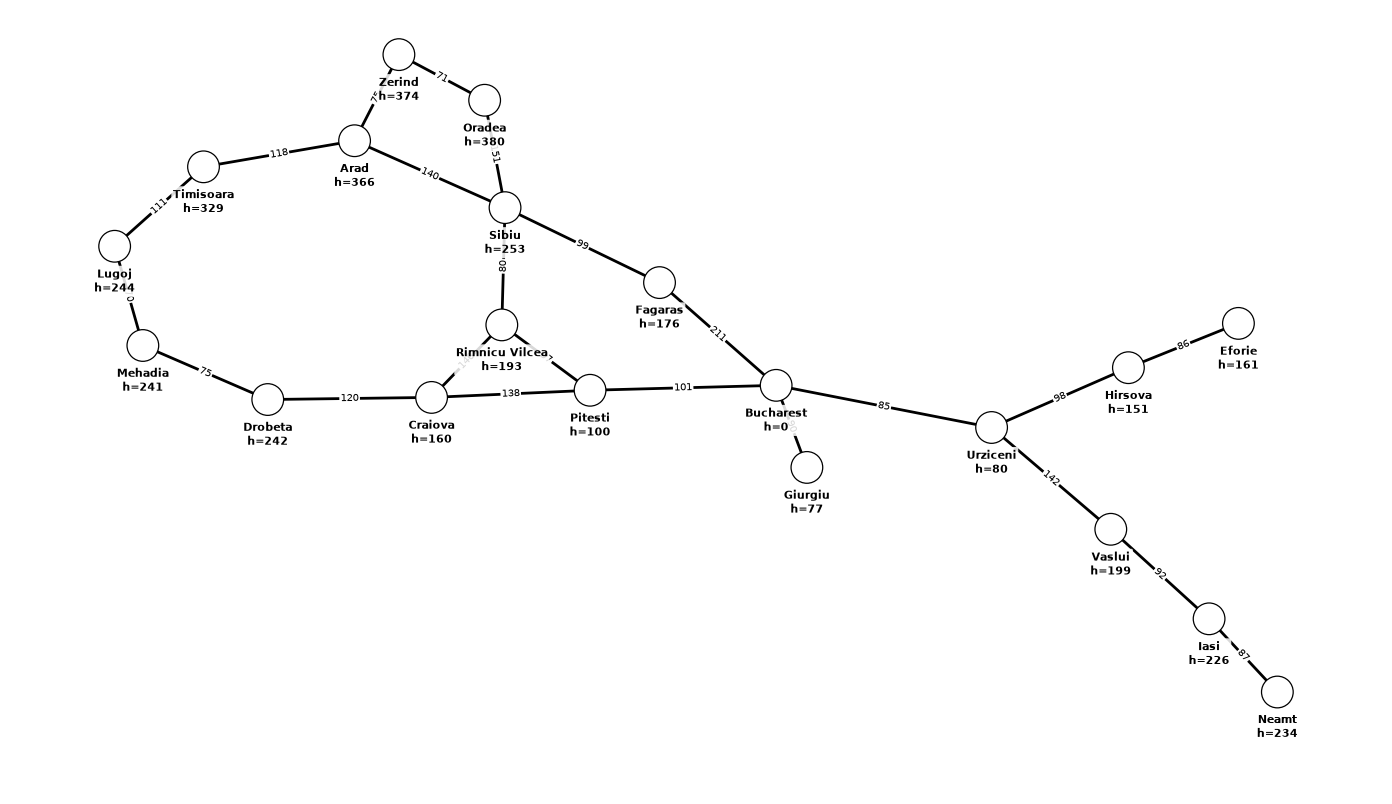

In [6]:
reset_colors(romania)
draw_graph(romania)

### Legend

`white` undiscovered &nbsp;·&nbsp; `gray` frontier &nbsp;·&nbsp; `red` currently expanding
&nbsp;·&nbsp; `blue` expanded &nbsp;·&nbsp; `green` goal

Same protocol as last week. Call `reset_colors(romania)` before each run and
`display_graph(romania, current)` once per expanded node.

Twenty cities means twenty pictures per run, so while you are debugging it is usually easier to
print the frontier instead and only draw once at the end.

## Checking the heuristic

Before trusting A\*, check that the heuristic deserves it. These are the two properties from the
README, written out as code — `h` must never overestimate the true road distance, and it must
satisfy the triangle inequality across every road.

This cell is given; you do not need to write it. Run it whenever you change a heuristic.

In [7]:
def true_distances(g, goal):
    """Cheapest road distance from every city to `goal`, by uniform-cost search."""
    dist = {goal: 0}
    pq = [(0, goal)]
    while pq:
        d, u = heapq.heappop(pq)
        if d > dist.get(u, float("inf")):
            continue
        for v, w in g.edges[u]:
            if d + w < dist.get(v, float("inf")):
                dist[v] = d + w
                heapq.heappush(pq, (dist[v], v))
    return dist


def check_heuristic(g, goal):
    dist = true_distances(g, goal)

    over = [(n.value, n.heuristic, dist[n.value])
            for n in g.nodes.values() if n.heuristic > dist[n.value]]
    print("admissible:", "yes" if not over else f"NO -- {over}")

    bad = []
    for u, children in g.edges.items():
        for v, w in children:
            if g.nodes[u].heuristic > w + g.nodes[v].heuristic:
                bad.append((u, v, w))
    print("consistent:", "yes" if not bad else f"NO -- {bad}")

    slack = sorted(((dist[n.value] - n.heuristic, n.value) for n in g.nodes.values()))
    print(f"tightest: {slack[1][1]} (off by {slack[1][0]})   "
          f"loosest: {slack[-1][1]} (off by {slack[-1][0]})")


check_heuristic(romania, "Bucharest")

admissible: yes
consistent: yes
tightest: Pitesti (off by 1)   loosest: Lugoj (off by 260)


## Greedy Best-First Search

`f(n) = h(n)`. Expand whatever looks closest to the goal, ignoring what the trip has cost so far.

Predict the answer before you run it. From Arad the greedy choice at Sibiu is Fagaras, because
176 beats 193 — but the route through Rimnicu Vilcea is the cheaper one. Greedy search should
return 450 where the best answer is 418.

In [8]:
def greedy_best_first(g, start, end):
    """Best-first search ordered by h(n) alone.

    Returns (path, cost), or (None, None) if there is no path.
    """
    # (priority, node, cost so far, the node we arrived from)
    priority_q = [(g.nodes[start].heuristic, start, 0, start)]

    pred = dict()

    while (len(priority_q) != 0):
        _, curr, dist, parent = heapq.heappop(priority_q)

        # A node can sit in the queue several times over. The first copy to come
        # out is the one we keep; ignore the rest.
        if g.nodes[curr].color == "blue":
            continue

        pred[curr] = parent

        if curr == end:
            path = []
            temp = end
            while temp != start:
                path.append(temp)
                temp = pred[temp]
            path.append(start)
            g.nodes[curr].color = "green"
            display_graph(g, curr)
            return (path[::-1], dist)

        for node, w in g.edges[curr]:
            if g.nodes[node].color != "blue":
                g.nodes[node].color = "gray"
                heapq.heappush(priority_q, (g.nodes[node].heuristic, node, dist + w, curr))

        display_graph(g, curr)
        g.nodes[curr].color = "blue"

    return (None, None)

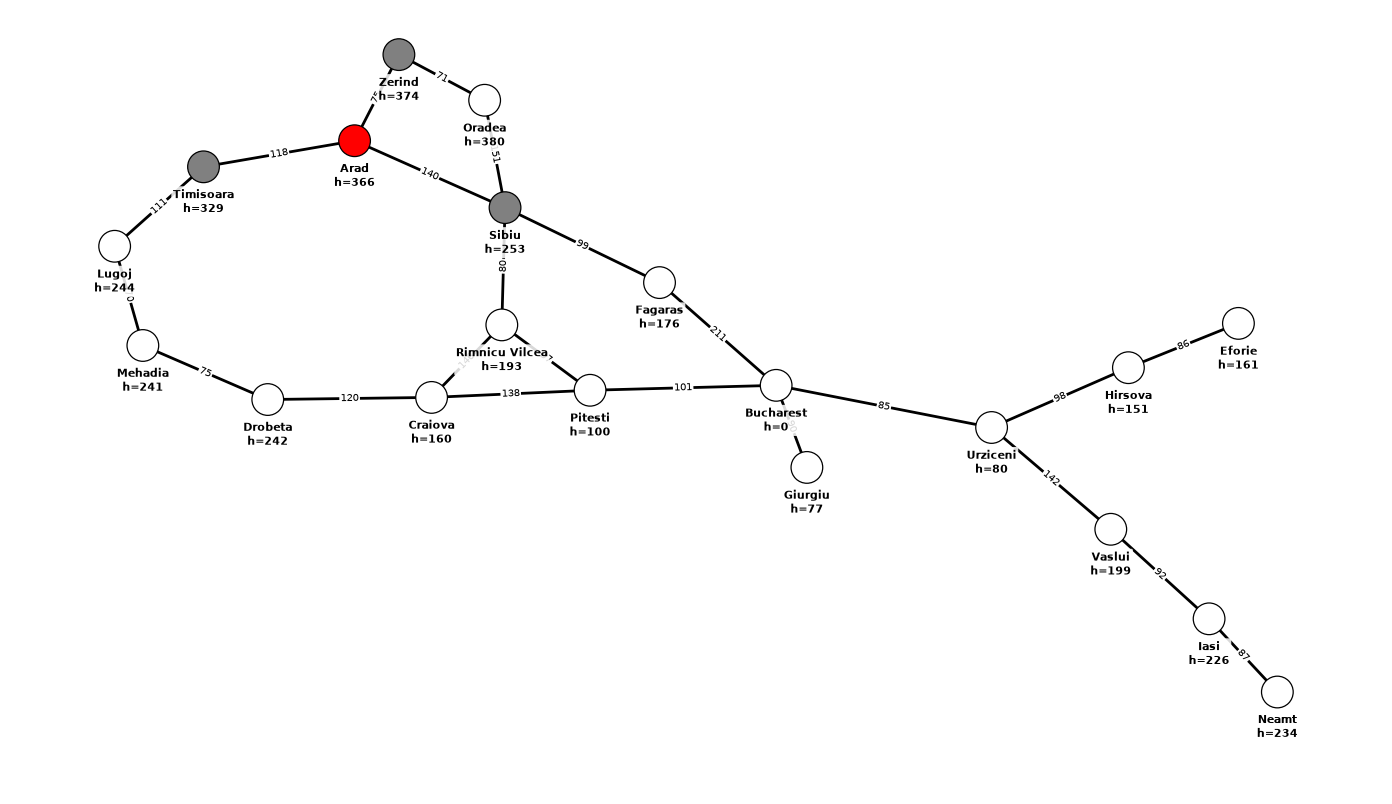

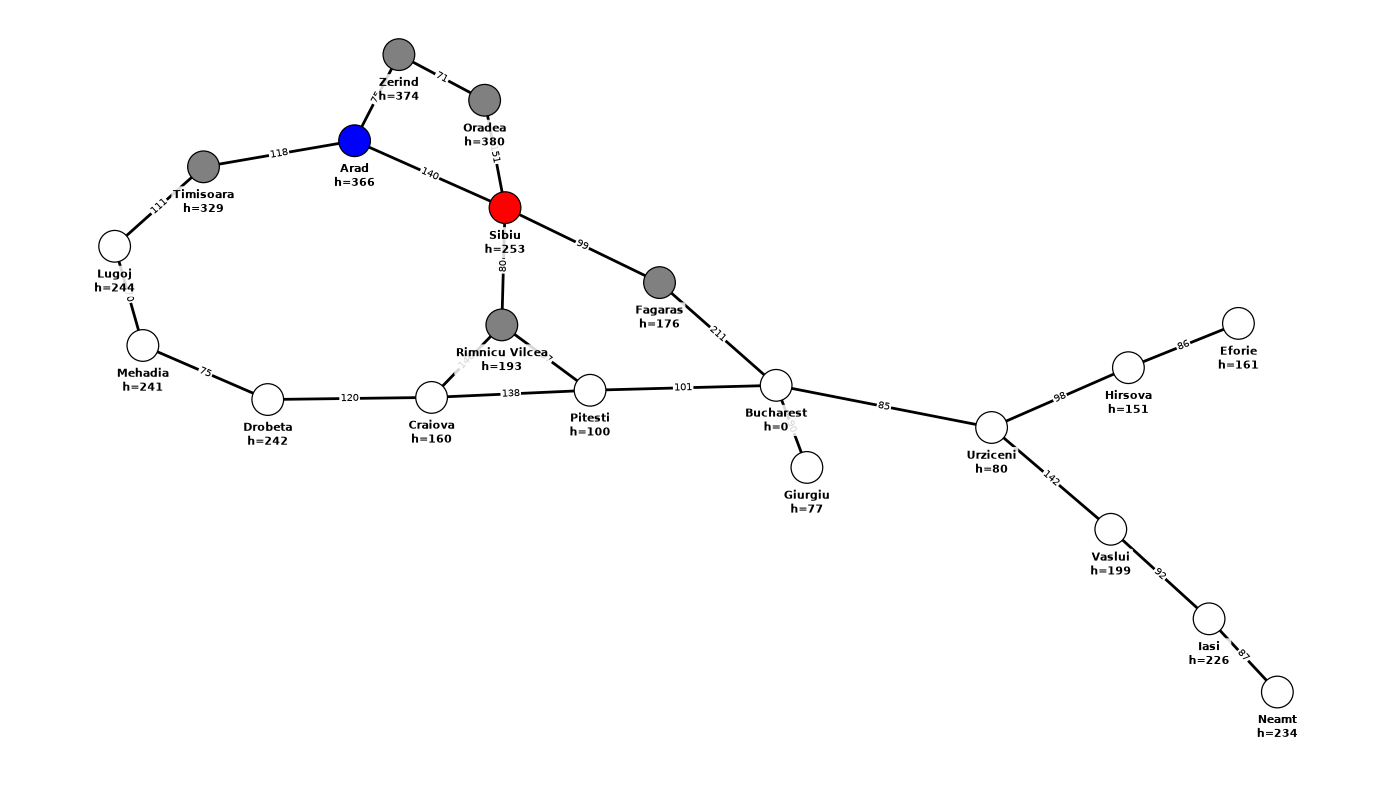

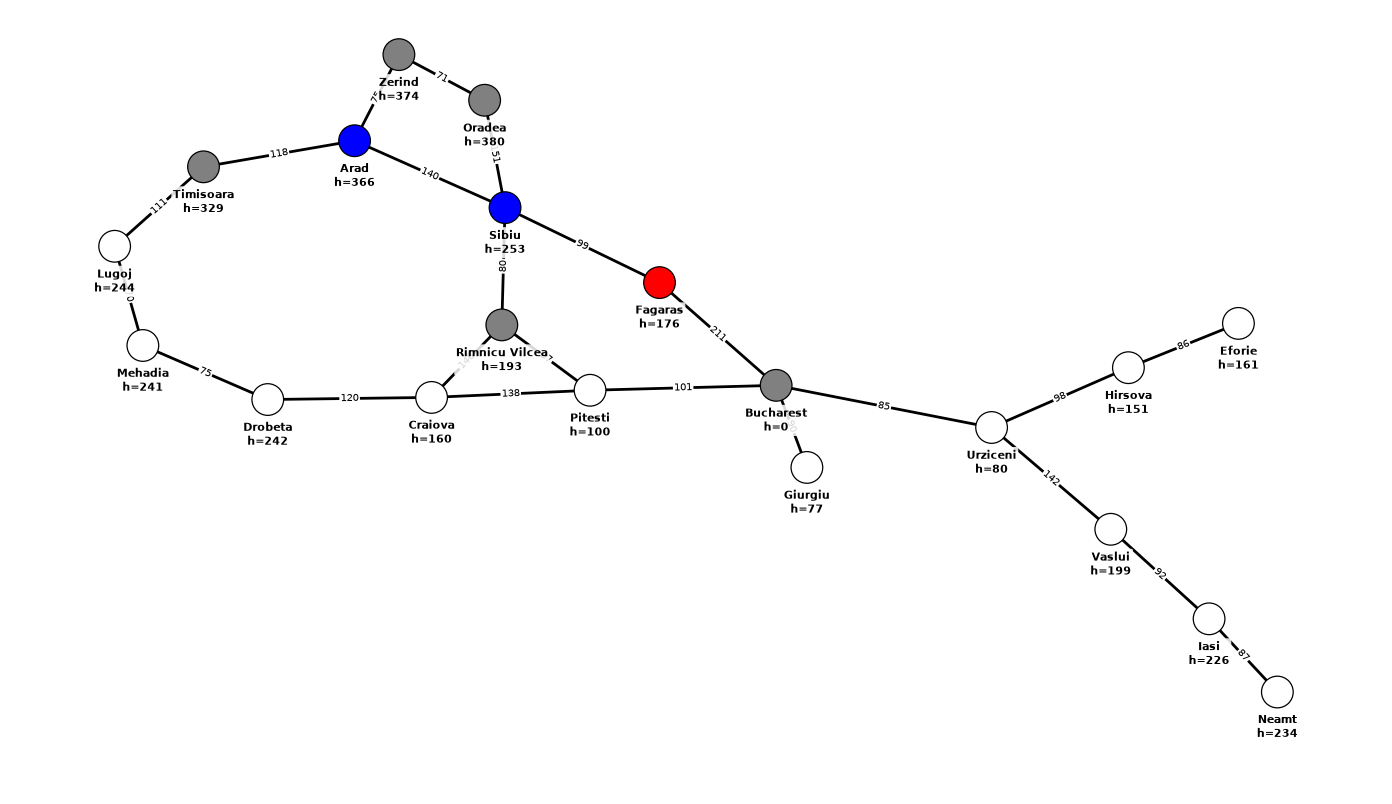

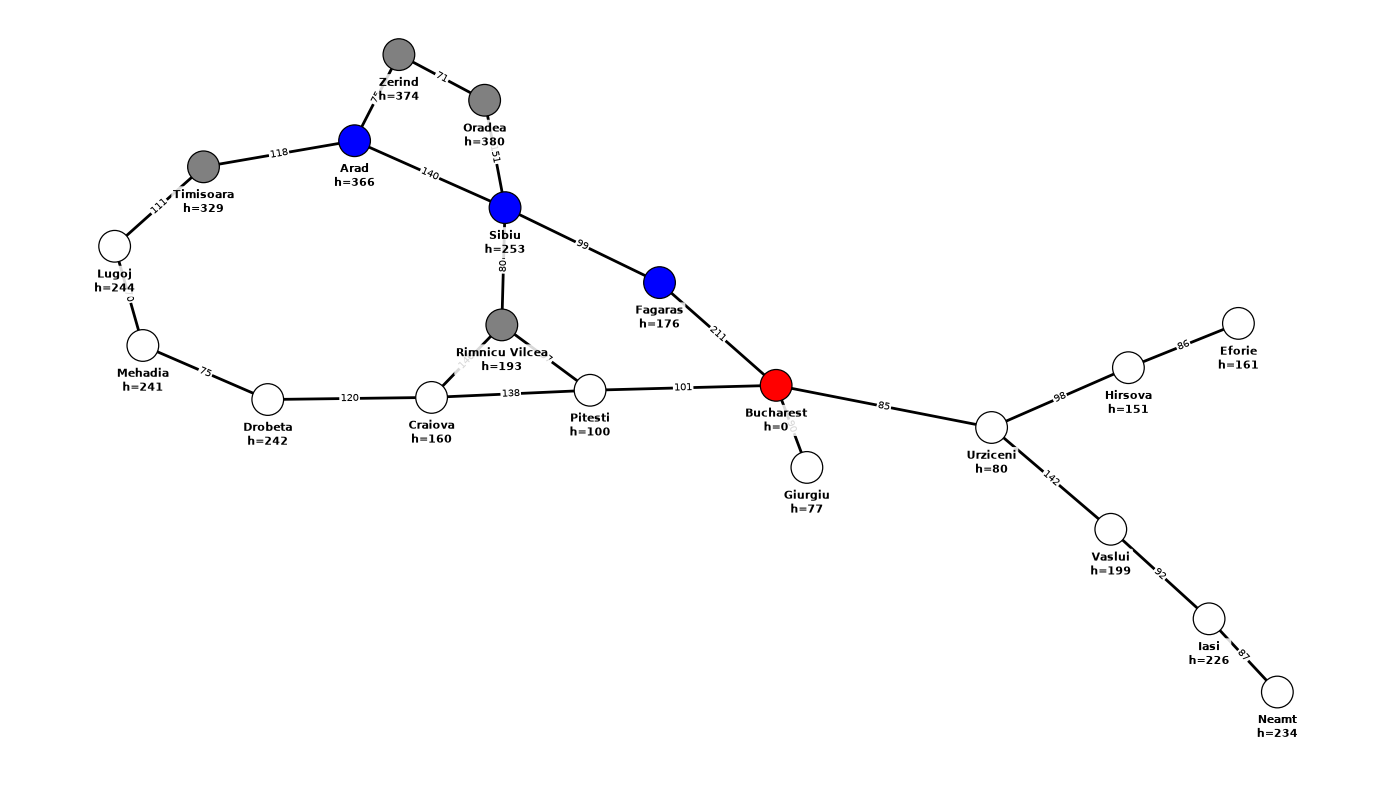

(['Arad', 'Sibiu', 'Fagaras', 'Bucharest'], 450)


In [9]:
reset_colors(romania)
print(greedy_best_first(romania, "Arad", "Bucharest"))

## A\*

`f(n) = g(n) + h(n)`. One extra term, and the guarantees change completely.

Two things to get right, and they are where the marks are:

- the priority is `g + h`, but the value you carry forward and add to is `g` alone
- when you pop a node you have already expanded, skip it — with a consistent heuristic the first
  expansion already had the cheapest route to it

In [14]:
def a_star(g, start, end):
    """A* search, ordered by f(n) = g(n) + h(n).

    Returns (path, cost), or (None, None) if there is no path.
    """
    priority_q = [(g.nodes[start].heuristic, start, 0, start)]

    pred = dict()

    while (len(priority_q) != 0):
        print(priority_q)
        _, curr, dist, parent = heapq.heappop(priority_q)

        if g.nodes[curr].color == "blue":
            continue

        pred[curr] = parent

        if curr == end:
            path = []
            temp = end
            while temp != start:
                path.append(temp)
                temp = pred[temp]
            path.append(start)
            g.nodes[curr].color = "green"
            display_graph(g, curr)
            return (path[::-1], dist)

        for node, w in g.edges[curr]:
            if g.nodes[node].color != "blue":
                g.nodes[node].color = "gray"
                heapq.heappush(
                    priority_q,
                    (dist + w + g.nodes[node].heuristic, node, dist + w, curr),
                )

        display_graph(g, curr)
        g.nodes[curr].color = "blue"

    return (None, None)

[(366, 'Arad', 0, 'Arad')]


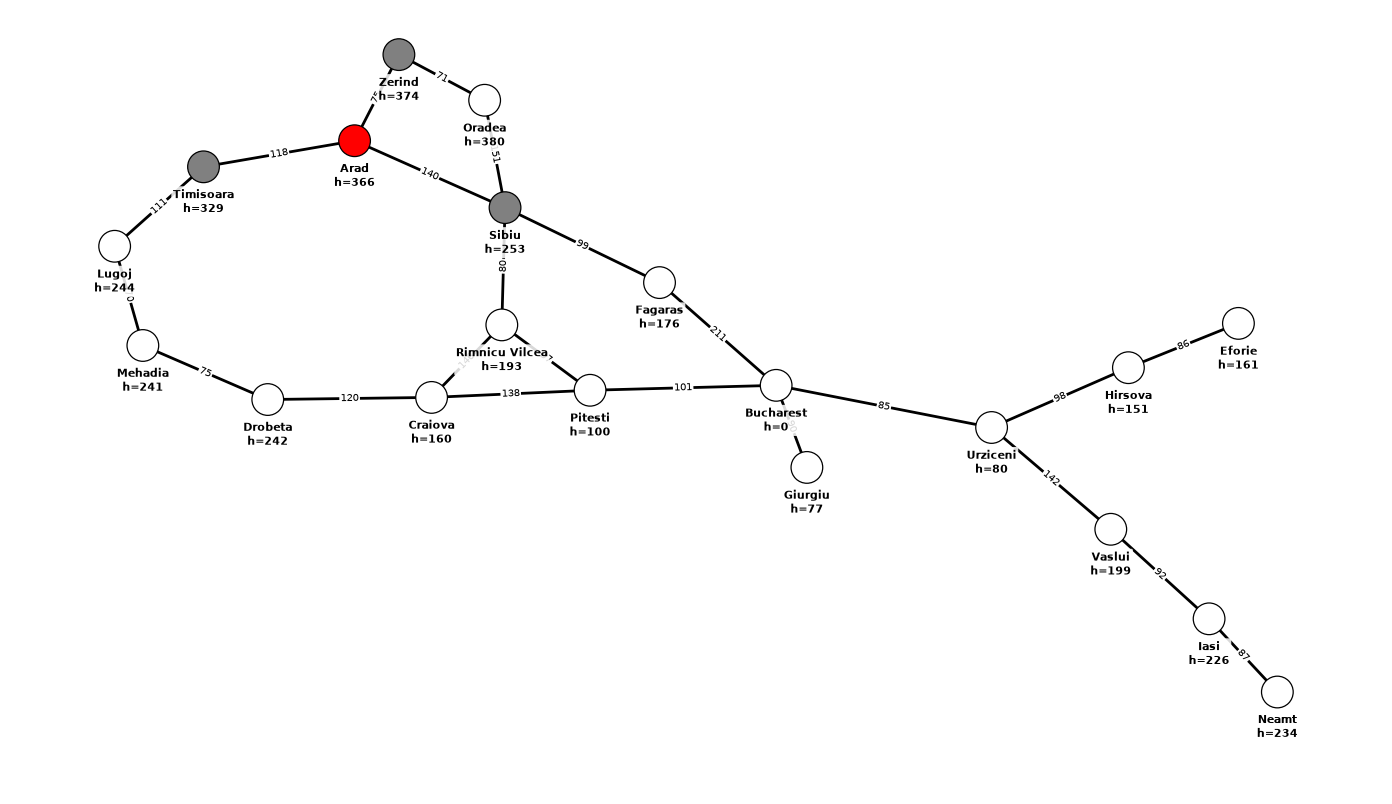

[(393, 'Sibiu', 140, 'Arad'), (449, 'Zerind', 75, 'Arad'), (447, 'Timisoara', 118, 'Arad')]


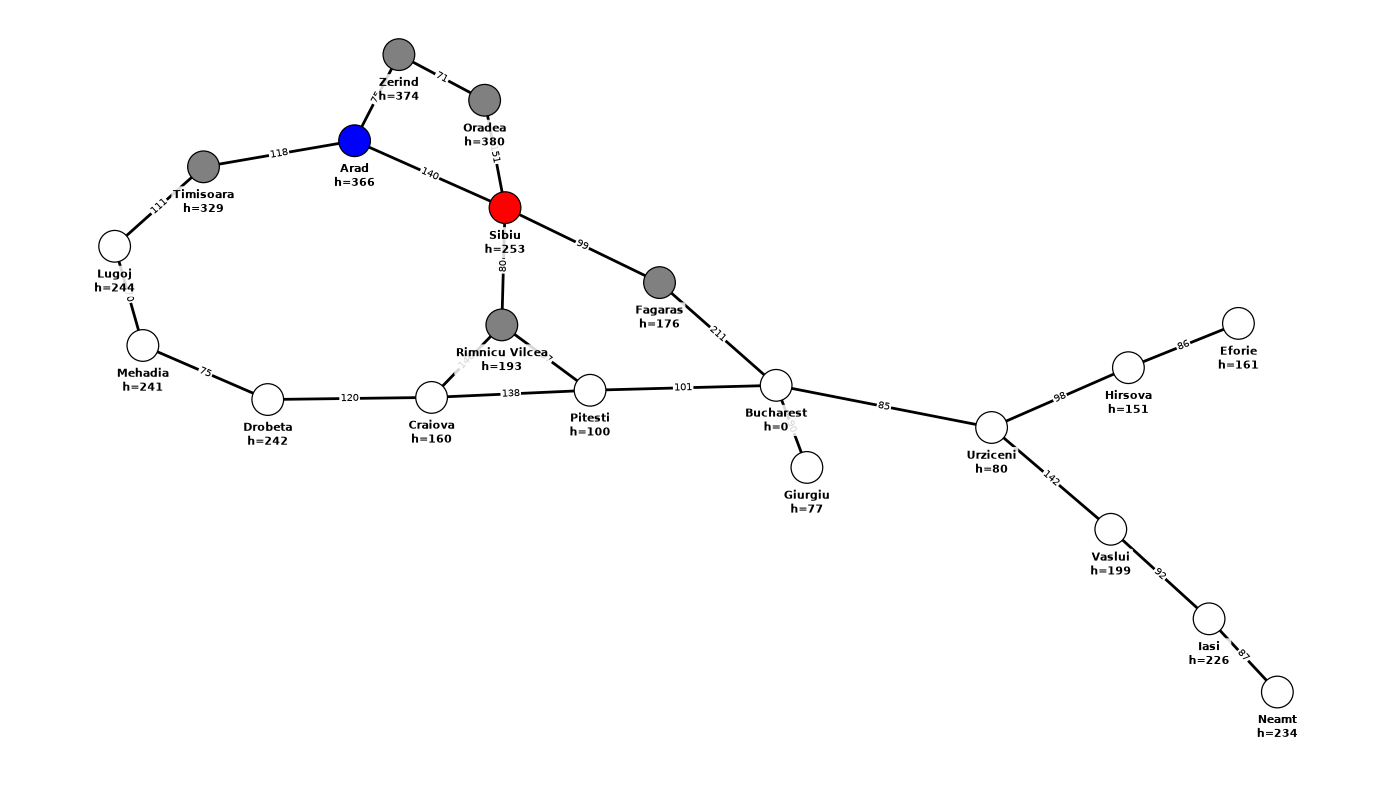

[(413, 'Rimnicu Vilcea', 220, 'Sibiu'), (415, 'Fagaras', 239, 'Sibiu'), (671, 'Oradea', 291, 'Sibiu'), (449, 'Zerind', 75, 'Arad'), (447, 'Timisoara', 118, 'Arad')]


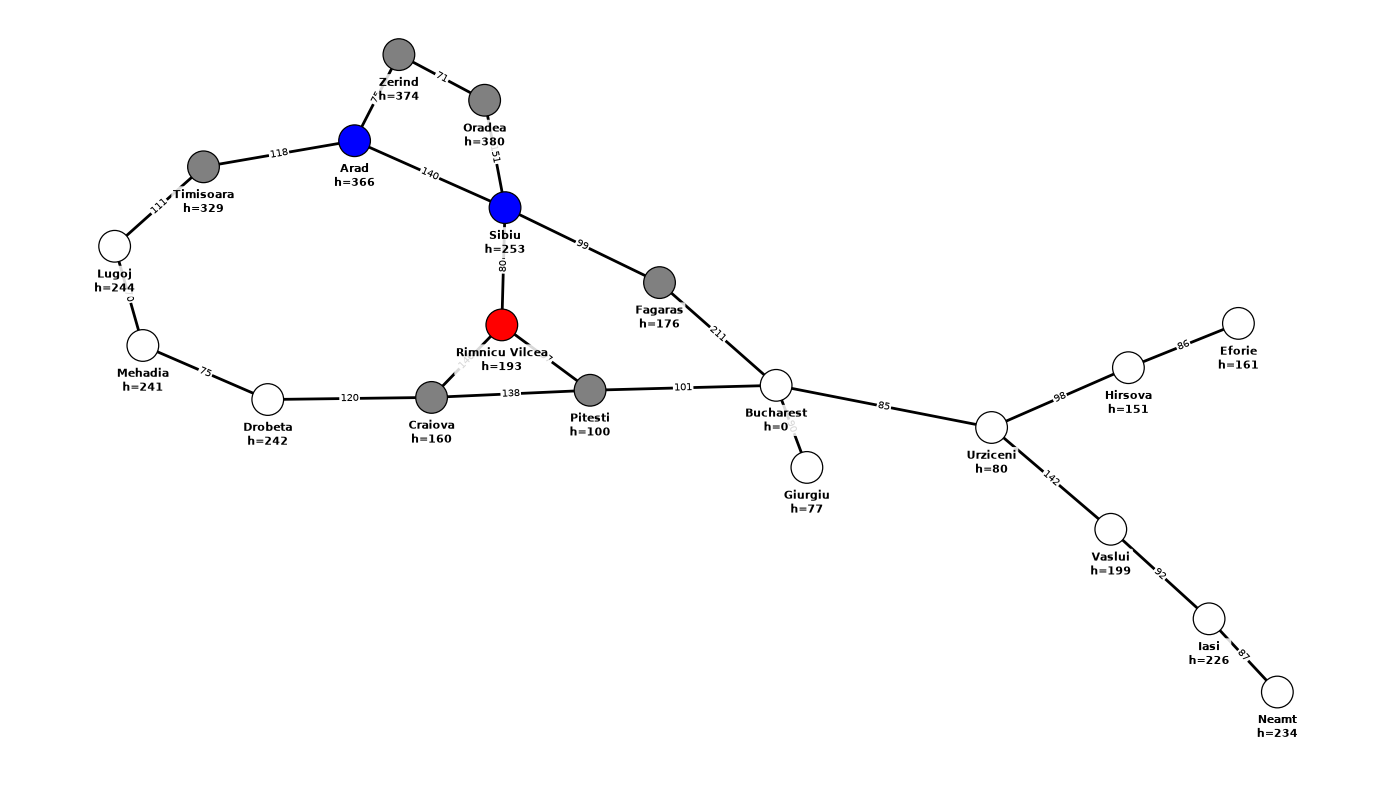

[(415, 'Fagaras', 239, 'Sibiu'), (447, 'Timisoara', 118, 'Arad'), (417, 'Pitesti', 317, 'Rimnicu Vilcea'), (449, 'Zerind', 75, 'Arad'), (526, 'Craiova', 366, 'Rimnicu Vilcea'), (671, 'Oradea', 291, 'Sibiu')]


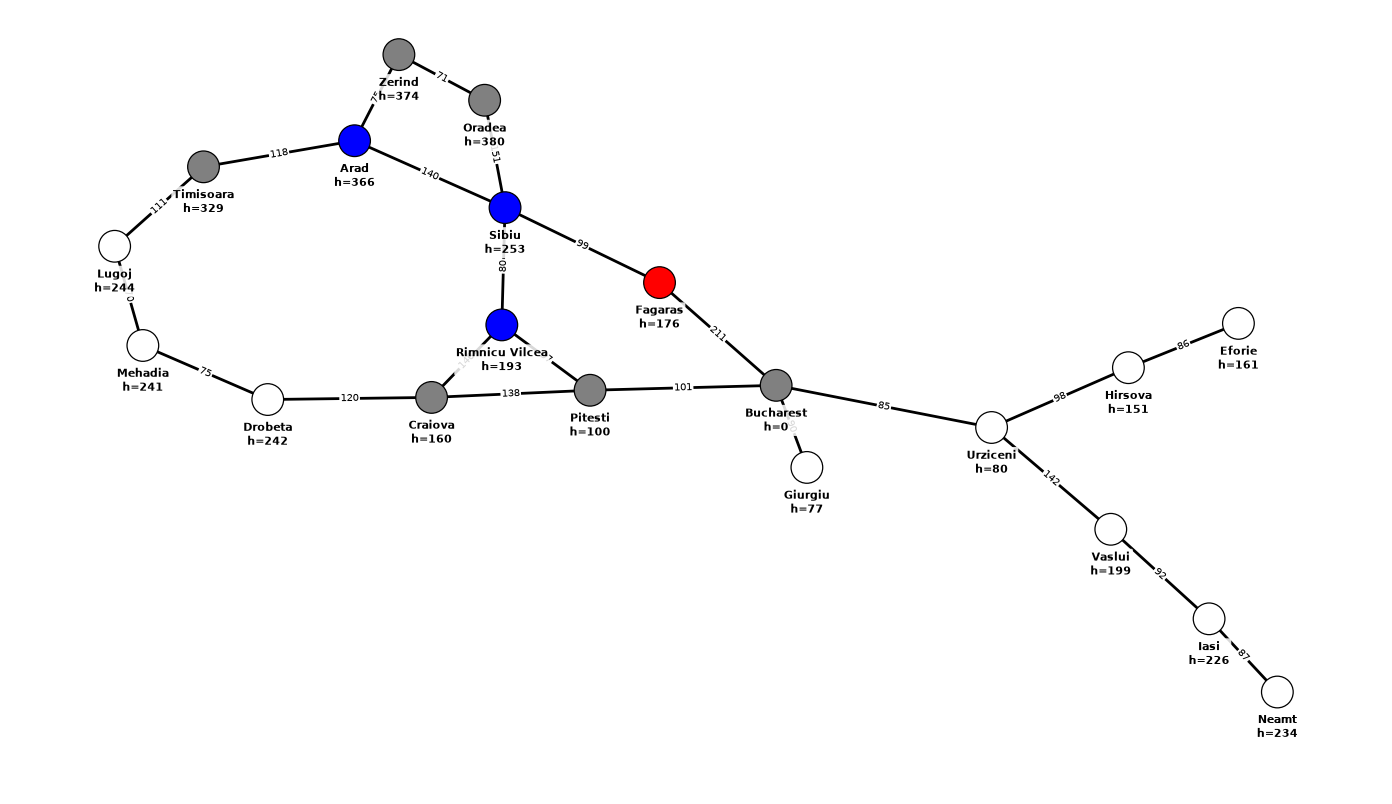

[(417, 'Pitesti', 317, 'Rimnicu Vilcea'), (447, 'Timisoara', 118, 'Arad'), (450, 'Bucharest', 450, 'Fagaras'), (449, 'Zerind', 75, 'Arad'), (526, 'Craiova', 366, 'Rimnicu Vilcea'), (671, 'Oradea', 291, 'Sibiu')]


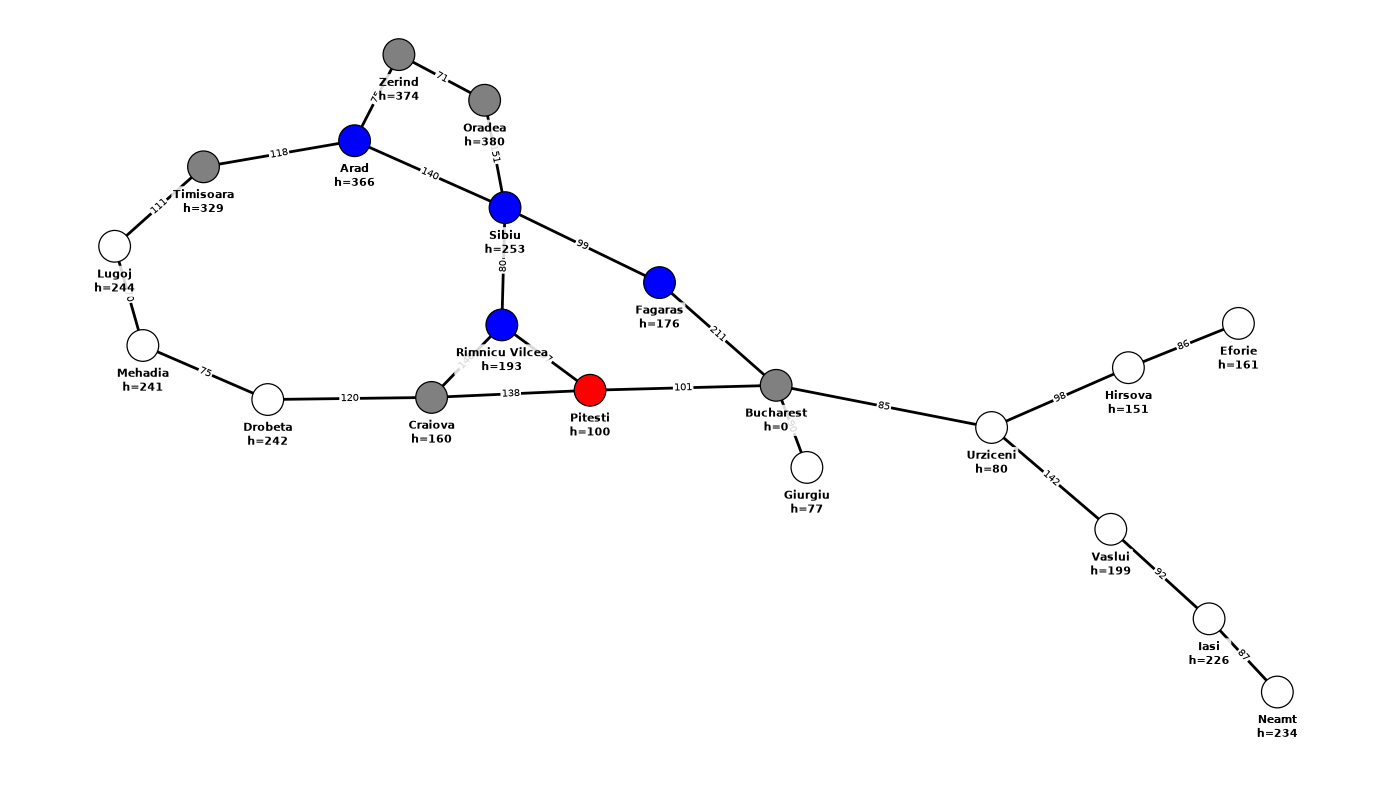

[(418, 'Bucharest', 418, 'Pitesti'), (449, 'Zerind', 75, 'Arad'), (447, 'Timisoara', 118, 'Arad'), (671, 'Oradea', 291, 'Sibiu'), (526, 'Craiova', 366, 'Rimnicu Vilcea'), (615, 'Craiova', 455, 'Pitesti'), (450, 'Bucharest', 450, 'Fagaras')]


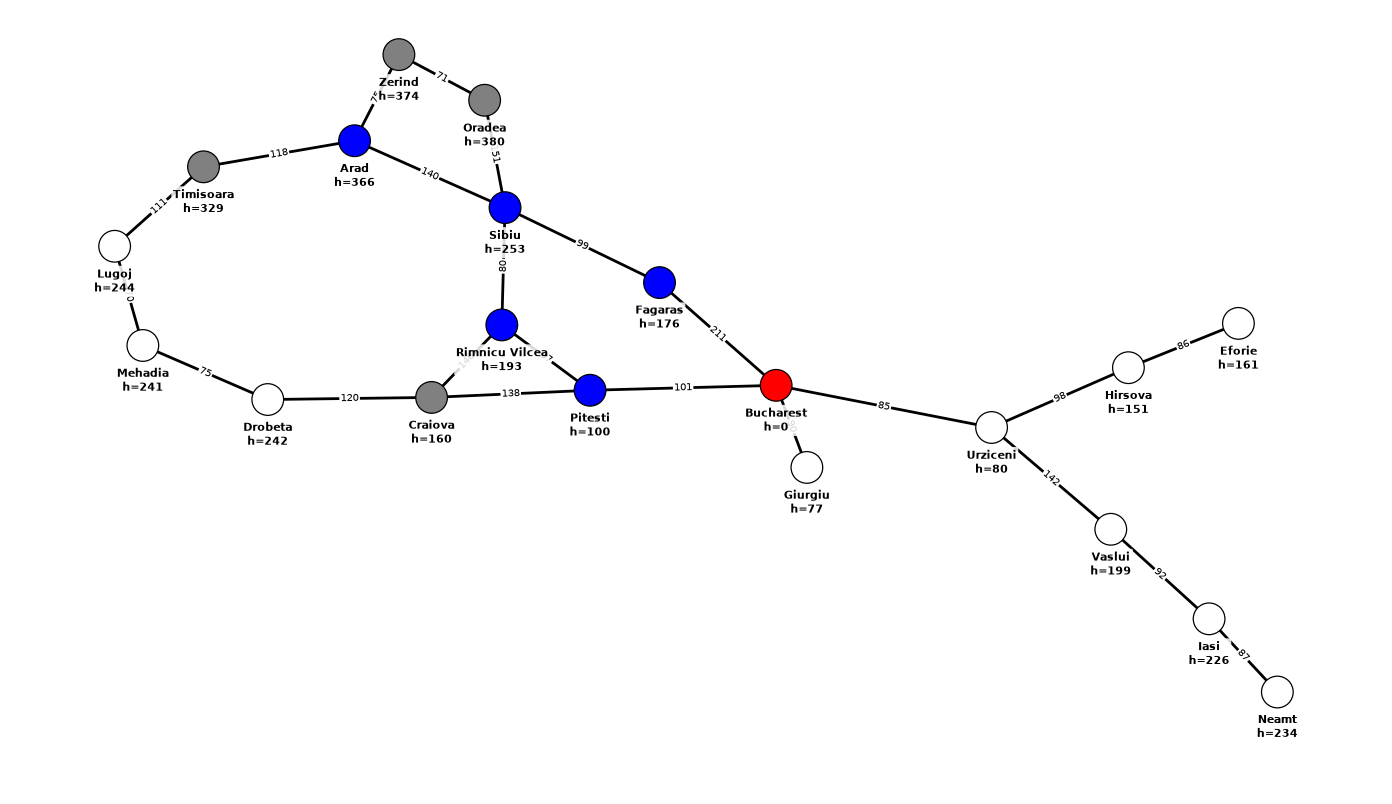

(['Arad', 'Sibiu', 'Rimnicu Vilcea', 'Pitesti', 'Bucharest'], 418)

In [15]:
reset_colors(romania)
a_star(romania, "Arad", "Bucharest")

## Beam Search

Best-first search that keeps only the `k` most promising nodes in the frontier and discards the
rest, so memory stays constant no matter how big the map is.

Try it with `k = 1` and `k = 2`. At `k = 1` it is hill climbing and it can strand itself; the
interesting question is the smallest `k` that still finds Bucharest from Arad.

In [16]:
def beam_search(g, start, end, k=2):
    """Best-first search with a frontier capped at `k` nodes.

    After generating the successors of the current level, keep only the k best
    by f(n) and throw the rest away.

    Returns (path, cost), or (None, None) if the goal was pruned away or is
    unreachable.
    """
    priority_q = [(g.nodes[start].heuristic, start, 0, start)]

    pred = dict()

    while (len(priority_q) != 0):
        print(priority_q)
        _, curr, dist, parent = heapq.heappop(priority_q)

        if g.nodes[curr].color == "blue":
            continue

        pred[curr] = parent

        if curr == end:
            path = []
            temp = end
            while temp != start:
                path.append(temp)
                temp = pred[temp]
            path.append(start)
            g.nodes[curr].color = "green"
            display_graph(g, curr)
            return (path[::-1], dist)

        for node, w in g.edges[curr]:
            if g.nodes[node].color != "blue":
                g.nodes[node].color = "gray"
                heapq.heappush(priority_q, (g.nodes[node].heuristic, node, dist + w, curr))

        # This is the line that makes it beam search: the whole frontier is cut
        # down to its k most promising entries and the rest are gone for good.
        priority_q = heapq.nsmallest(k, priority_q)
        heapq.heapify(priority_q)

        display_graph(g, curr)
        g.nodes[curr].color = "blue"

    return (None, None)

[(366, 'Arad', 0, 'Arad')]


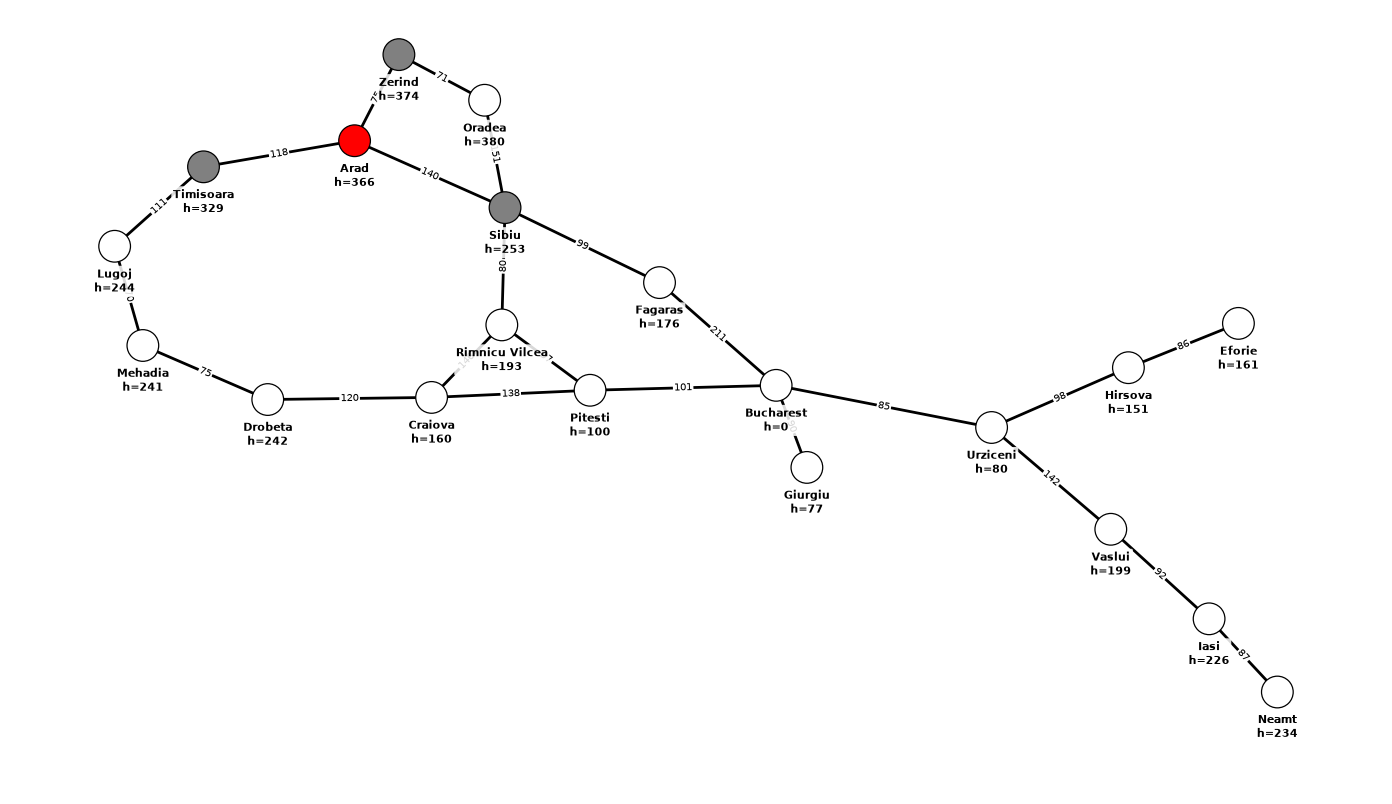

[(253, 'Sibiu', 140, 'Arad'), (329, 'Timisoara', 118, 'Arad')]


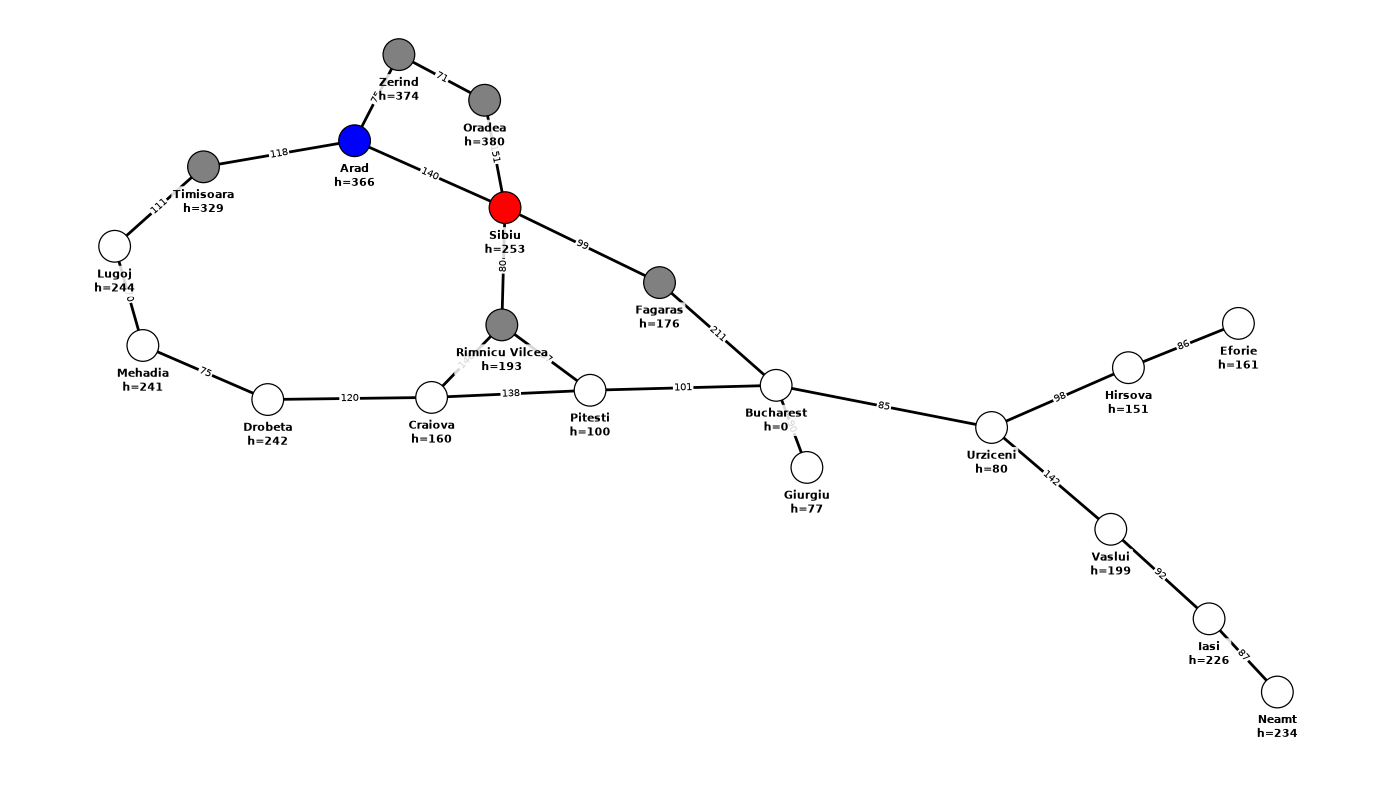

[(176, 'Fagaras', 239, 'Sibiu'), (193, 'Rimnicu Vilcea', 220, 'Sibiu')]


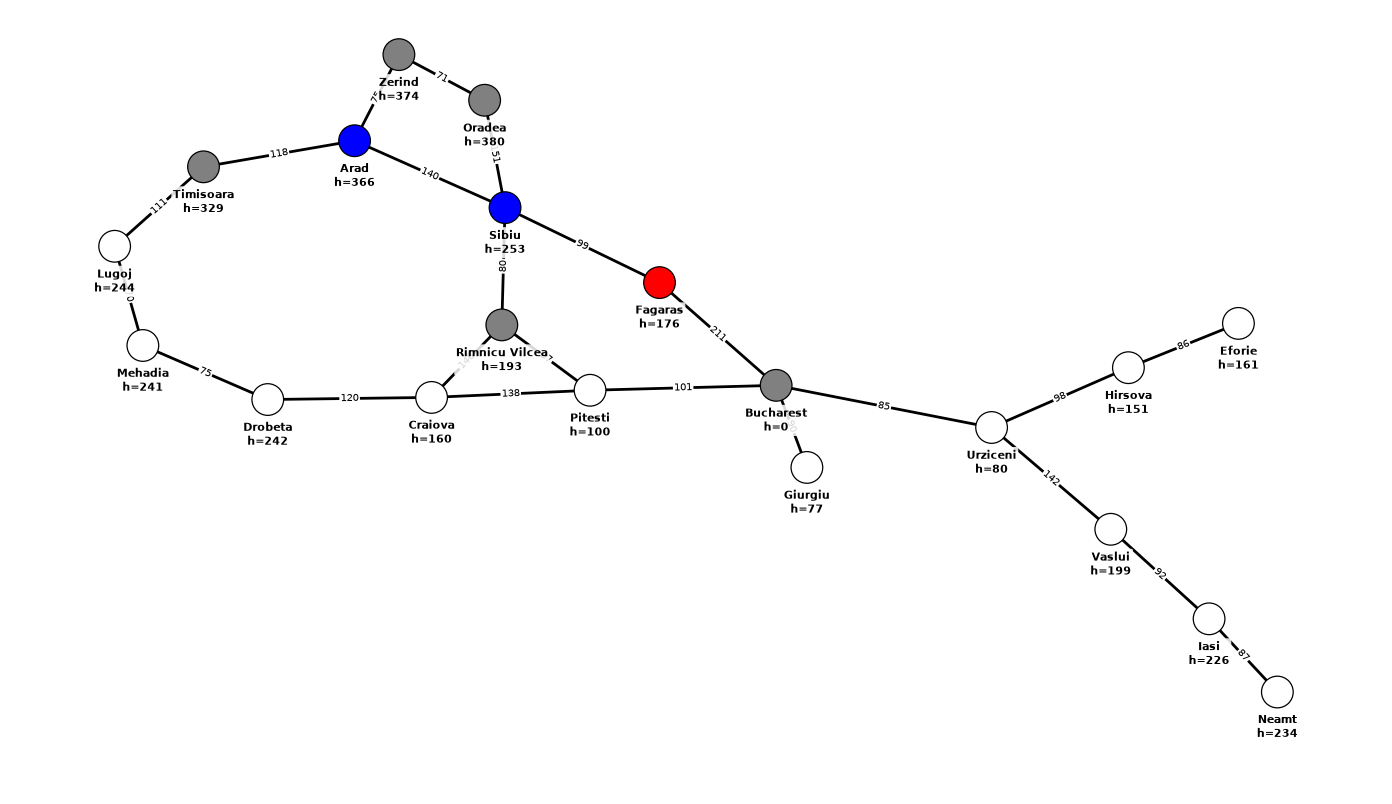

[(0, 'Bucharest', 450, 'Fagaras'), (193, 'Rimnicu Vilcea', 220, 'Sibiu')]


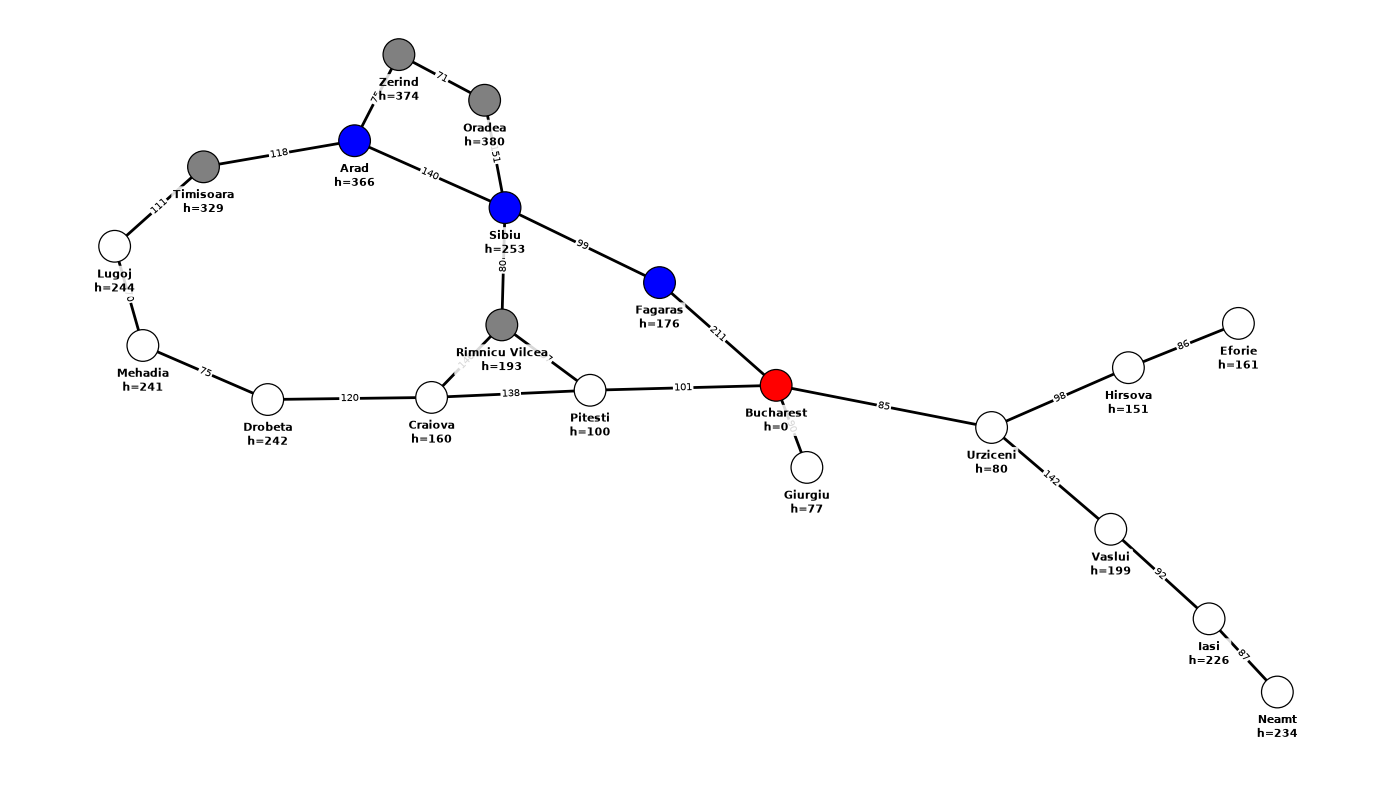

(['Arad', 'Sibiu', 'Fagaras', 'Bucharest'], 450)

In [17]:
reset_colors(romania)
beam_search(romania, "Arad", "Bucharest", k=2)

## Hill Climbing

Beam search with `k = 1`: move to the best successor and forget everything else. No frontier, no
backtracking, and memory that does not grow with the problem.

It is not really a path-finding algorithm — it is an optimisation algorithm pointed at a graph,
and it fails wherever the landscape has a bump in the way. The cell below draws the shapes that
trap it. Hill climbing only ever sees the ground immediately under its feet, so a local maximum,
a shoulder and a plateau are all indistinguishable from the summit.

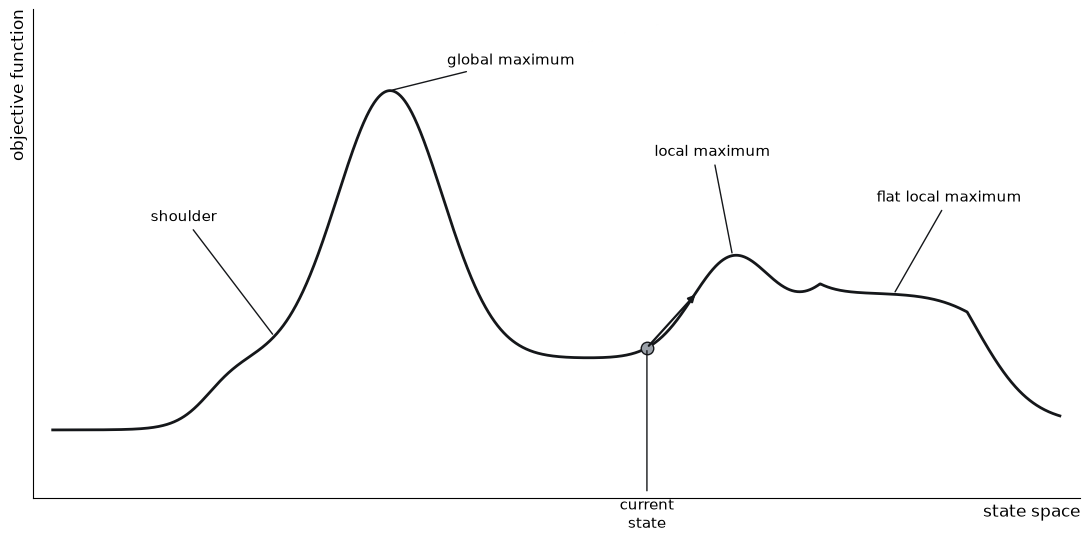

In [18]:
import numpy as np


def bump(x, centre, width, height):
    return height * np.exp(-((x - centre) ** 2) / (2 * width ** 2))


def step(x, centre, steepness, height):
    return height / (1 + np.exp(-(x - centre) * steepness))


def objective(x):
    """A landscape with every feature that strands a hill climber."""
    return (0.16
            + step(x, 1.55, 6.0, 0.22)                      # step up onto the shoulder
            + bump(x, 3.35, 0.52, 0.82)                     # global maximum
            + bump(x, 6.75, 0.40, 0.30)                     # local maximum
            + np.clip(bump(x, 8.35, 0.62, 0.40), 0, 0.20)   # flat local maximum
            - step(x, 9.30, 4.0, 0.20))                     # ground falls away at the edge


def plot_landscape(current=5.90, figsize=(11, 5.5)):
    x = np.linspace(0, 10, 2000)
    at = lambda v: float(objective(np.array([v]))[0])

    fig, ax = plt.subplots(figsize=figsize)
    ax.plot(x, objective(x), color="#15171a", linewidth=2)

    ann = dict(arrowprops=dict(arrowstyle="-", color="#15171a", linewidth=1),
               fontsize=11, ha="center")
    ax.annotate("shoulder", xy=(2.20, at(2.20)), xytext=(1.30, 0.80), **ann)
    ax.annotate("global maximum", xy=(3.35, at(3.35)), xytext=(4.55, 1.28), **ann)
    ax.annotate("local maximum", xy=(6.75, at(6.75)), xytext=(6.55, 1.00), **ann)
    ax.annotate("flat local maximum", xy=(8.35, at(8.35)), xytext=(8.90, 0.86), **ann)

    cy = at(current)
    ax.plot([current], [cy], "o", color="#9aa0a8", markersize=9, markeredgecolor="#15171a")
    ax.annotate("", xy=(current + 0.50, cy + 0.17), xytext=(current, cy),
                arrowprops=dict(arrowstyle="-|>", color="#15171a", linewidth=1.6))
    ax.annotate("current\nstate", xy=(current, cy), xytext=(current, -0.14),
                fontsize=11, ha="center",
                arrowprops=dict(arrowstyle="-", color="#15171a", linewidth=1))

    ax.set_xlabel("state space", fontsize=12, loc="right")
    ax.set_ylabel("objective function", fontsize=12, loc="top")
    ax.set_ylim(-0.05, 1.45)
    ax.set_xlim(-0.2, 10.2)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_xticks([])
    ax.set_yticks([])
    plt.tight_layout()
    plt.show()


plot_landscape()

Our map has exactly one of those traps, and it is worth finding before you write the algorithm:
a city whose neighbours all have a **higher** `h` than it does. Hill climbing walks in and cannot
walk out.

In [19]:
def local_minima(g):
    """Cities where every neighbour looks further from the goal than we are."""
    return [n.value for n in g.nodes.values()
            if n.heuristic > 0
            and all(g.nodes[v].heuristic >= n.heuristic for v, _ in g.edges[n.value])]


print("hill climbing gets stuck at:", local_minima(romania))

hill climbing gets stuck at: ['Mehadia']


In [20]:
def hill_climbing(g, start, end):
    """Beam search with k = 1: step to the best successor, keep nothing else.

    Stop when no neighbour improves on the current node -- that is a local
    minimum of h, and hill climbing cannot tell it apart from the goal.

    Returns (path, cost). If it gets stuck, return the path it managed and the
    cost so far, so you can see where it stopped.
    """
    curr = start
    path = [start]
    dist = 0

    while curr != end:
        display_graph(g, curr)
        g.nodes[curr].color = "blue"

        # The single best neighbour by h. Nothing else is remembered, so there
        # is nothing to go back to.
        best, best_w = None, 0
        for node, w in g.edges[curr]:
            if best is None or g.nodes[node].heuristic < g.nodes[best].heuristic:
                best, best_w = node, w

        # Every way out looks further from the goal than where we are standing.
        # That is a local minimum, and hill climbing stops on it.
        if best is None or g.nodes[best].heuristic >= g.nodes[curr].heuristic:
            return (path, dist)

        curr = best
        dist += best_w
        path.append(curr)
        g.nodes[curr].color = "gray"

    g.nodes[curr].color = "green"
    display_graph(g, curr)
    return (path, dist)

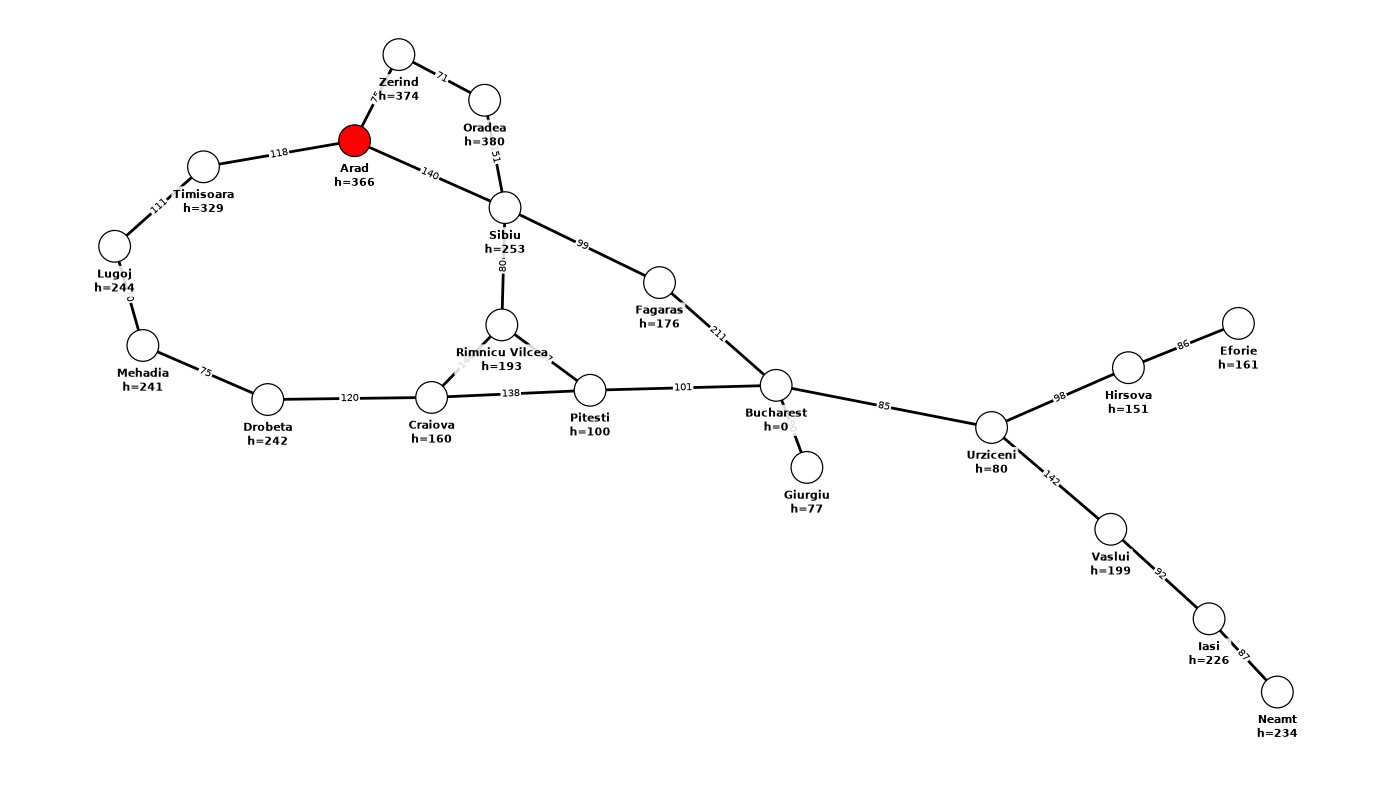

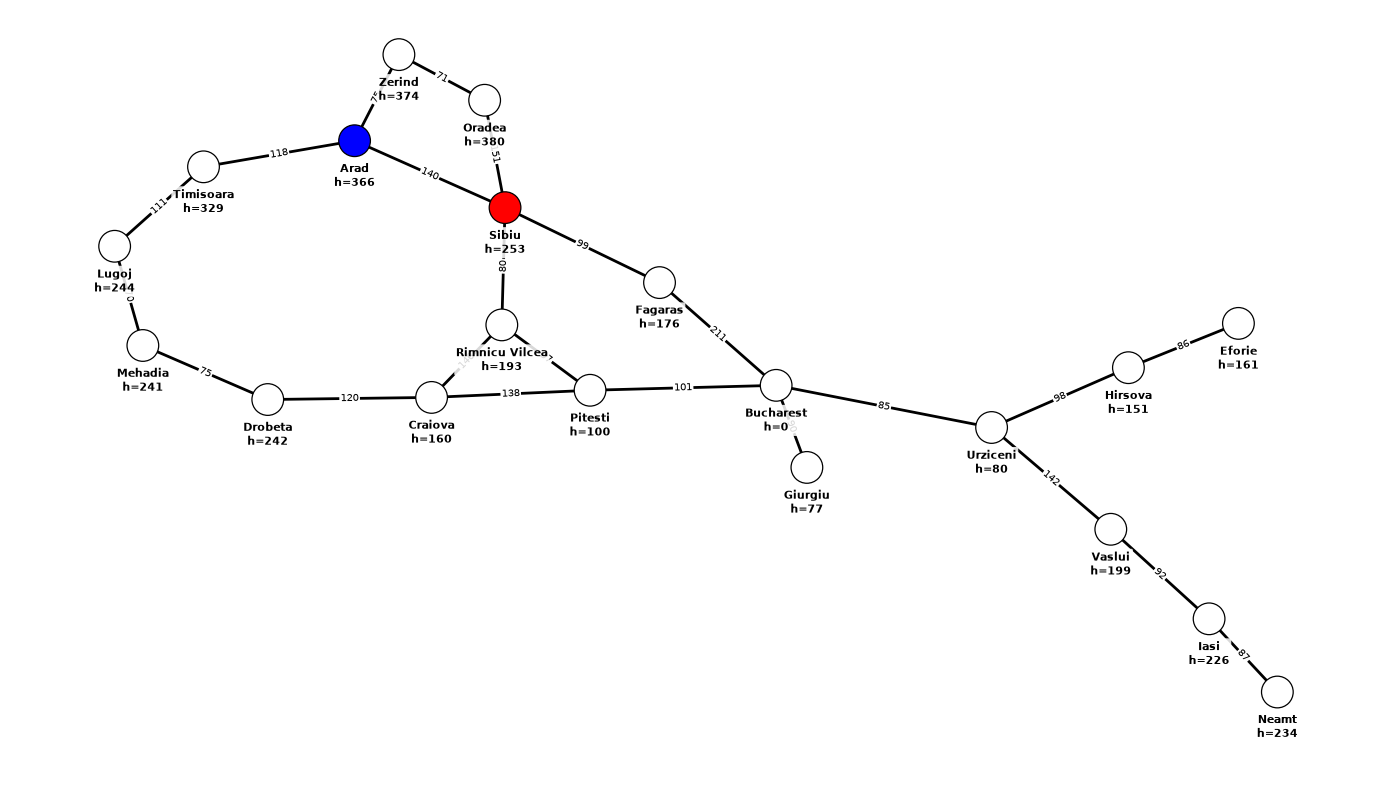

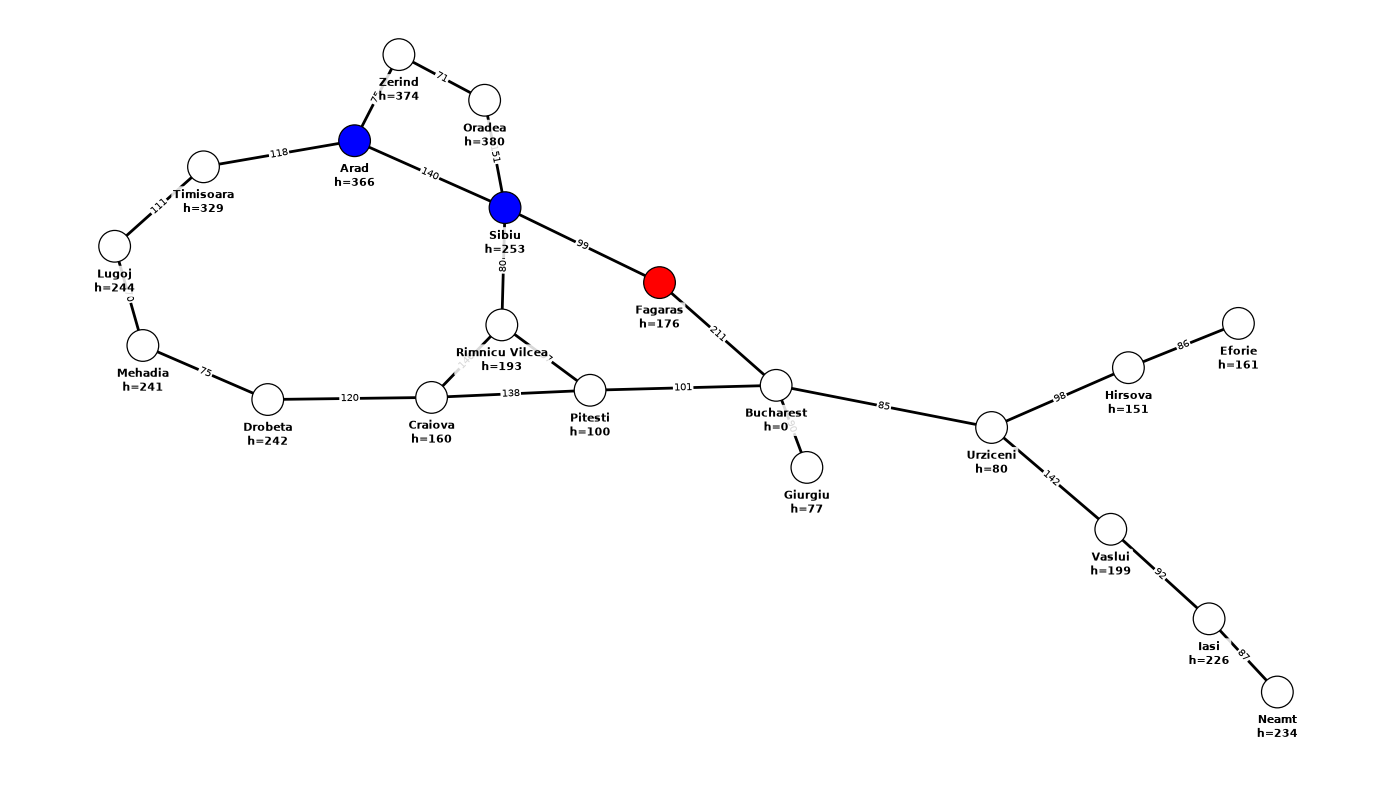

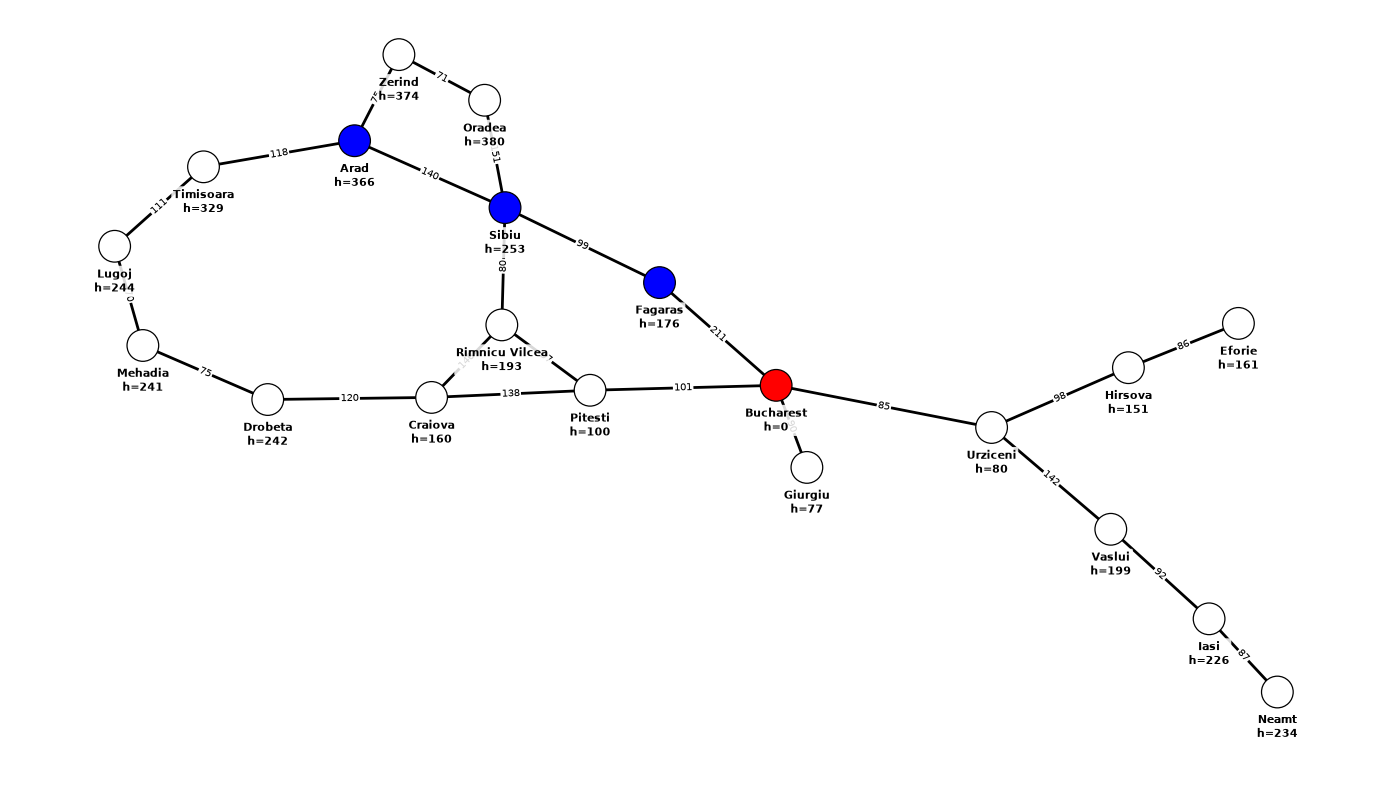

(['Arad', 'Sibiu', 'Fagaras', 'Bucharest'], 450)

In [21]:
# From Arad it reaches Bucharest.
reset_colors(romania)
hill_climbing(romania, "Arad", "Bucharest")

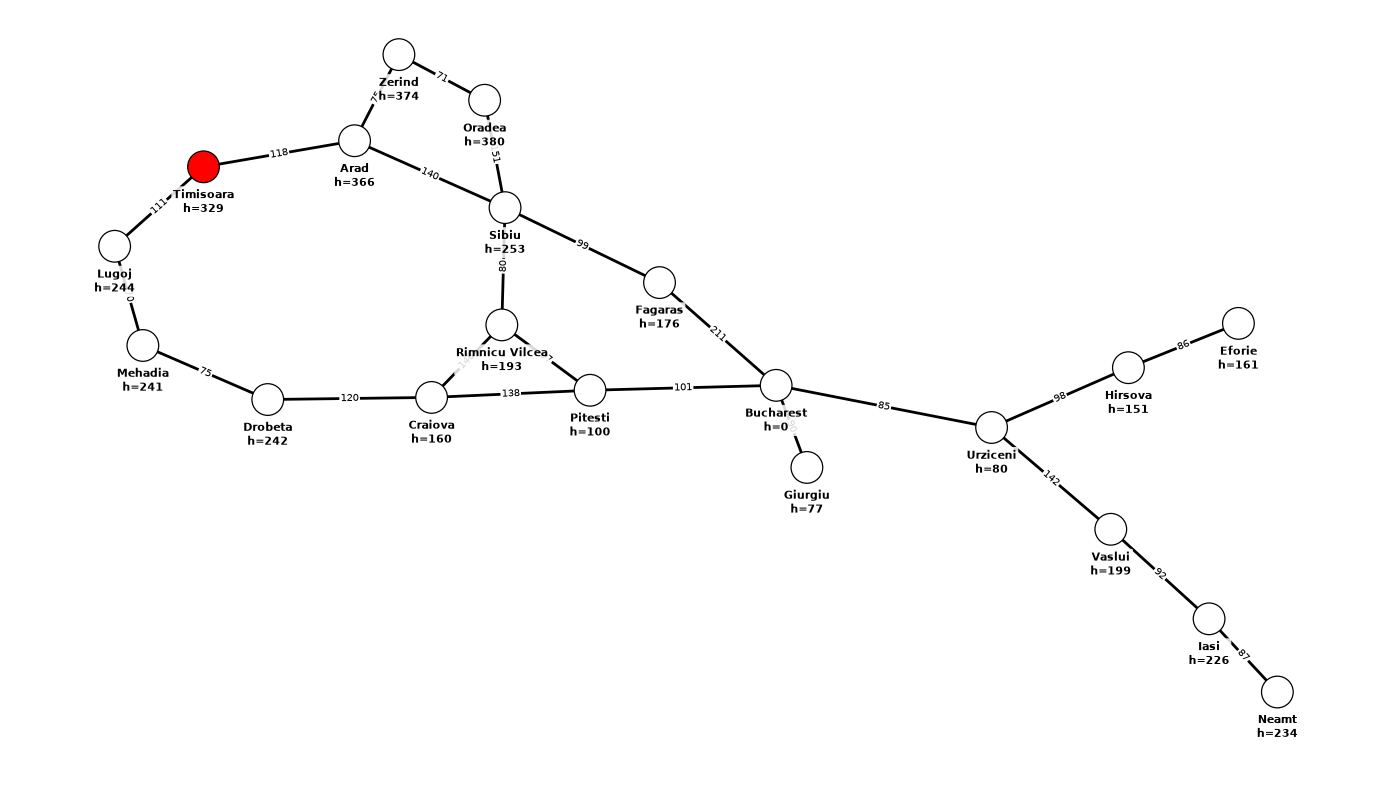

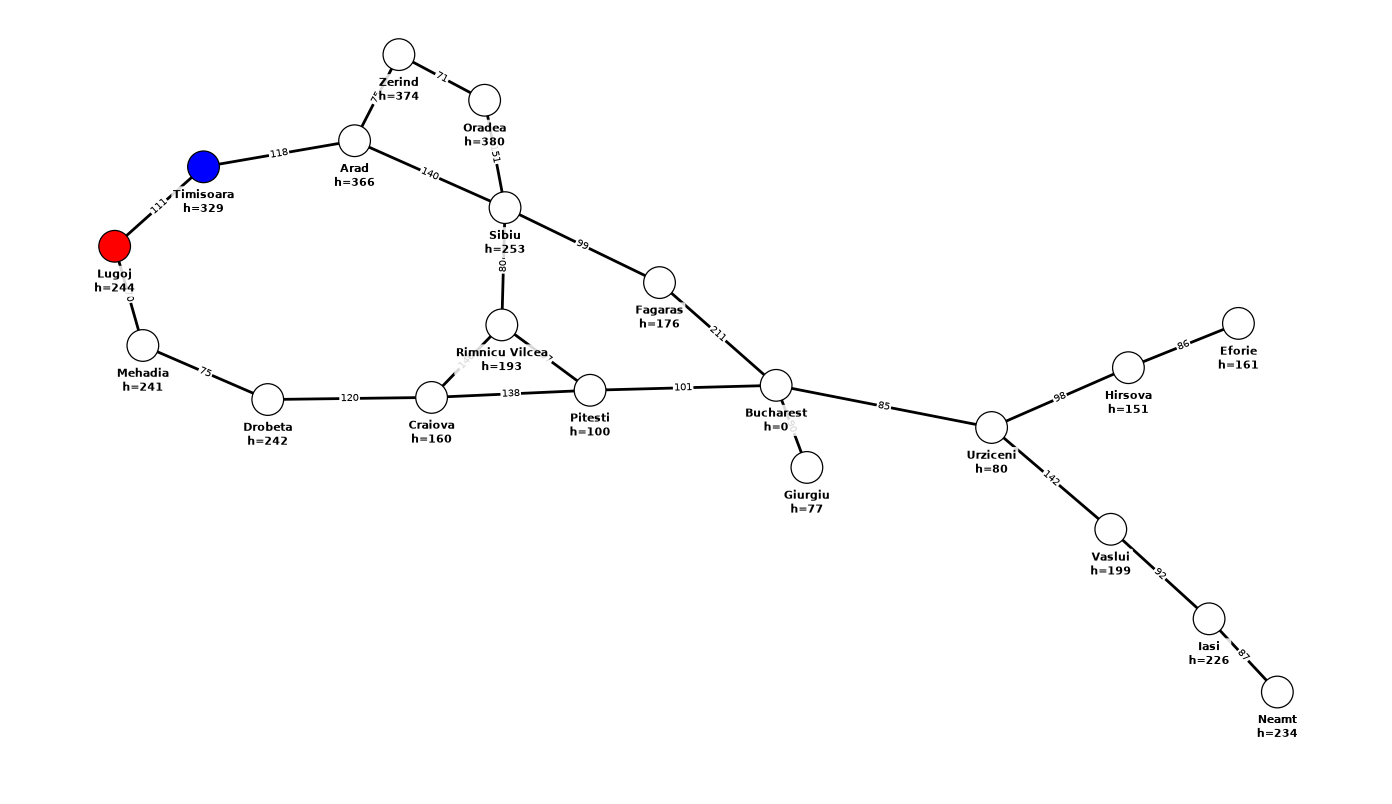

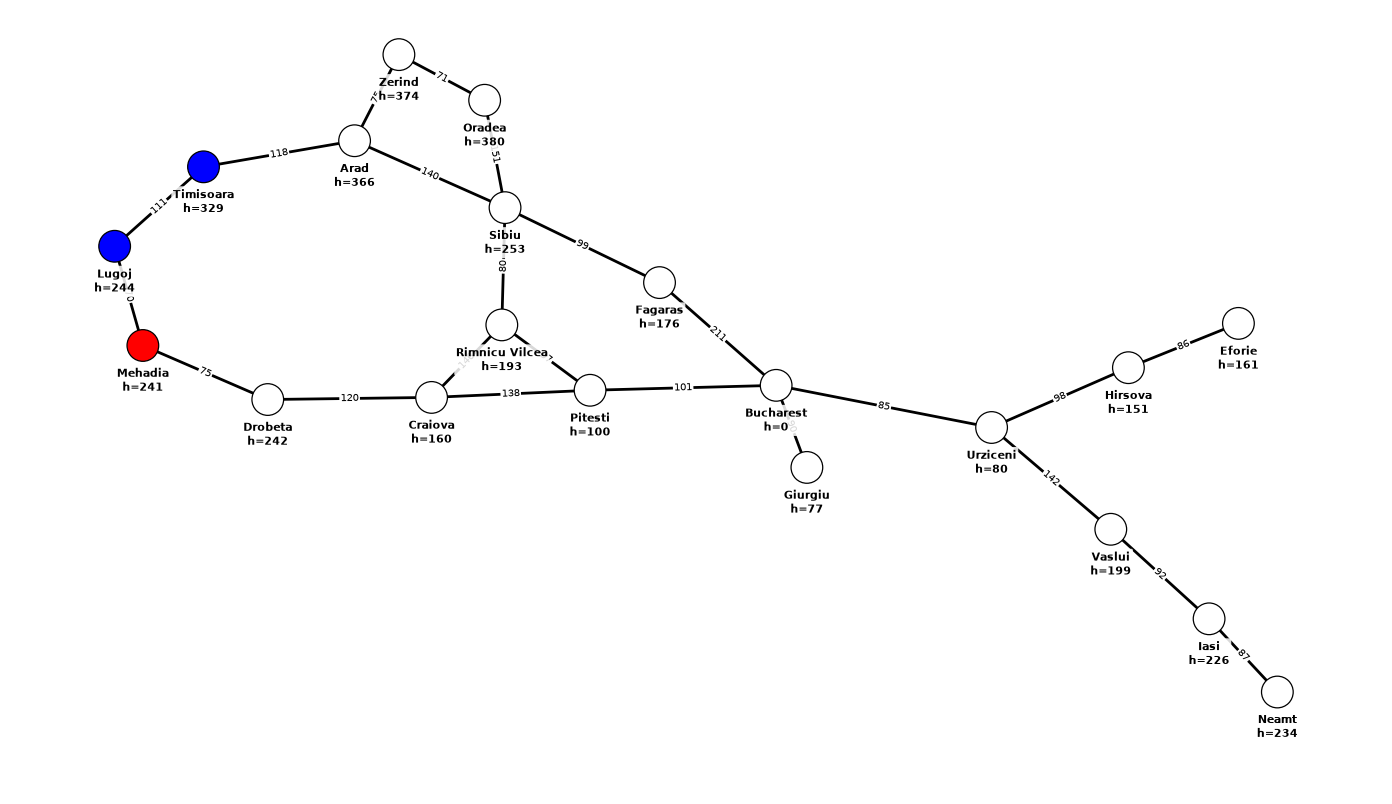

(['Timisoara', 'Lugoj', 'Mehadia'], 181)

In [22]:
# From Timisoara it walks into Mehadia and stops.
reset_colors(romania)
hill_climbing(romania, "Timisoara", "Bucharest")

## Iterative Deepening A\*

A\* with iterative deepening's memory profile: a stack instead of a priority queue, and repeated
passes instead of remembering. The limit is on `f`, not on depth.

Each pass is a depth-first search that prunes anything with `f(n) > limit`. When a pass fails, the
next limit is the smallest `f` that got pruned — so the limit steps up through the `f` values that
actually occur, never guessing.

Expect it to be slow here, and understand why: with road distances like 71, 75 and 118 almost
every node has its own `f`, so each pass buys you very few new nodes. On the sliding-tile puzzle
in the homework every move costs 1, `f` takes few values, and IDA\* comes into its own.

In [27]:
def ida_star(g, start, end, draw=False):
    """Iterative deepening A*.

    Repeat a depth-first search with an f-limit, raising the limit each round to
    the smallest f value that was pruned in the previous one. Track the path on
    the recursion stack so you can return it, and skip nodes already on the
    current path so you do not loop.

    Returns (path, cost), or (None, None) if there is no path.

    Drawing is off by default: IDA* expands hundreds of nodes on this map, and
    that would be hundreds of figures. Pass draw=True on a short run to watch it.
    Afterwards, ida_star.rounds and ida_star.expansions say how much work it did
    -- kept off the return value so the contract matches the other searches.
    """
    INF = float("inf")
    result = None
    rounds = 0
    expansions = 0

    def search(curr, dist, limit, path, on_path):
        nonlocal result, expansions

        f = dist + g.nodes[curr].heuristic
        print(f"{f=}, {limit=}, {curr=}")

        # Too expensive for this round. Hand our own f back up: the next limit
        # will be the smallest f that got pruned anywhere.
        if f > limit:
            return f

        if curr == end:
            result = (list(path), dist)
            return f

        expansions += 1
        if draw:
            display_graph(g, curr)

        smallest_over = INF
        for node, w in g.edges[curr]:
            if node in on_path:          # never walk back along the current path
                continue

            path.append(node)
            on_path.add(node)
            g.nodes[node].color = "gray"

            t = search(node, dist + w, limit, path, on_path)
            if result is not None:
                return t

            smallest_over = min(smallest_over, t)

            # Backtracking, so this node is no longer on the path. Free it, or
            # another route through it can never be tried.
            path.pop()
            on_path.discard(node)
            g.nodes[node].color = "white"

        return smallest_over

    # The first limit is the best we could possibly hope for.
    limit = g.nodes[start].heuristic

    while True:
        rounds += 1
        reset_colors(g)
        g.nodes[start].color = "gray"

        t = search(start, 0, limit, [start], {start})

        ida_star.rounds = rounds
        ida_star.expansions = expansions

        if result is not None:
            path, cost = result
            for n in path:
                g.nodes[n].color = "blue"
            g.nodes[end].color = "green"
            if draw:
                display_graph(g, end)
            return (path, cost)

        # Nothing was pruned, so there is nothing left to raise the limit to.
        if t == INF:
            return (None, None)

        limit = t

f=366, limit=366, curr='Arad'


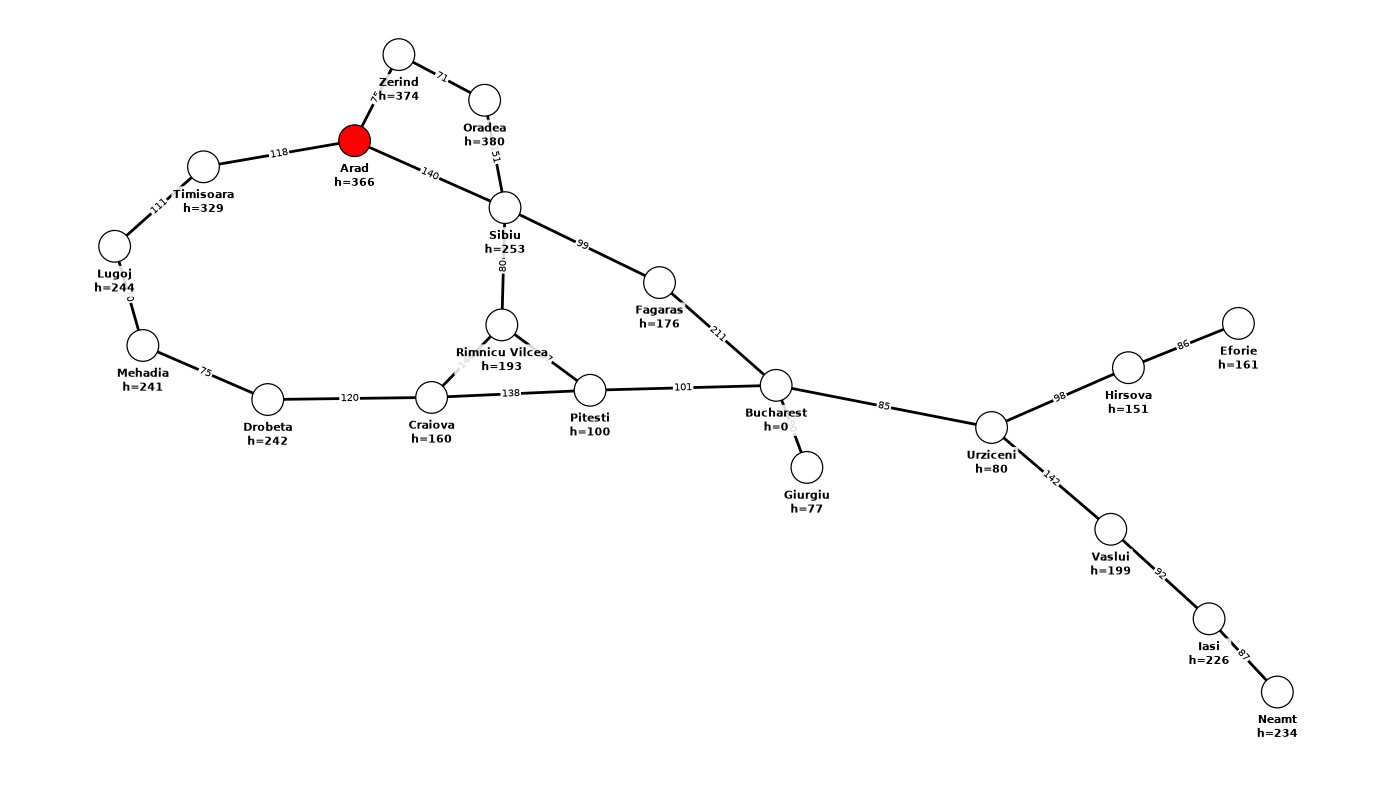

f=449, limit=366, curr='Zerind'
f=393, limit=366, curr='Sibiu'
f=447, limit=366, curr='Timisoara'
f=366, limit=393, curr='Arad'


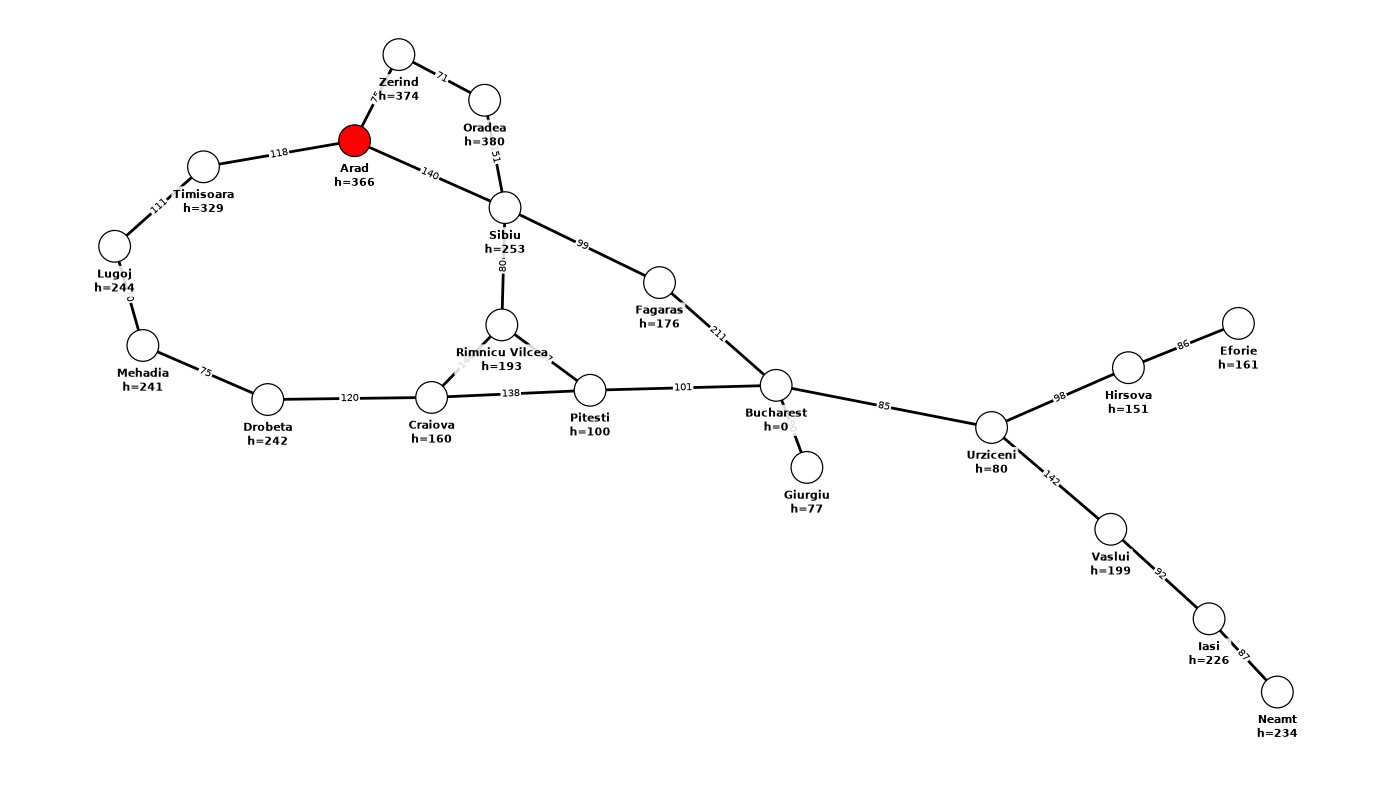

f=449, limit=393, curr='Zerind'
f=393, limit=393, curr='Sibiu'


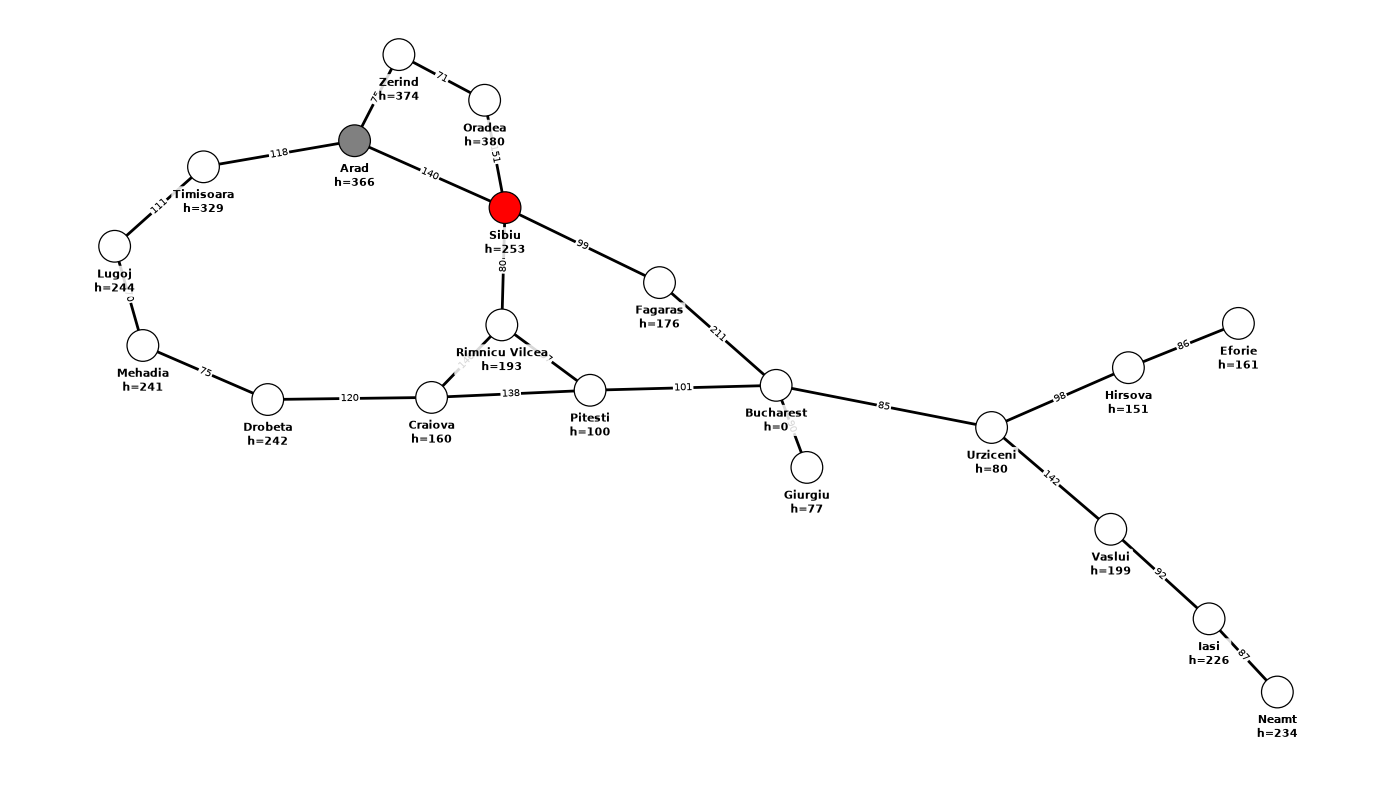

f=671, limit=393, curr='Oradea'
f=415, limit=393, curr='Fagaras'
f=413, limit=393, curr='Rimnicu Vilcea'
f=447, limit=393, curr='Timisoara'
f=366, limit=413, curr='Arad'


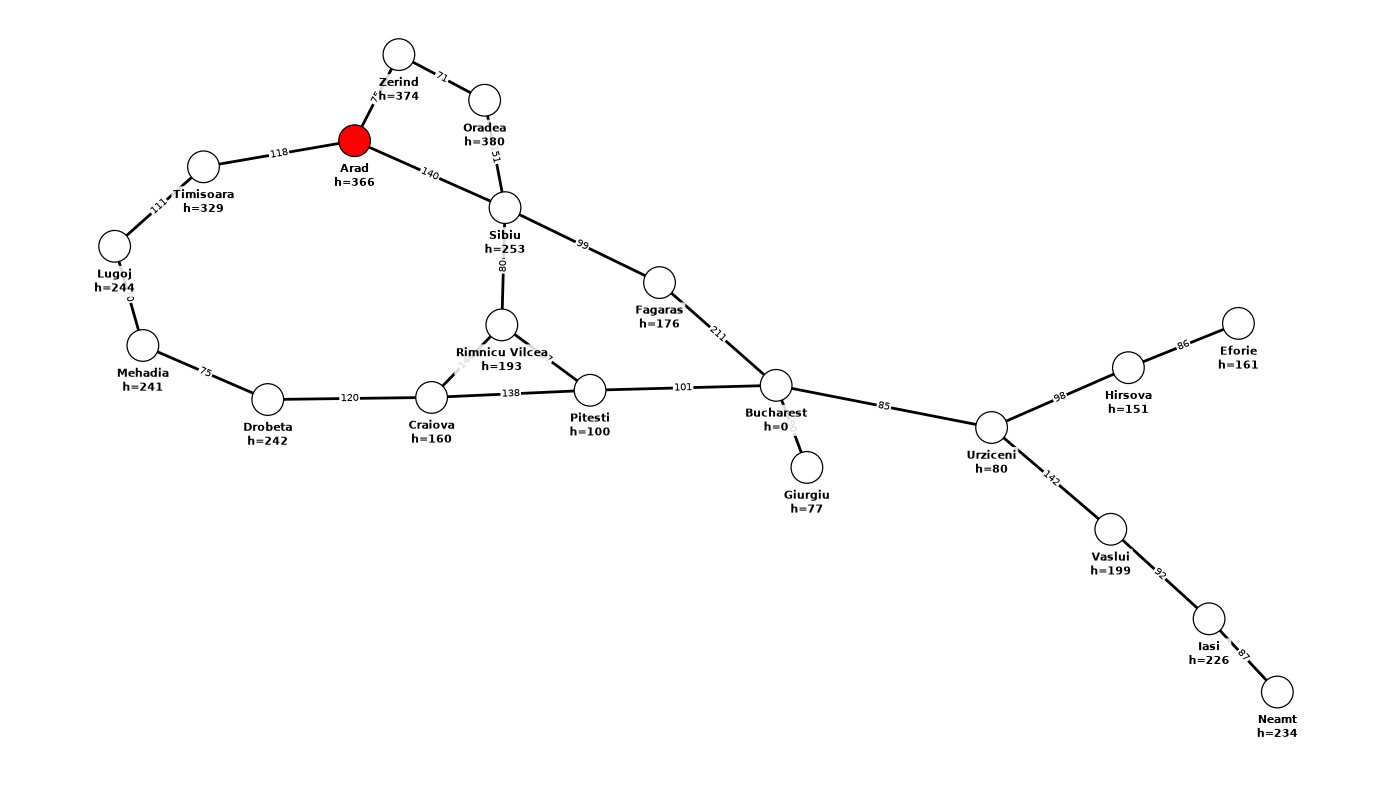

f=449, limit=413, curr='Zerind'
f=393, limit=413, curr='Sibiu'


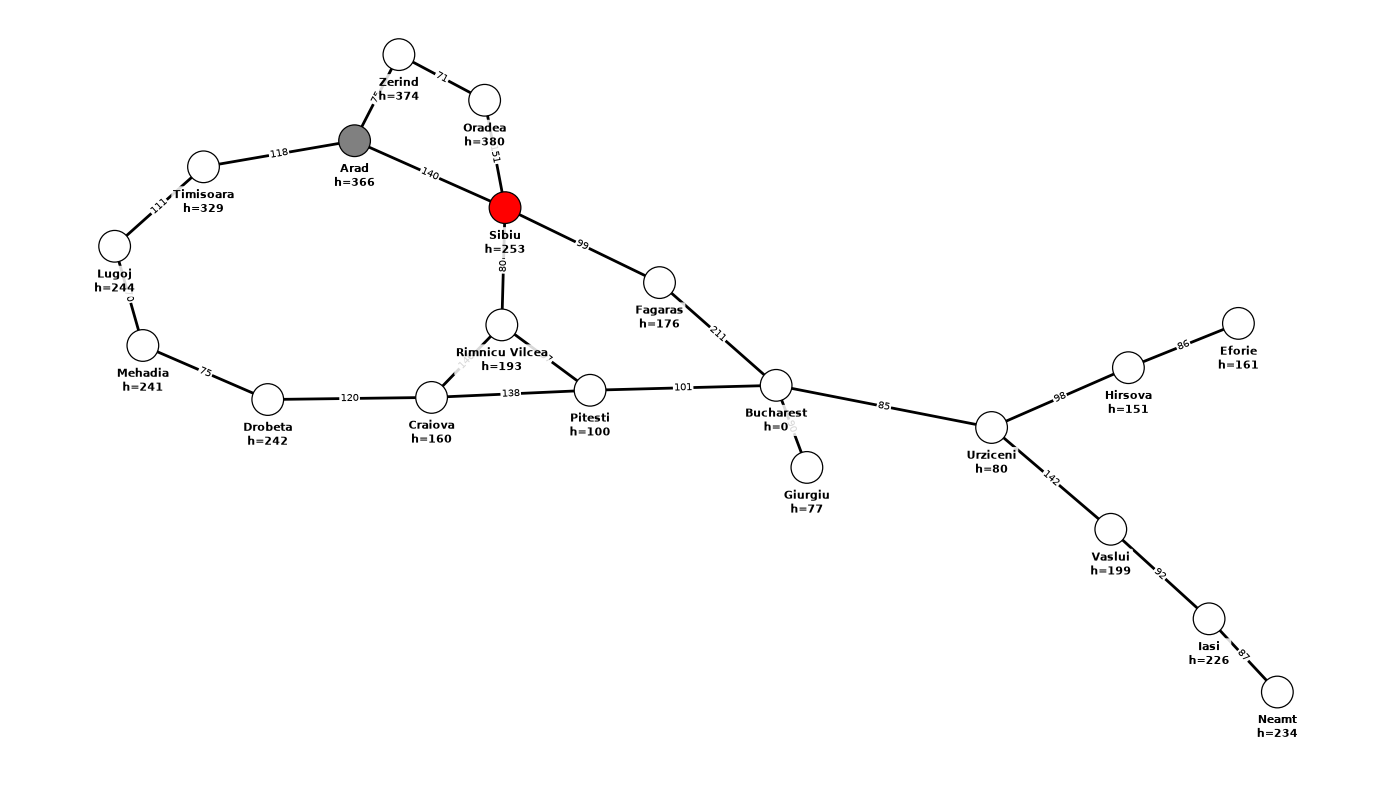

f=671, limit=413, curr='Oradea'
f=415, limit=413, curr='Fagaras'
f=413, limit=413, curr='Rimnicu Vilcea'


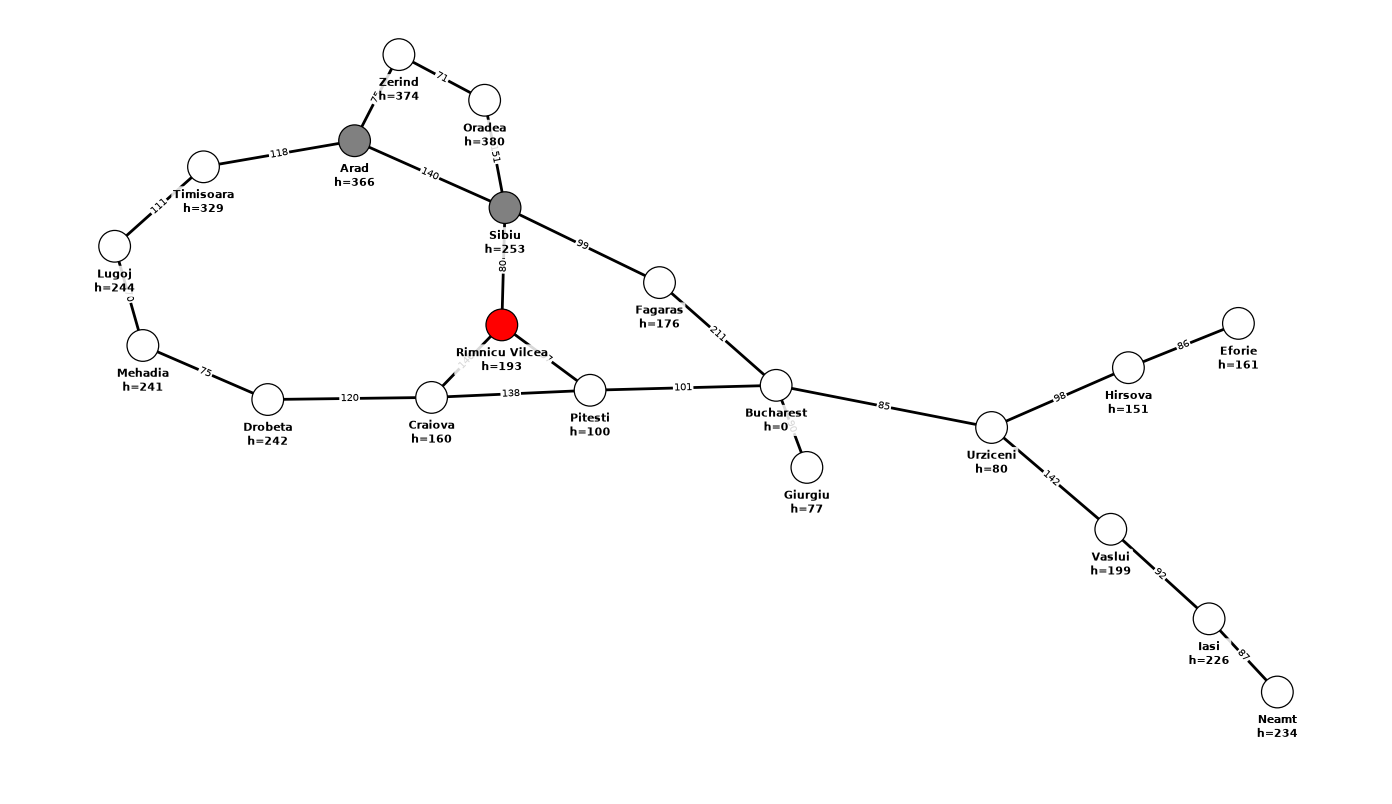

f=526, limit=413, curr='Craiova'
f=417, limit=413, curr='Pitesti'
f=447, limit=413, curr='Timisoara'
f=366, limit=415, curr='Arad'


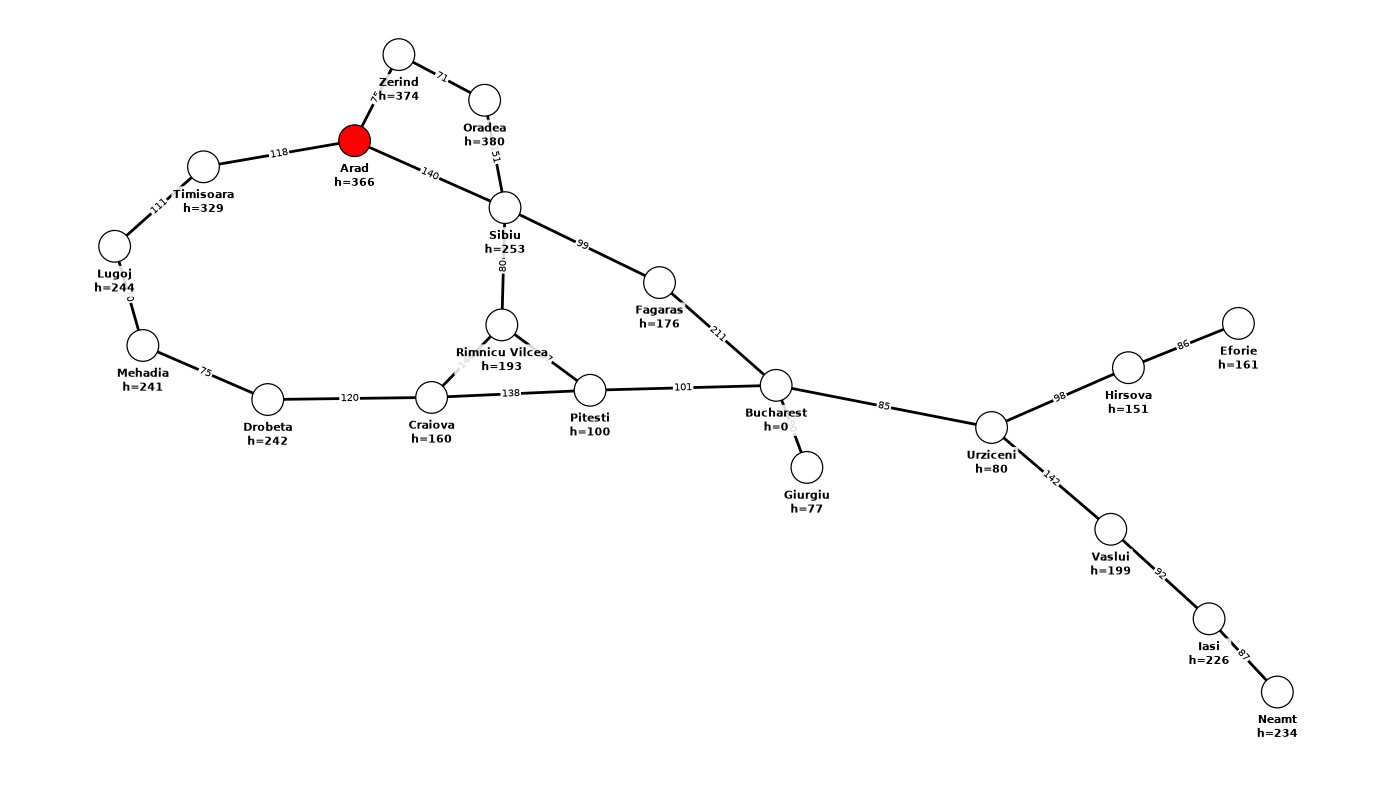

f=449, limit=415, curr='Zerind'
f=393, limit=415, curr='Sibiu'


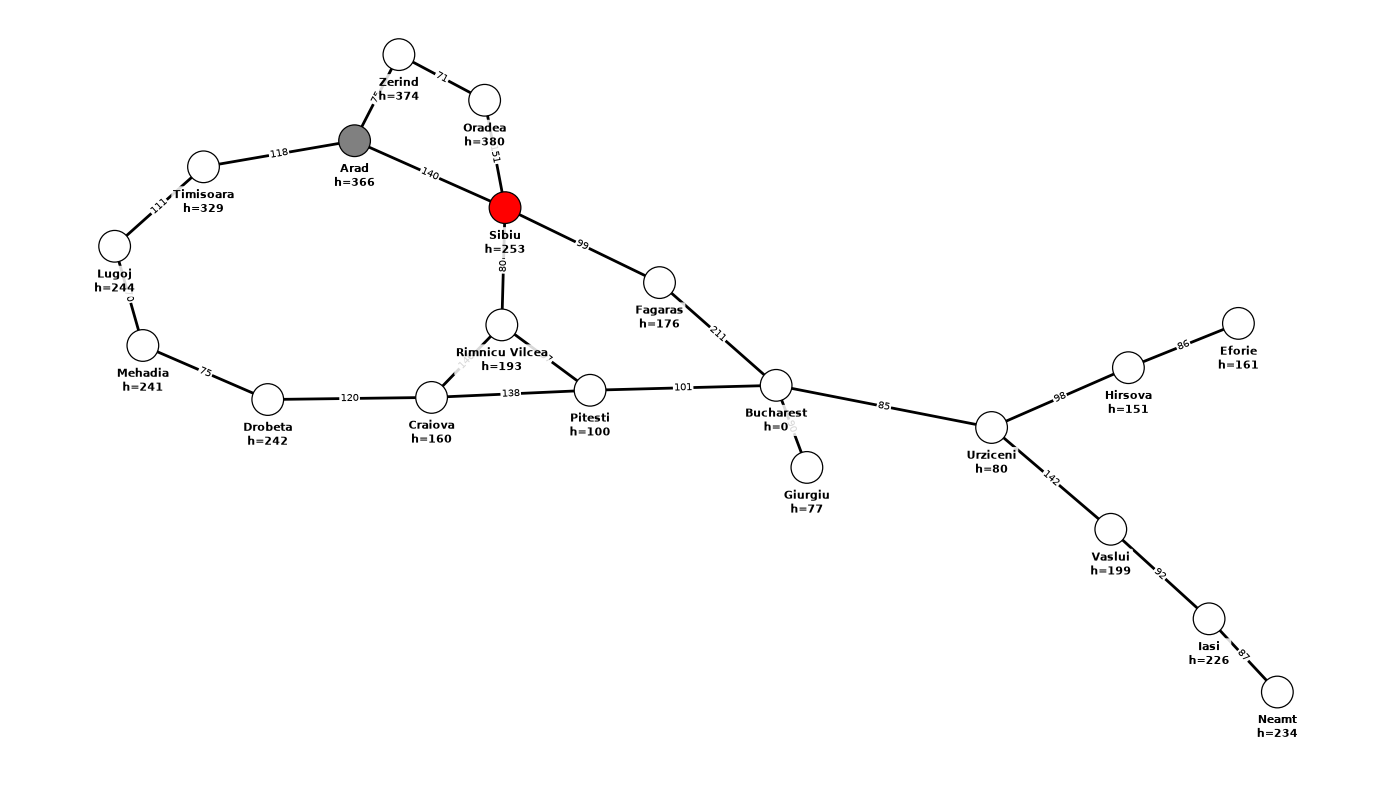

f=671, limit=415, curr='Oradea'
f=415, limit=415, curr='Fagaras'


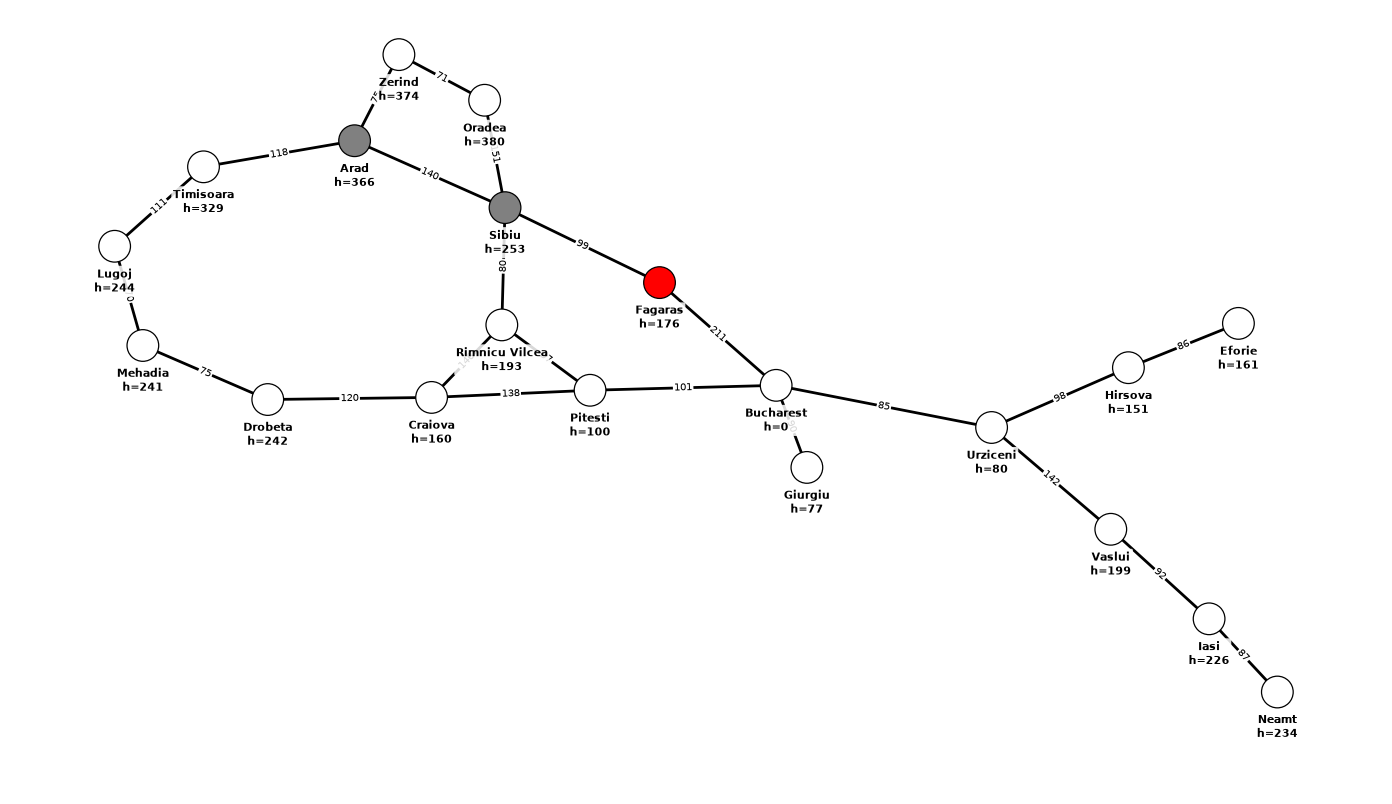

f=450, limit=415, curr='Bucharest'
f=413, limit=415, curr='Rimnicu Vilcea'


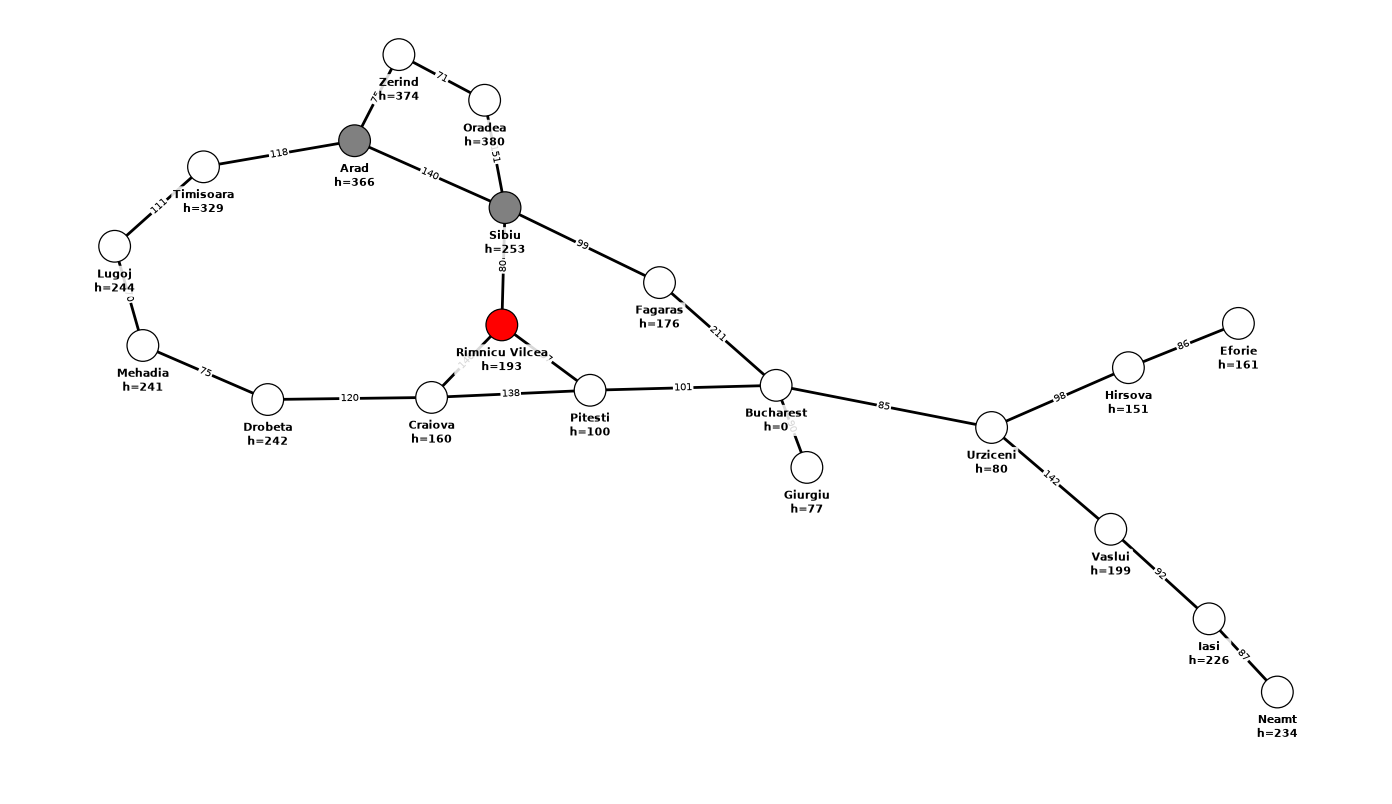

f=526, limit=415, curr='Craiova'
f=417, limit=415, curr='Pitesti'
f=447, limit=415, curr='Timisoara'
f=366, limit=417, curr='Arad'


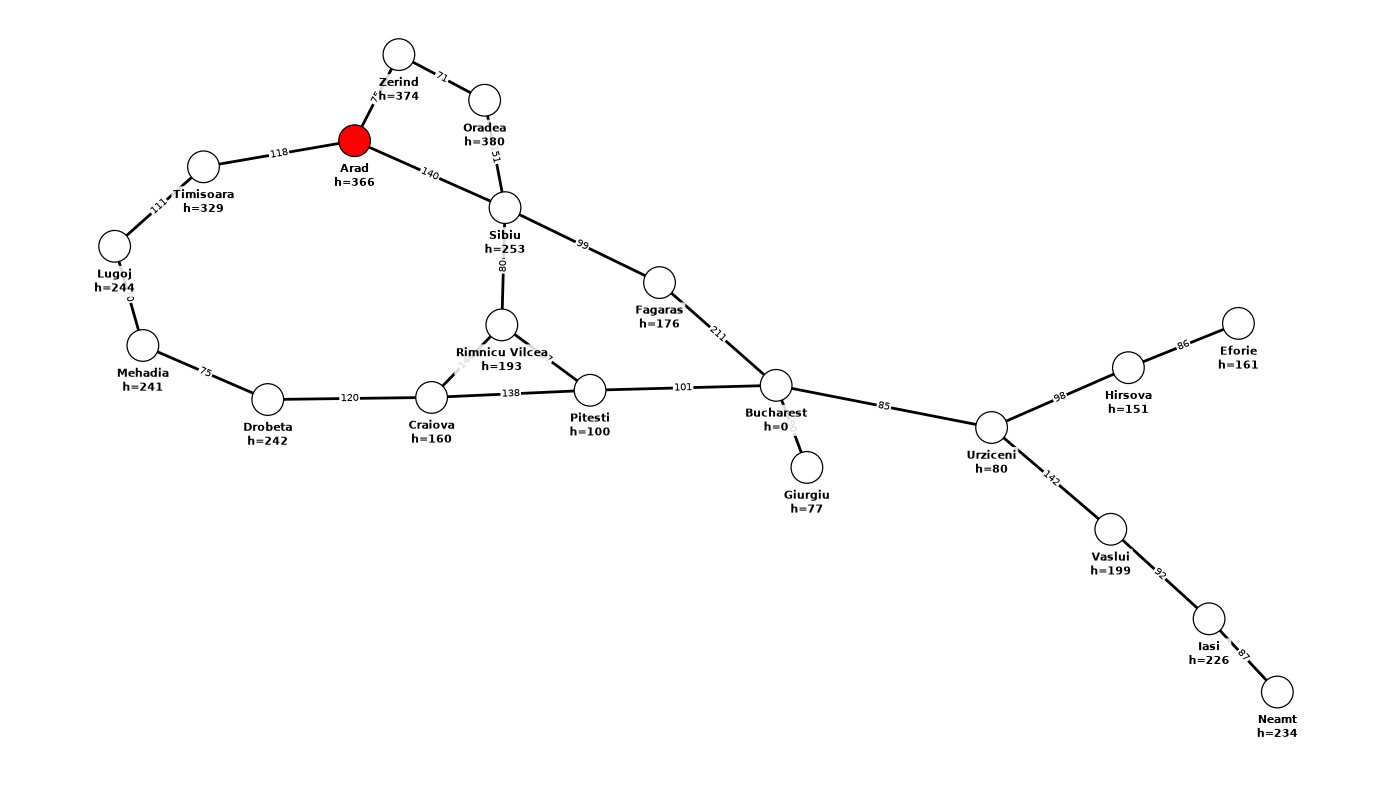

f=449, limit=417, curr='Zerind'
f=393, limit=417, curr='Sibiu'


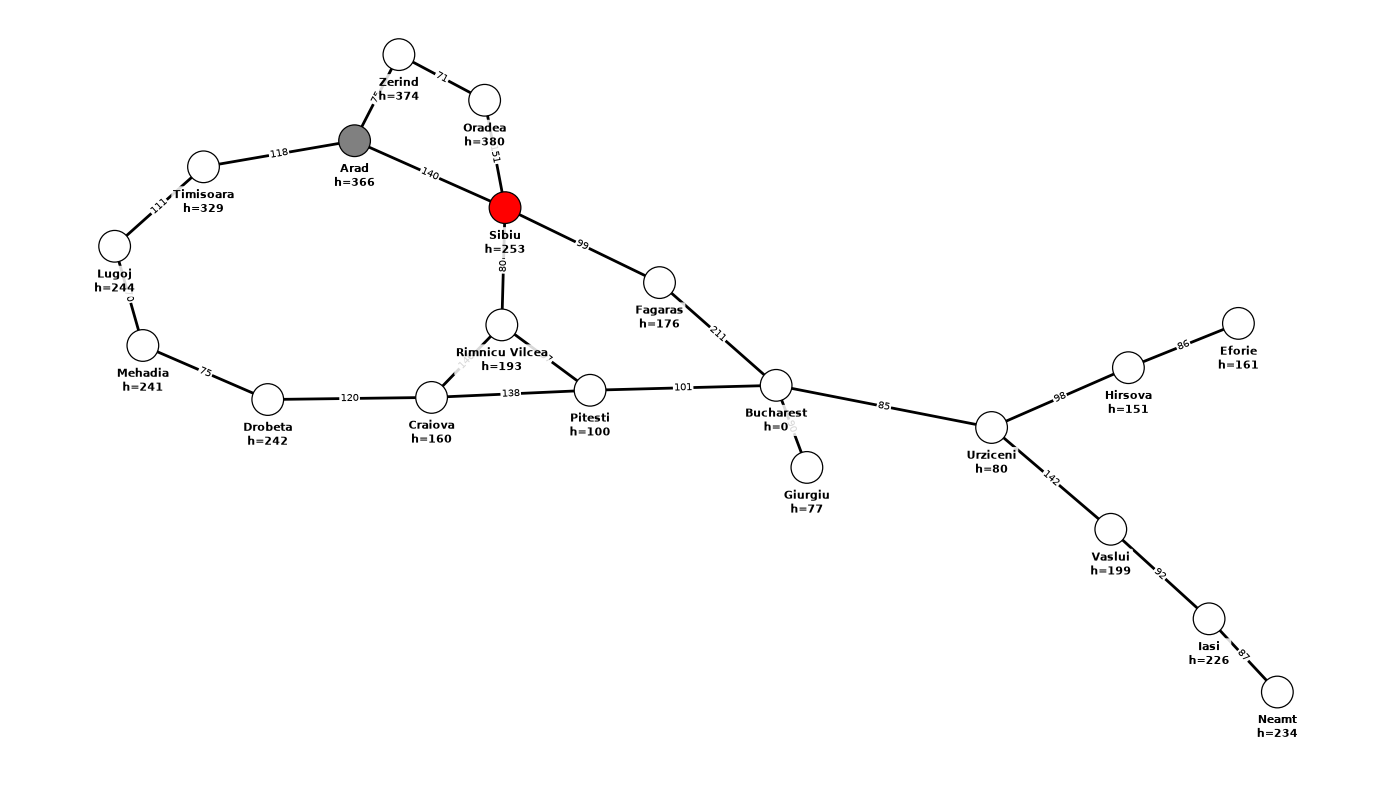

f=671, limit=417, curr='Oradea'
f=415, limit=417, curr='Fagaras'


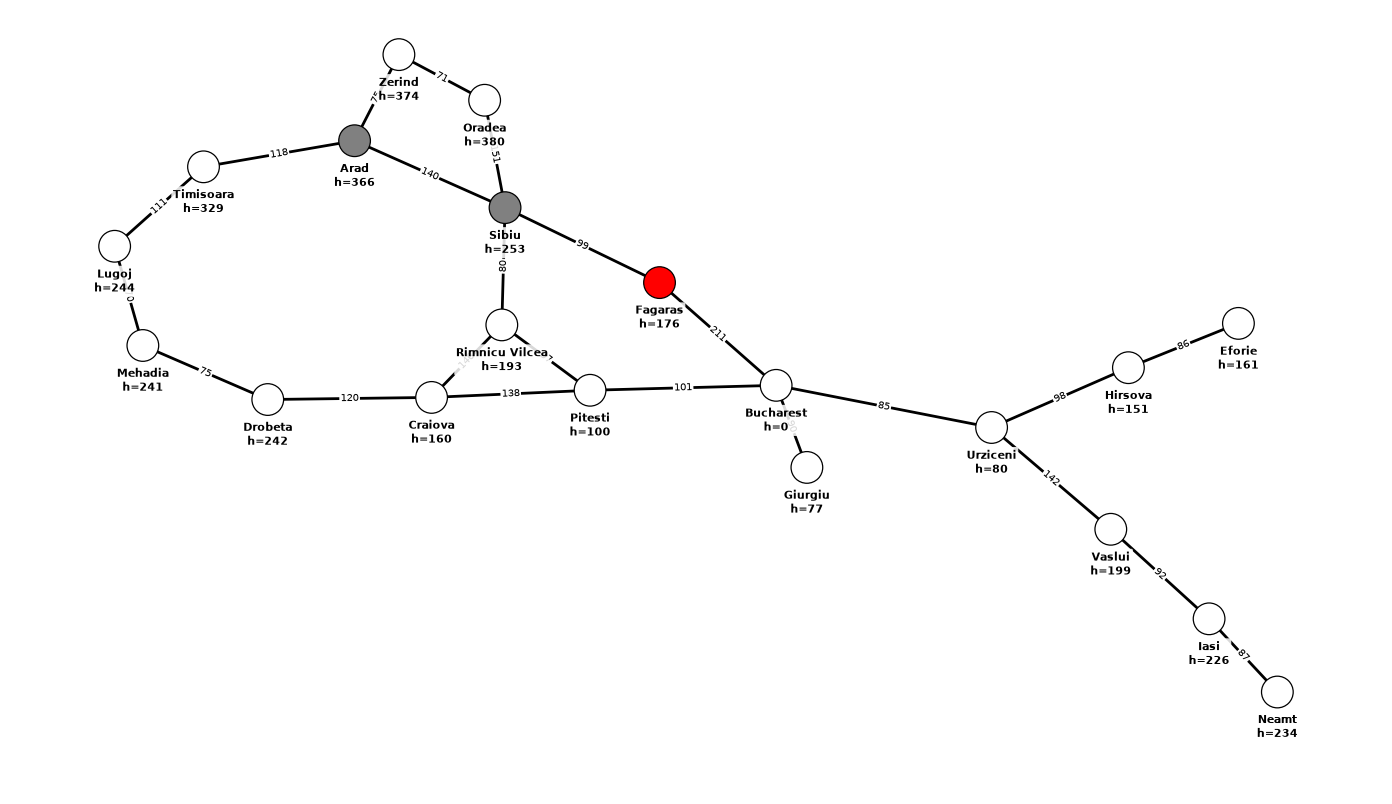

f=450, limit=417, curr='Bucharest'
f=413, limit=417, curr='Rimnicu Vilcea'


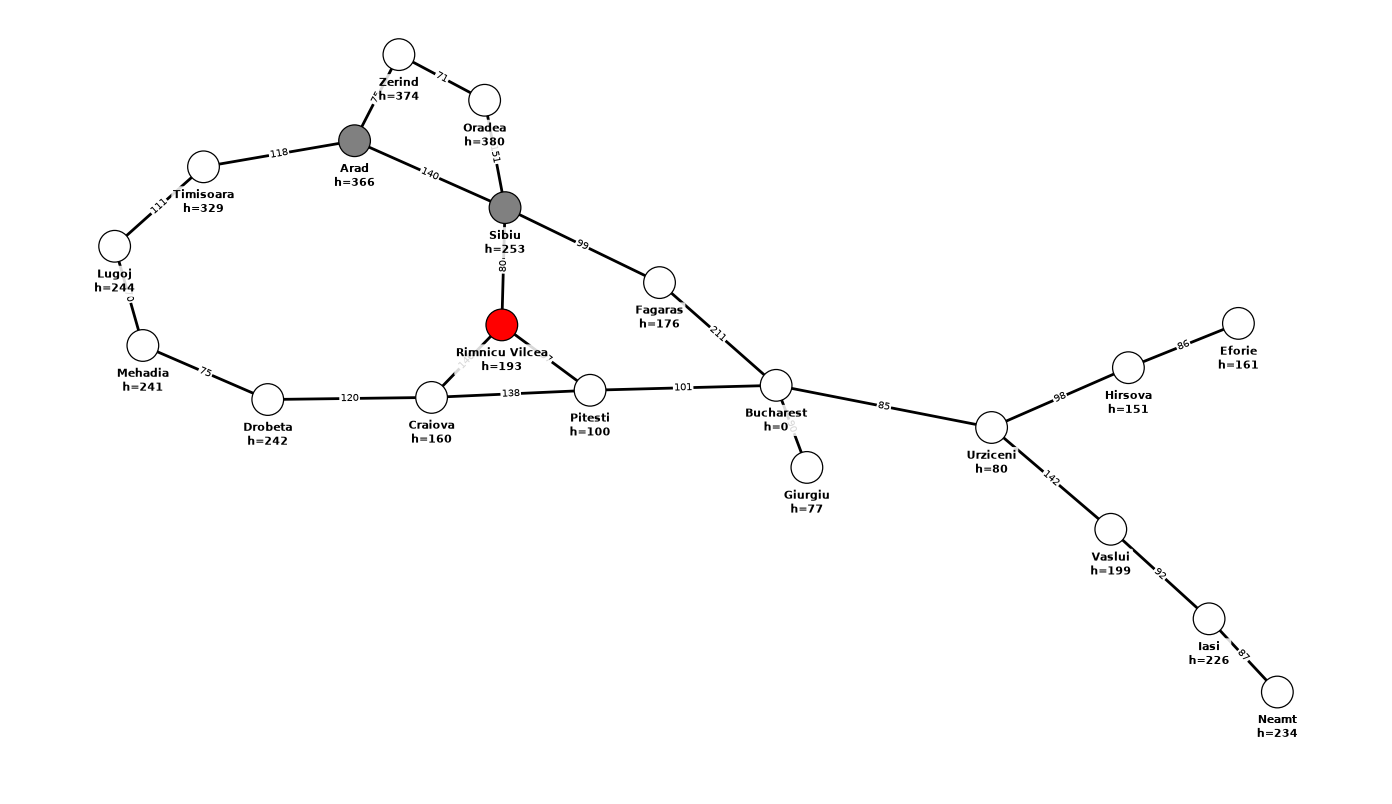

f=526, limit=417, curr='Craiova'
f=417, limit=417, curr='Pitesti'


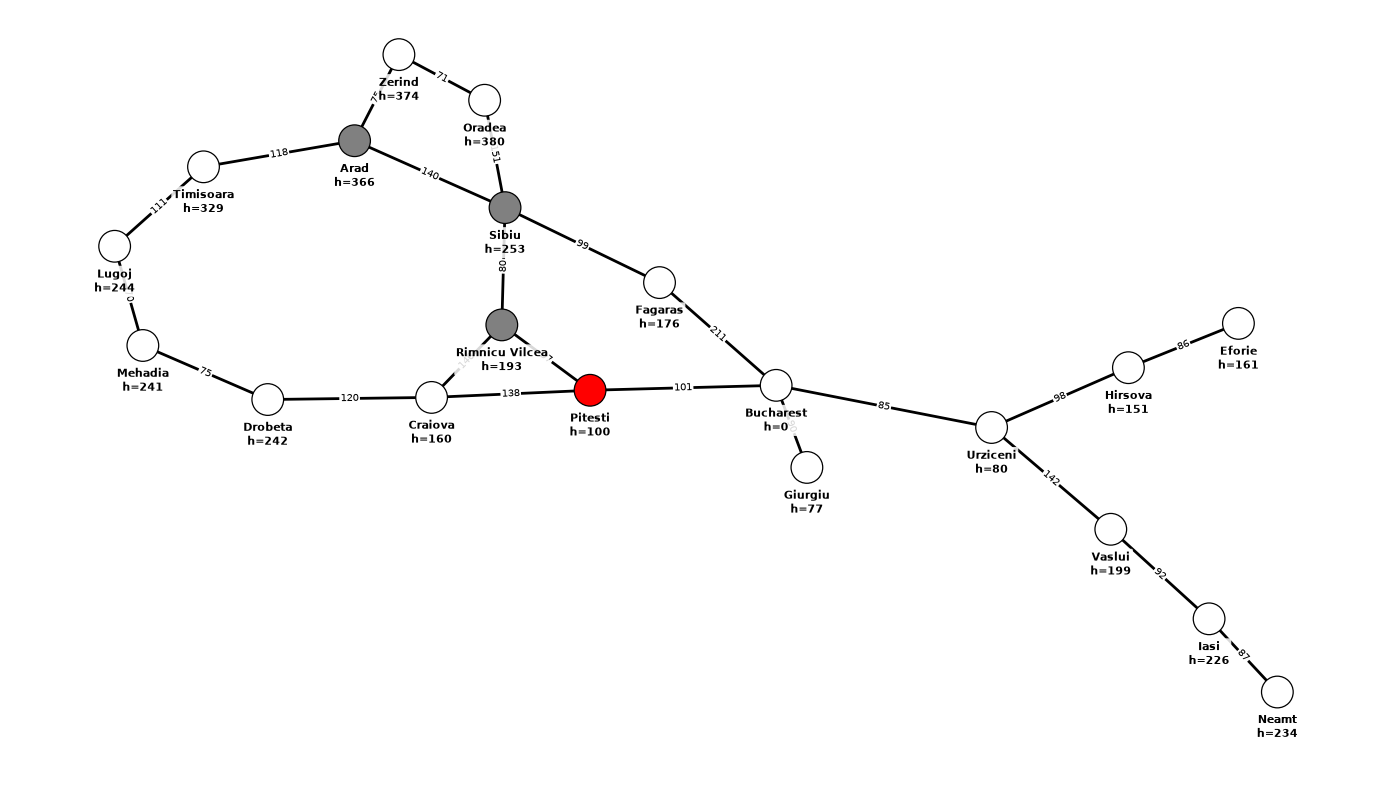

f=615, limit=417, curr='Craiova'
f=418, limit=417, curr='Bucharest'
f=447, limit=417, curr='Timisoara'
f=366, limit=418, curr='Arad'


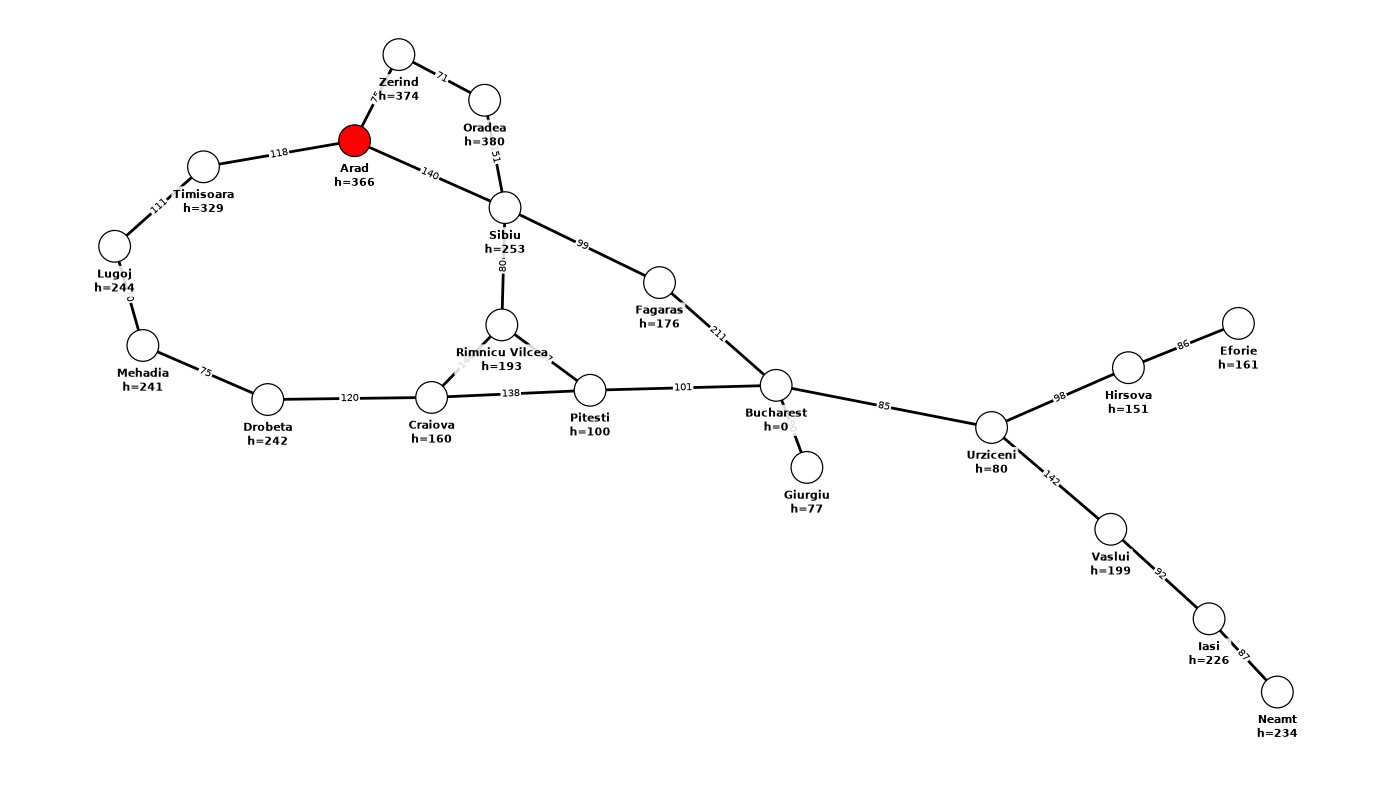

f=449, limit=418, curr='Zerind'
f=393, limit=418, curr='Sibiu'


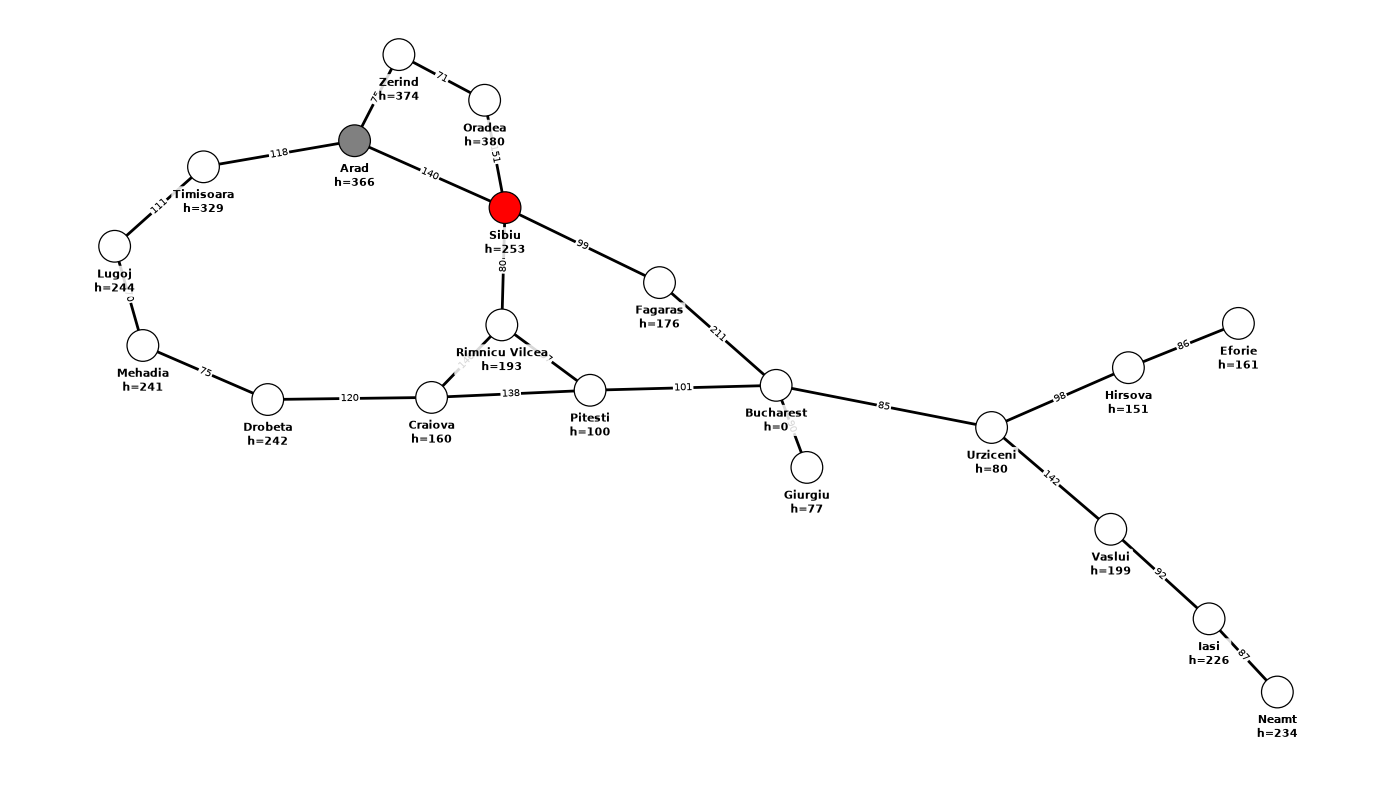

f=671, limit=418, curr='Oradea'
f=415, limit=418, curr='Fagaras'


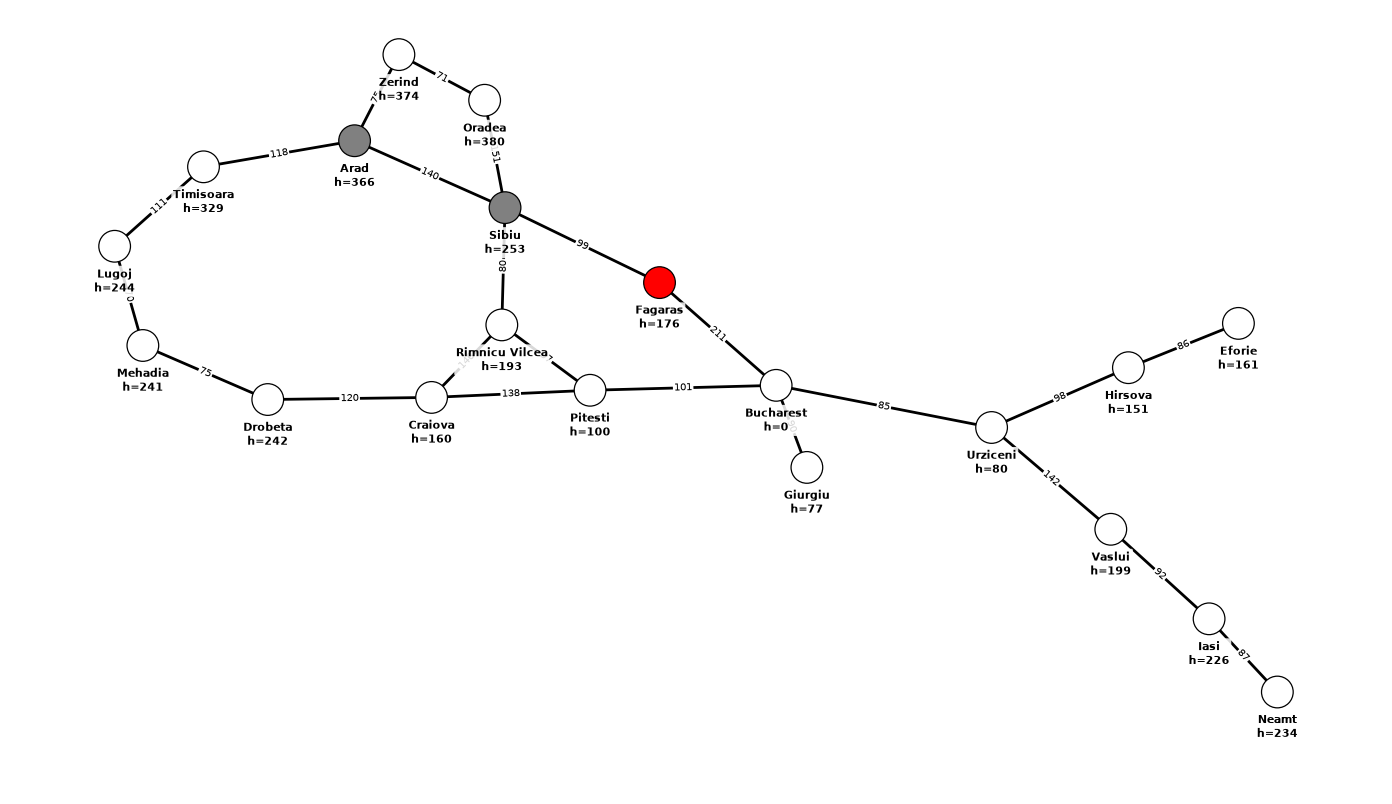

f=450, limit=418, curr='Bucharest'
f=413, limit=418, curr='Rimnicu Vilcea'


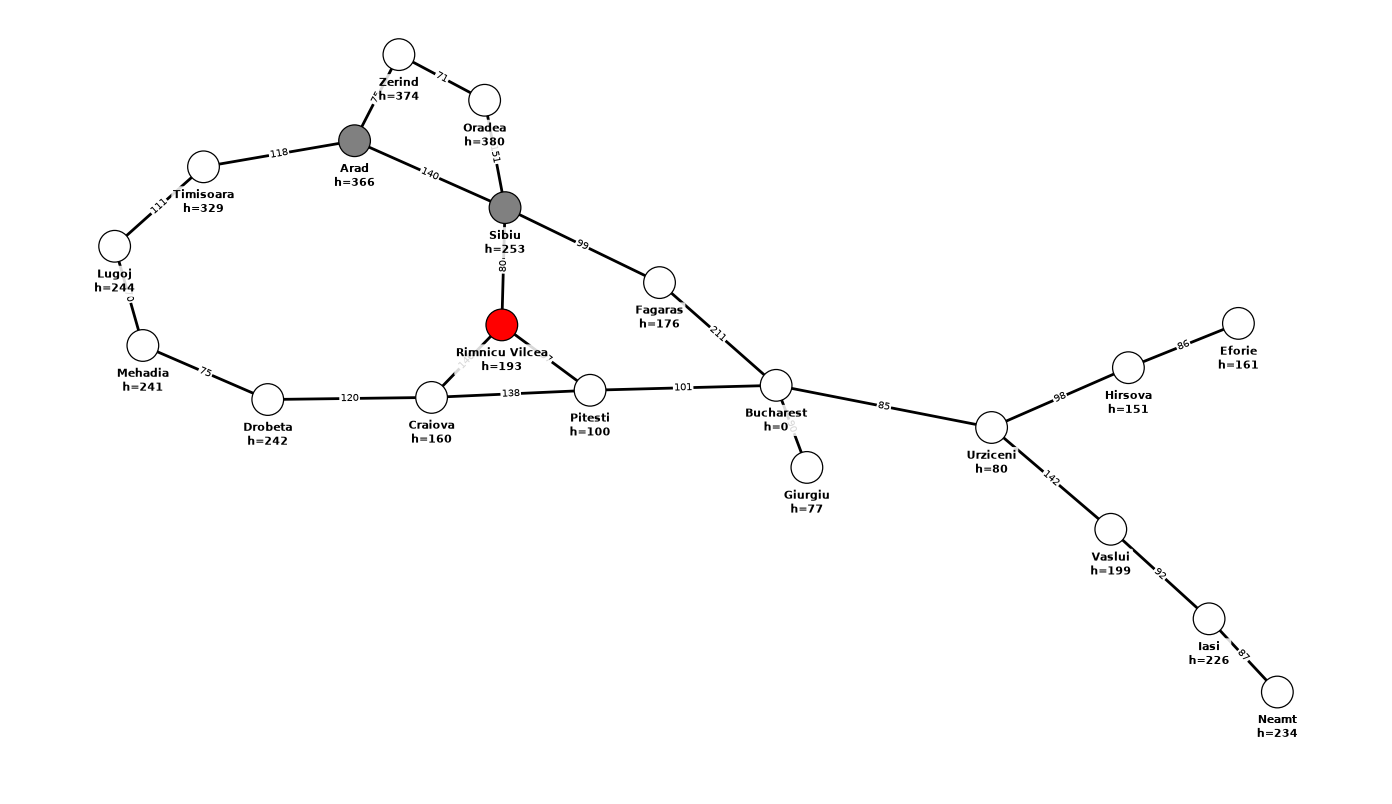

f=526, limit=418, curr='Craiova'
f=417, limit=418, curr='Pitesti'


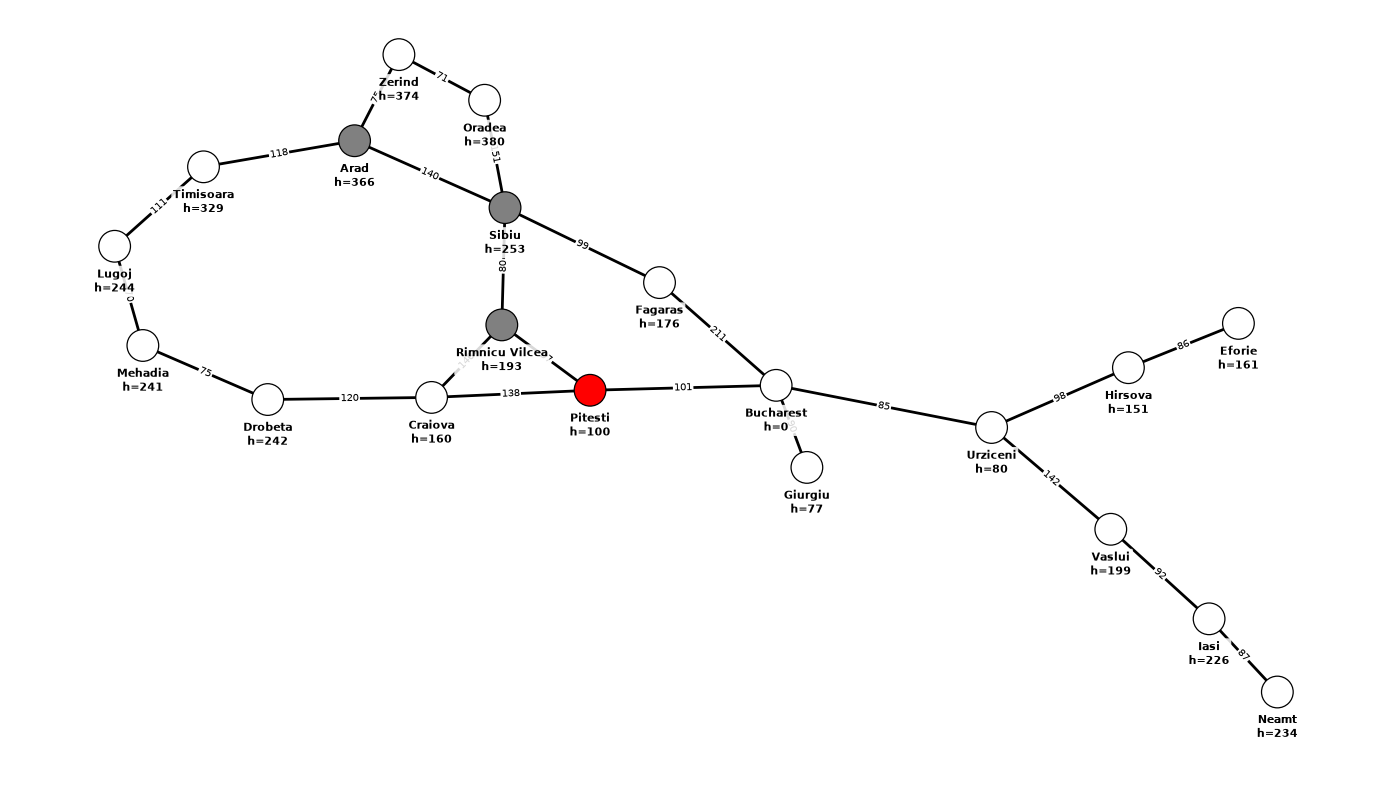

f=615, limit=418, curr='Craiova'
f=418, limit=418, curr='Bucharest'


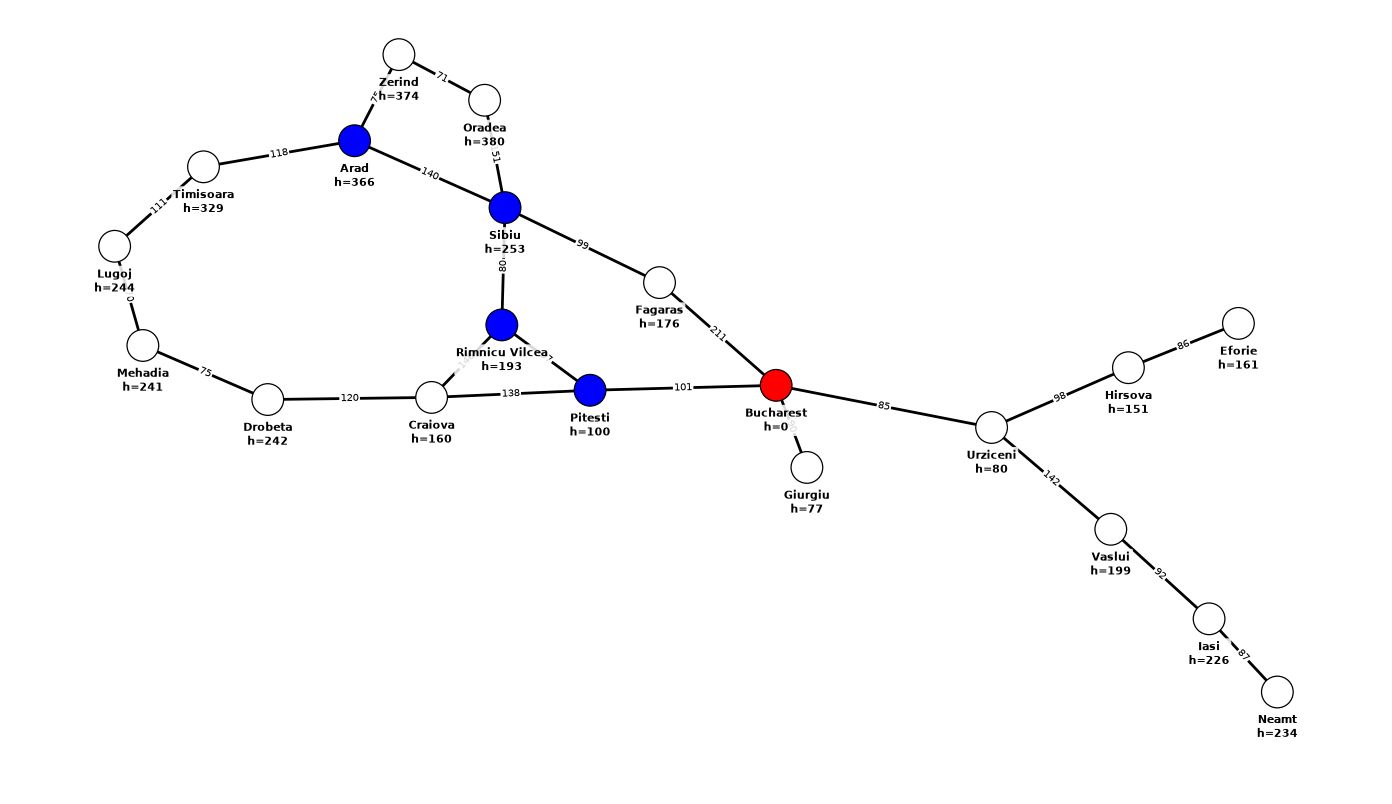

418   Arad -> Sibiu -> Rimnicu Vilcea -> Pitesti -> Bucharest
20 expansions over 6 f-limits


In [28]:
reset_colors(romania)
path, cost = ida_star(romania, "Arad", "Bucharest", draw=True)
print(cost, " ", " -> ".join(path))
print(f"{ida_star.expansions} expansions over {ida_star.rounds} f-limits")

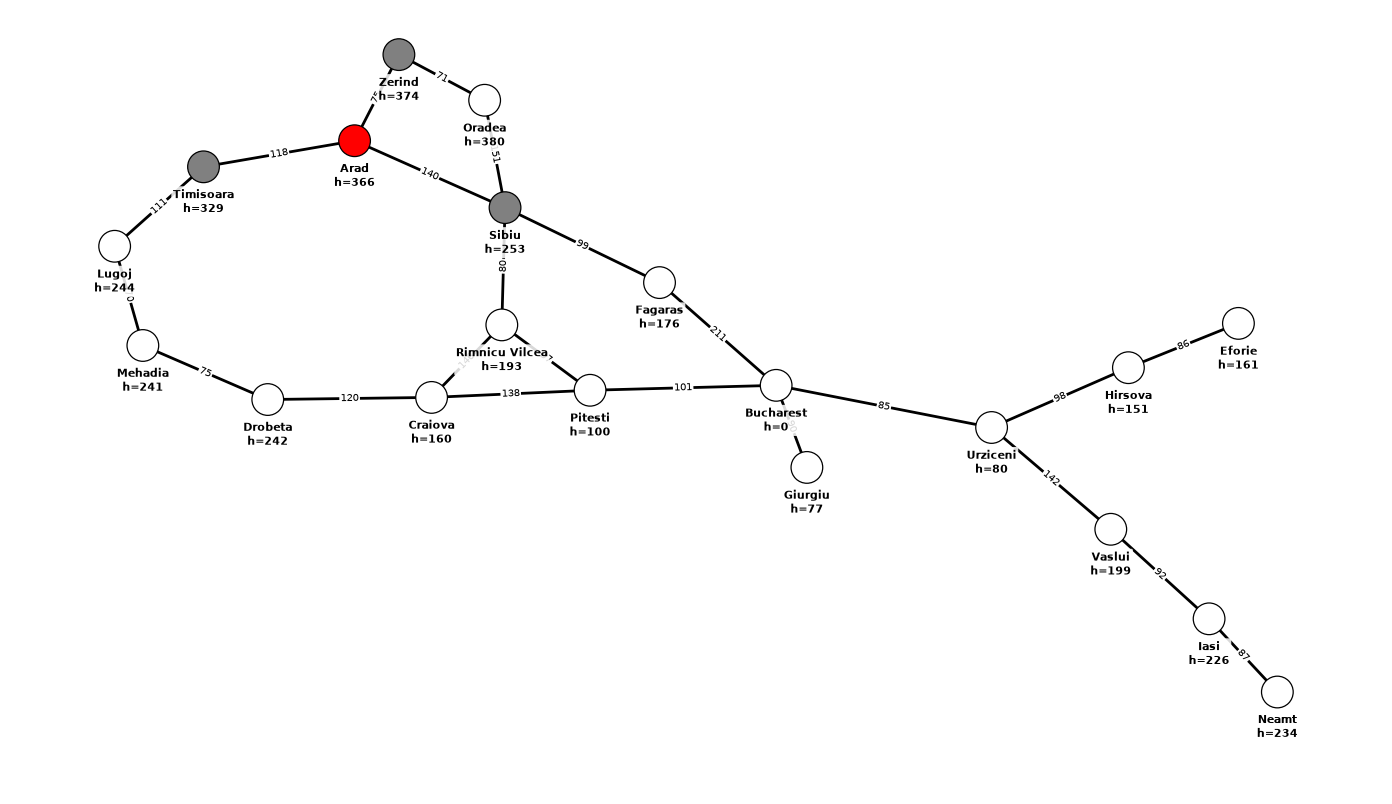

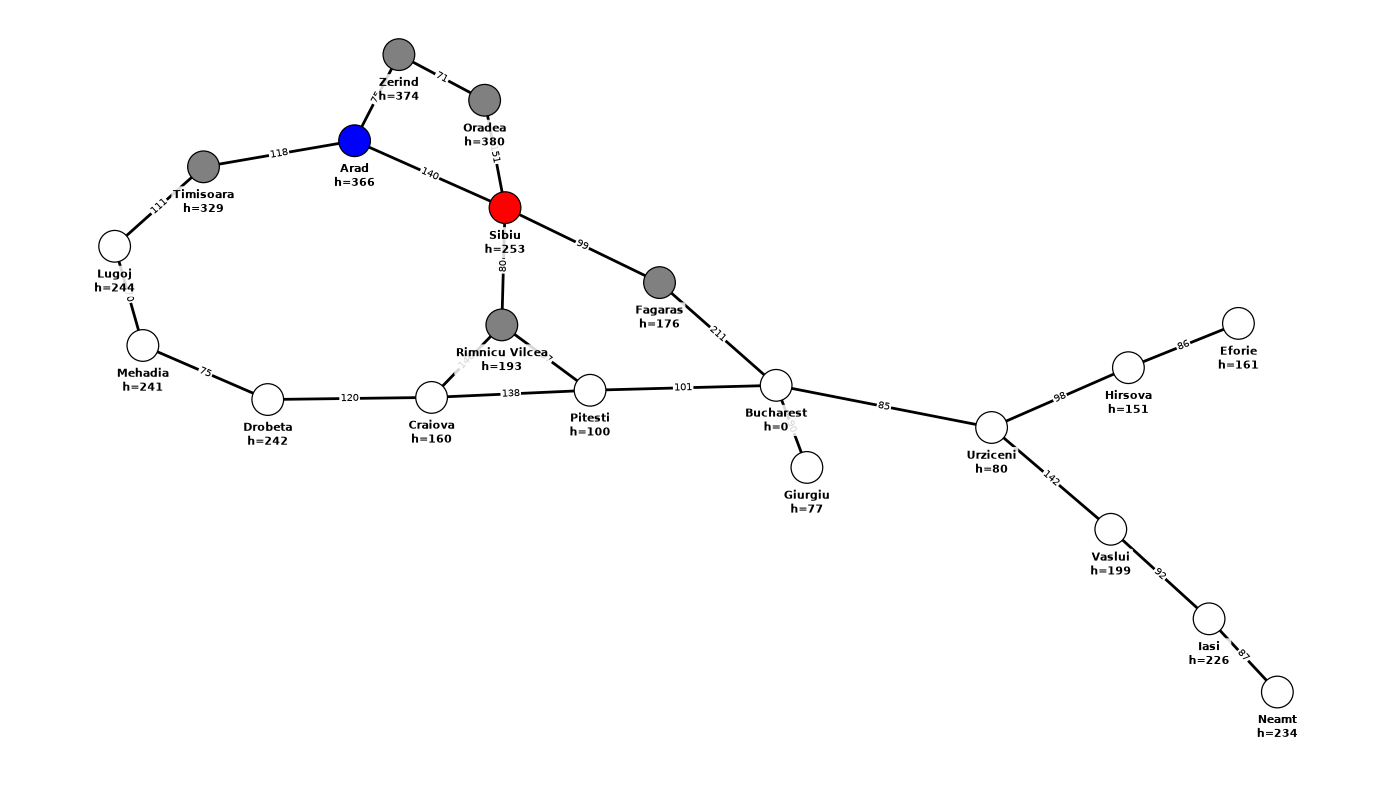

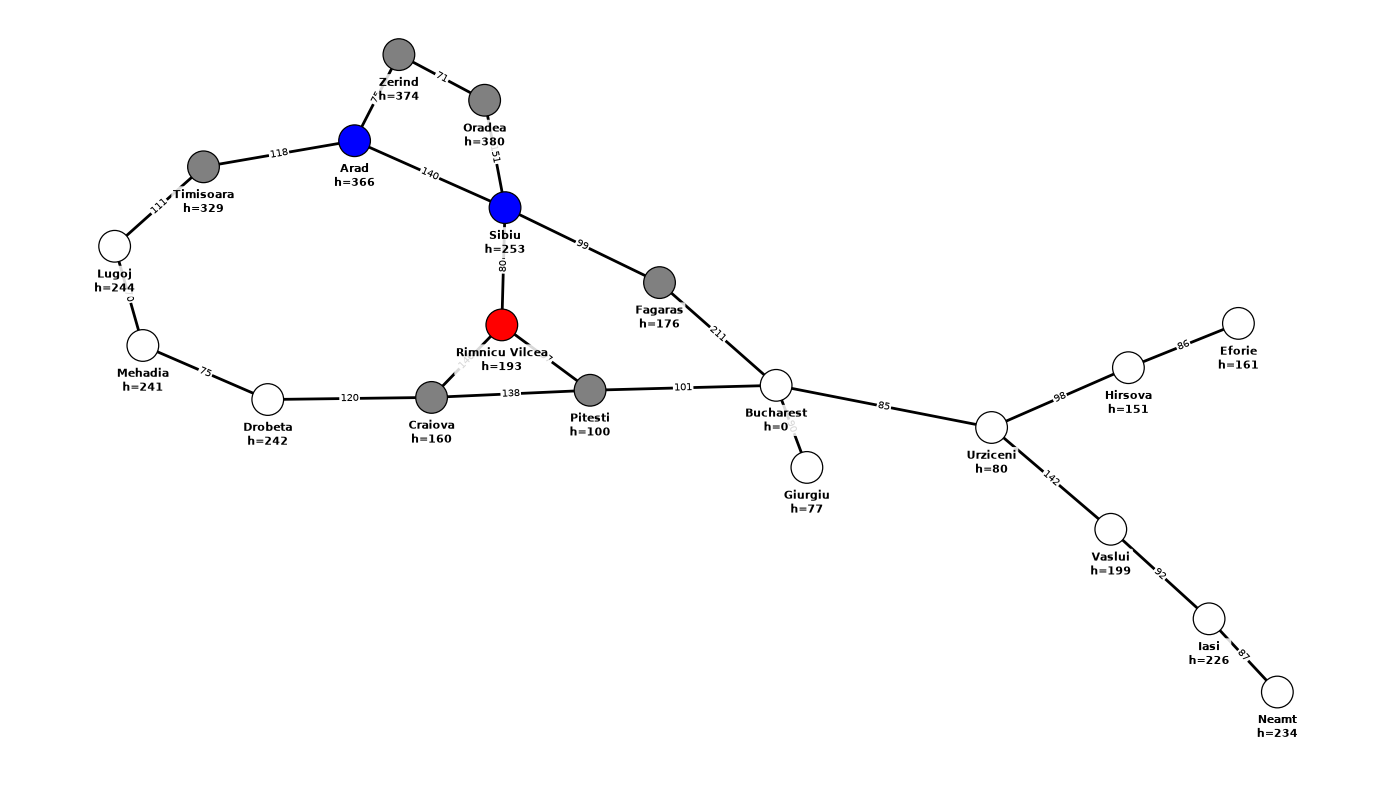

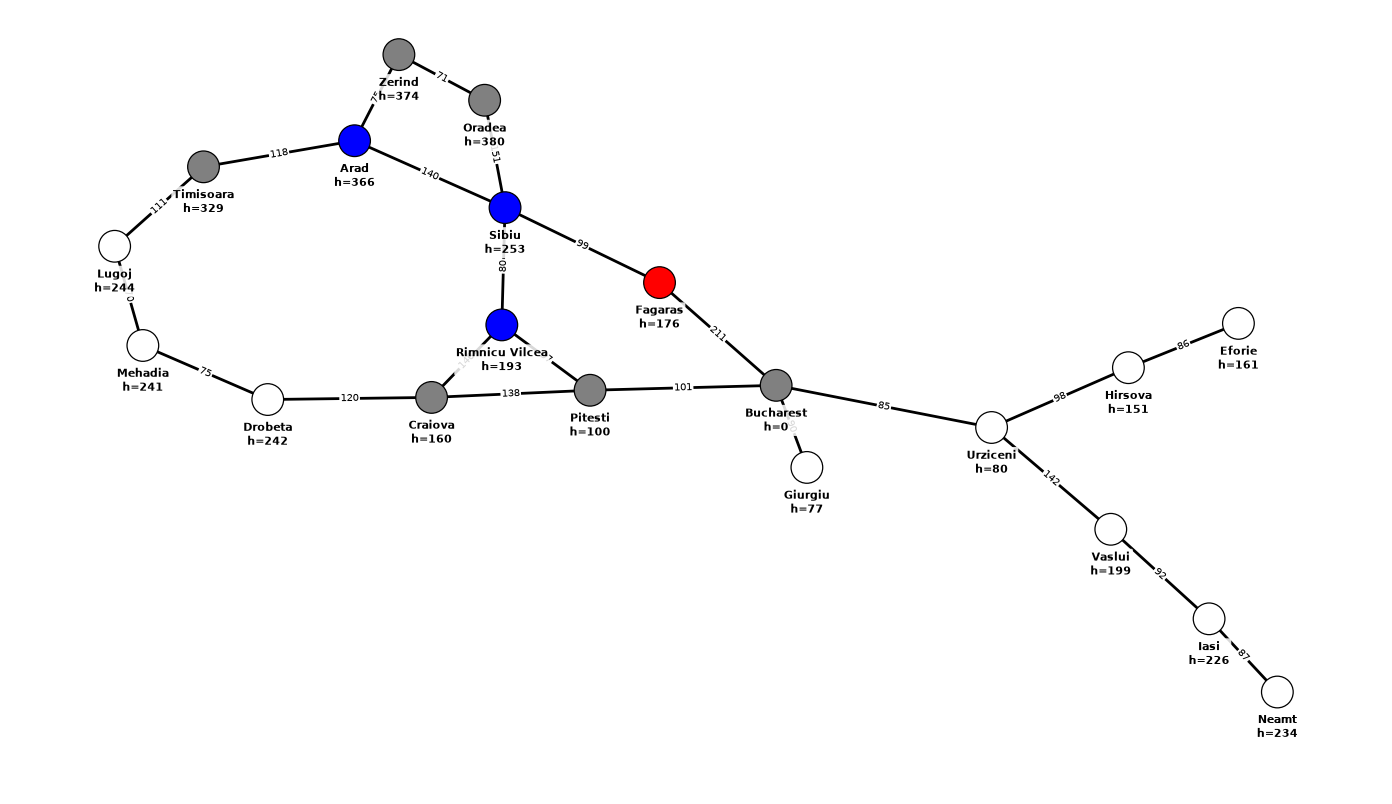

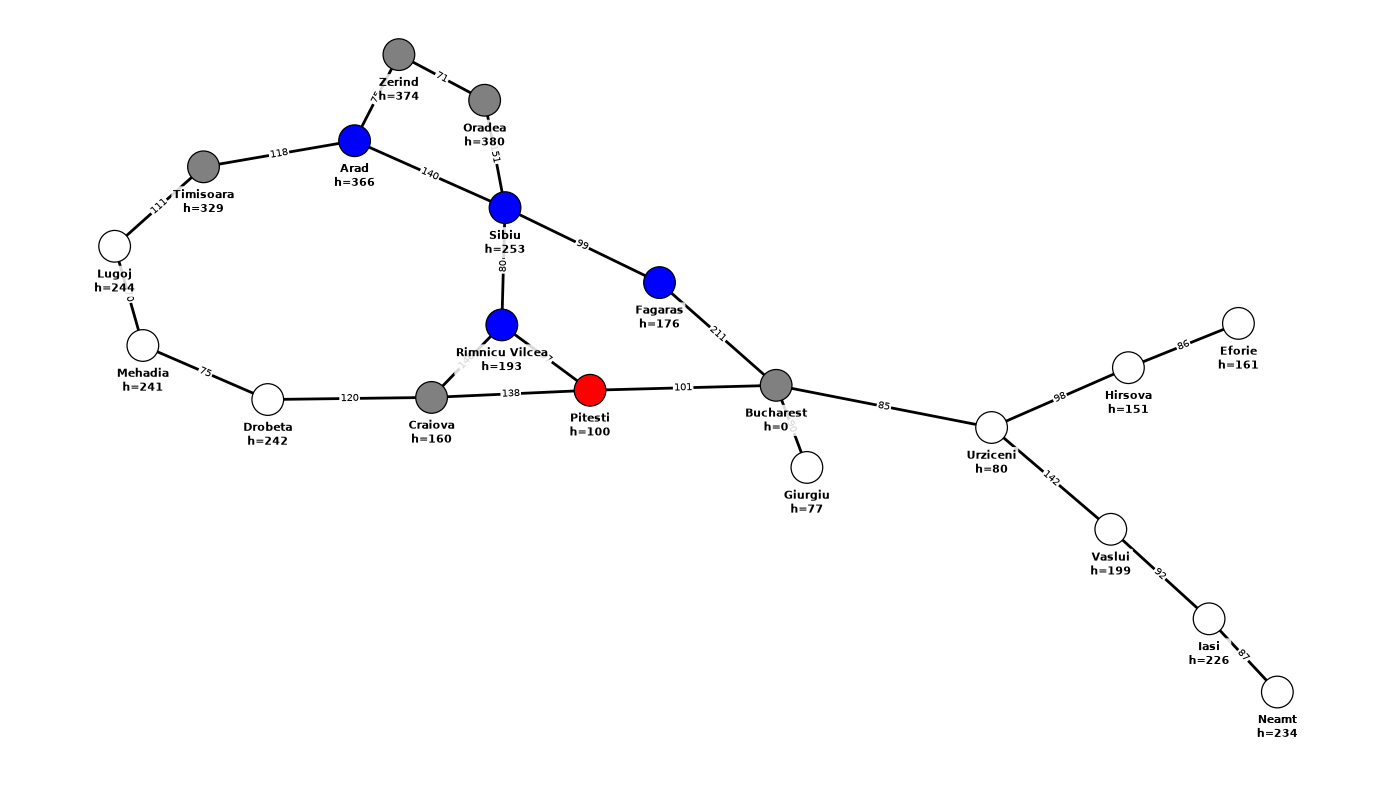

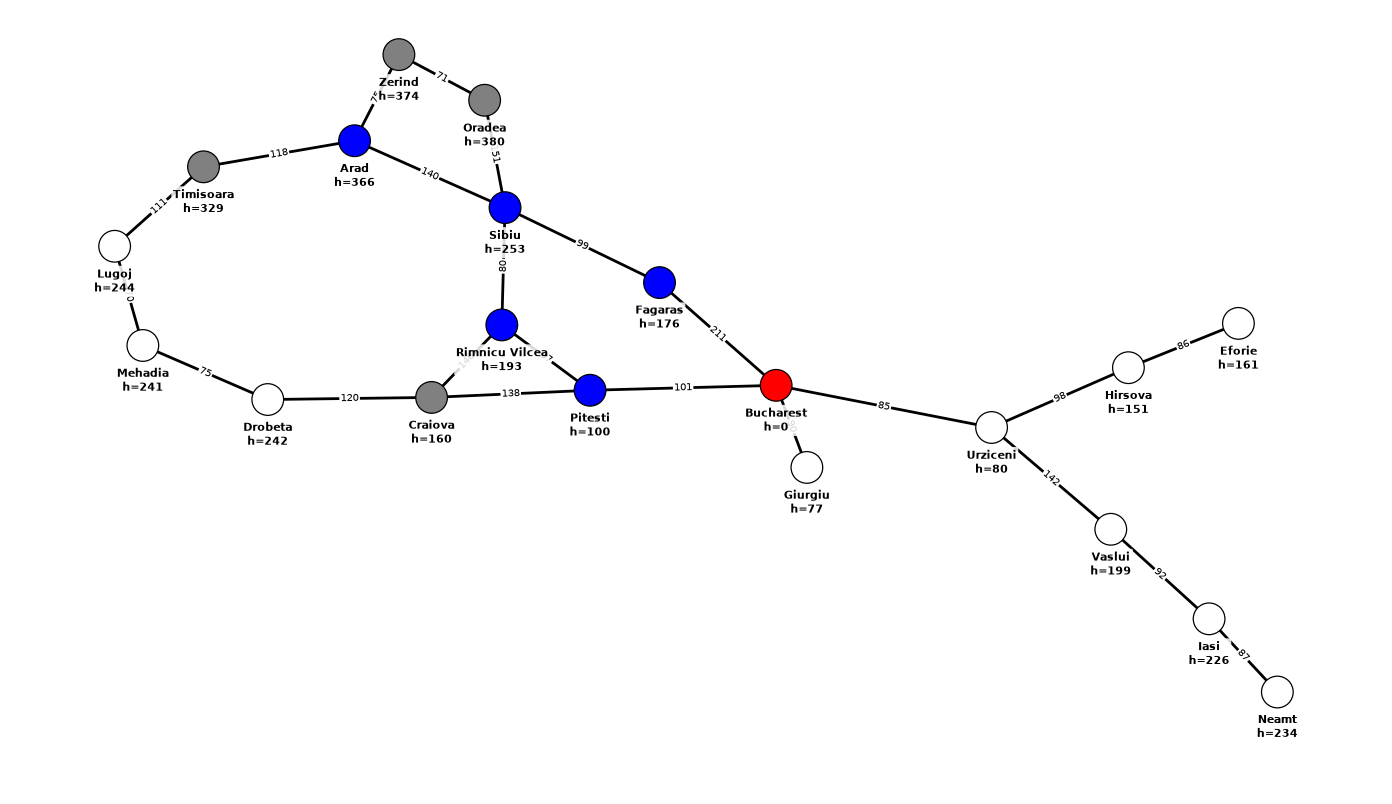

Arad -> Bucharest
    A*   418   IDA* 418   same path: True
    IDA* needed 20 expansions over 6 f-limits


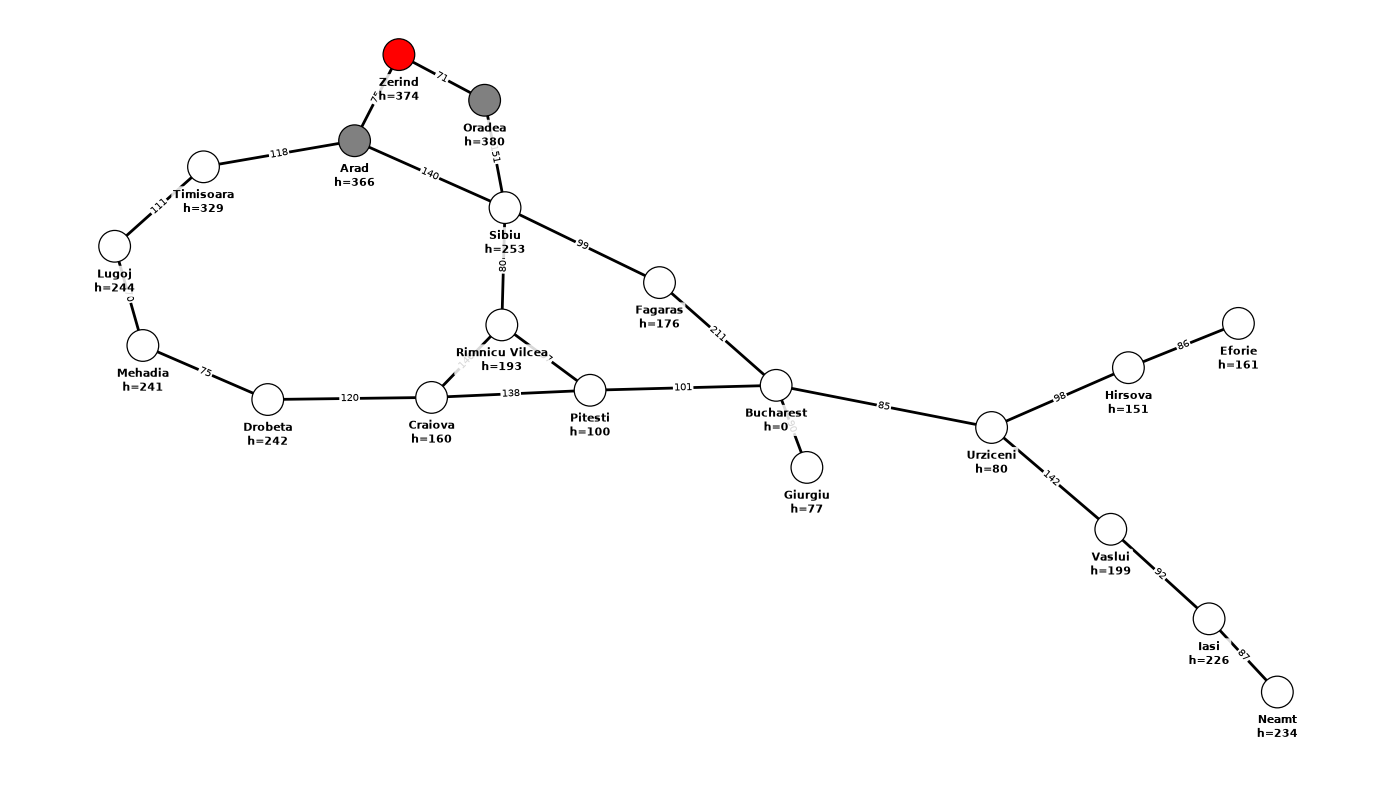

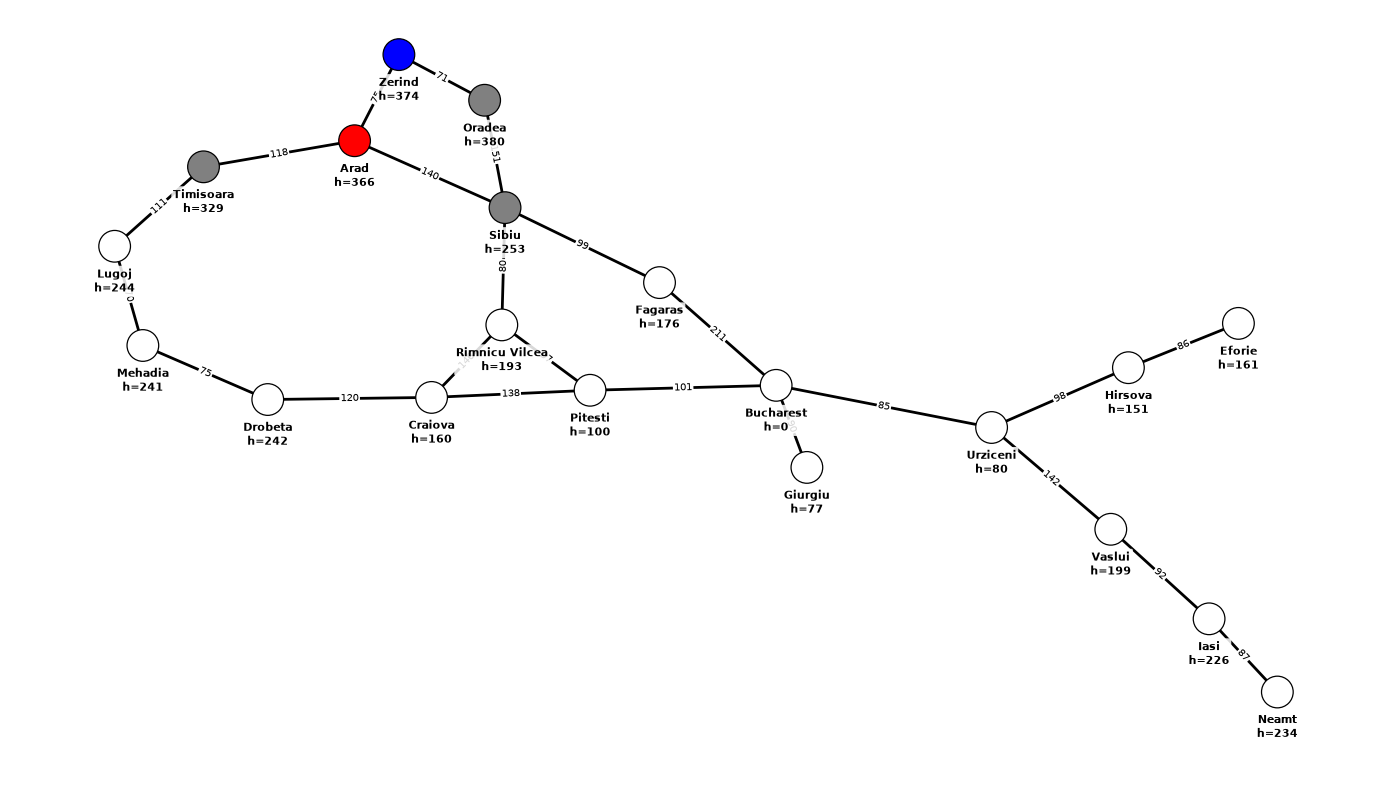

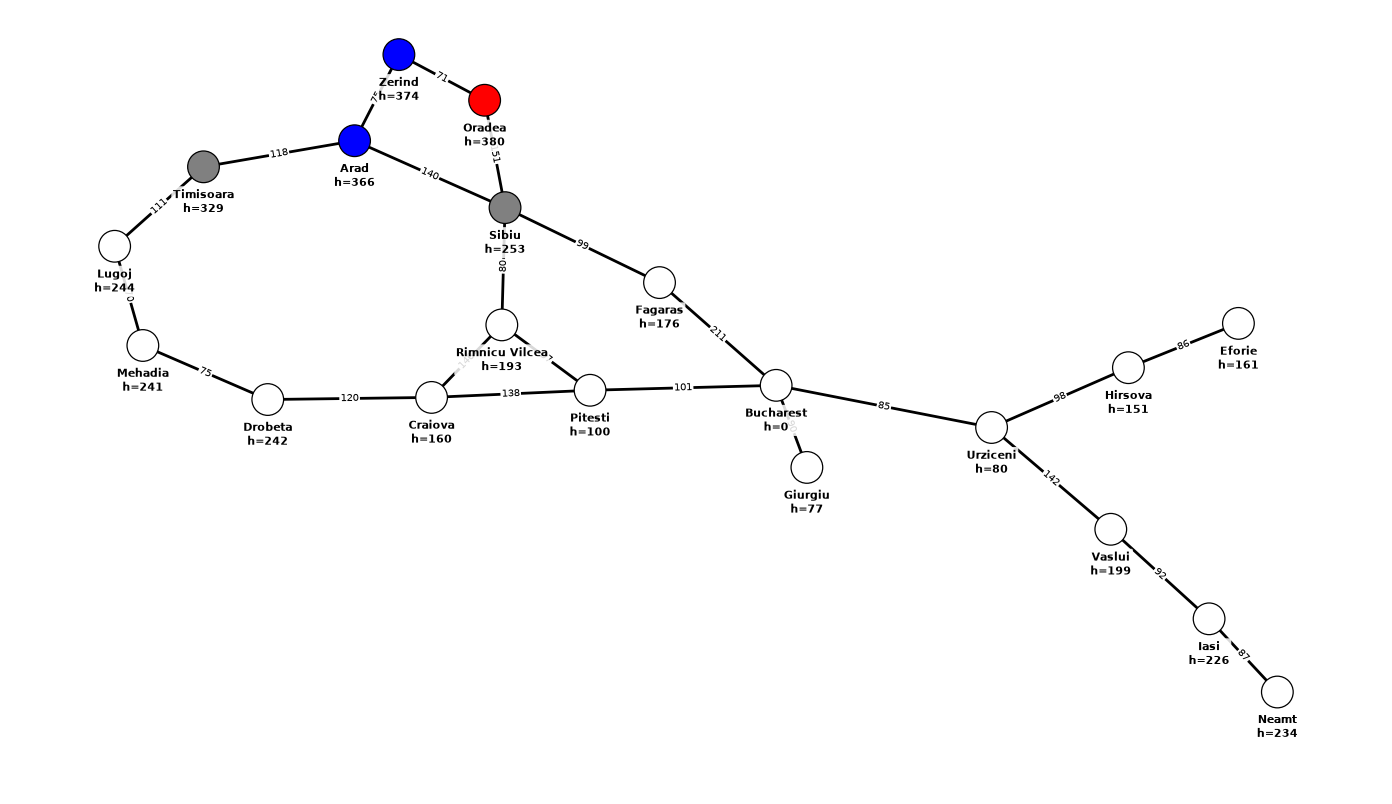

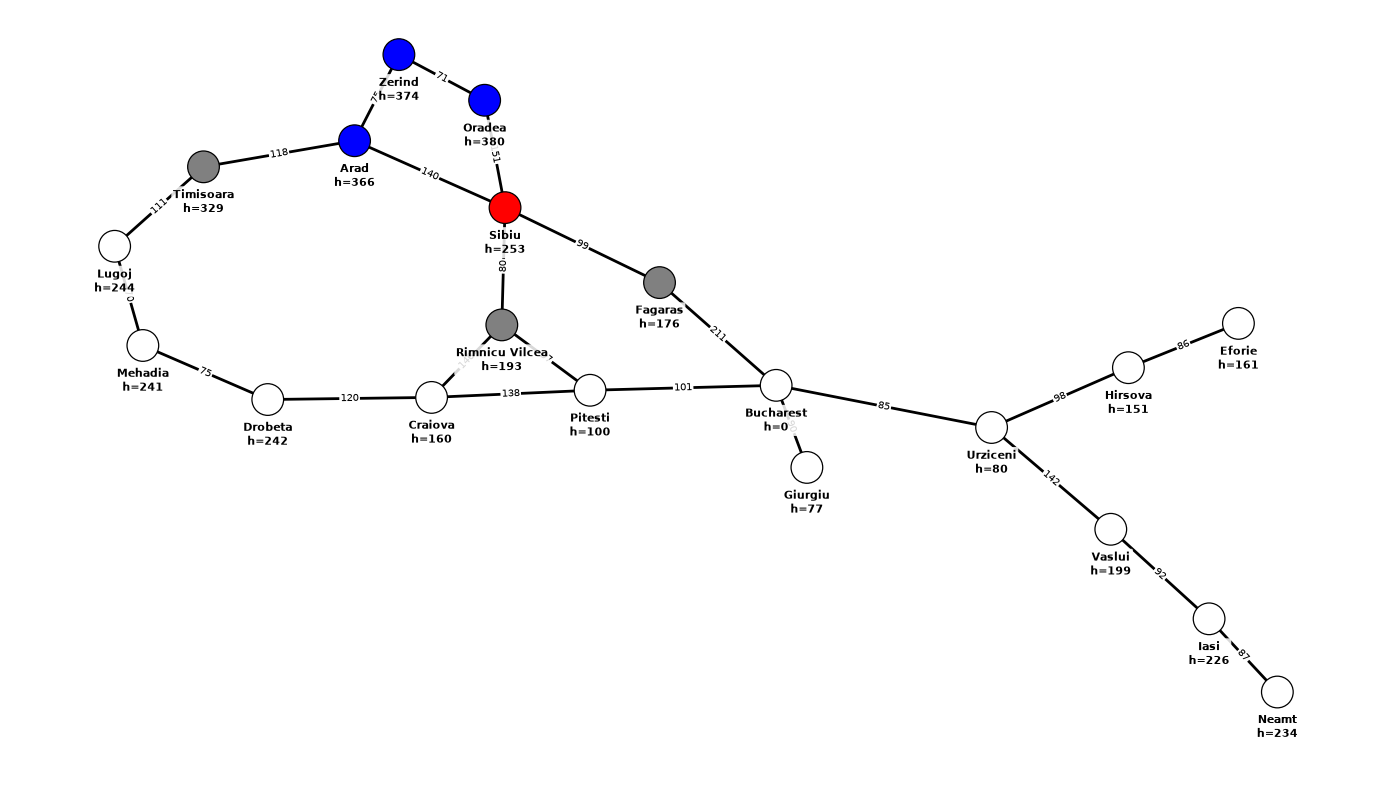

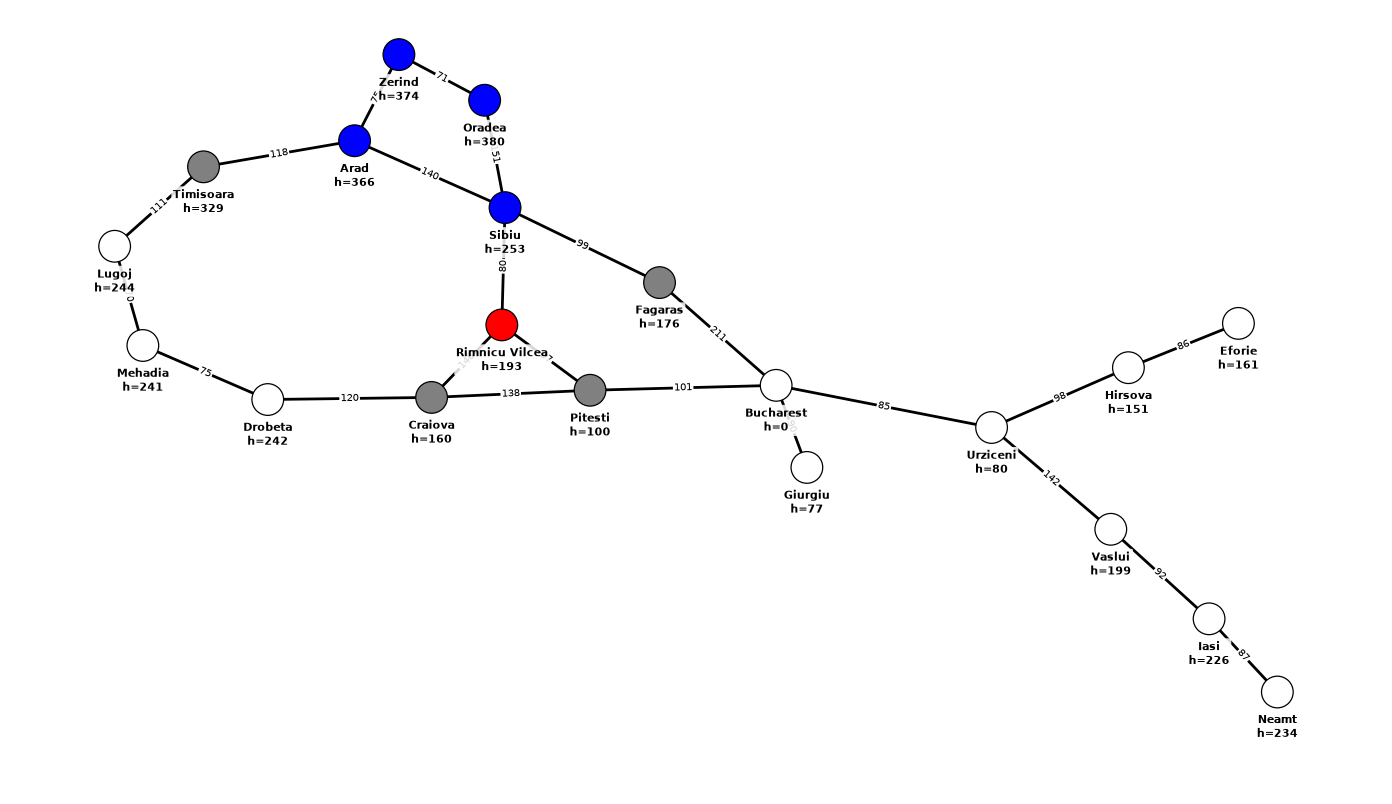

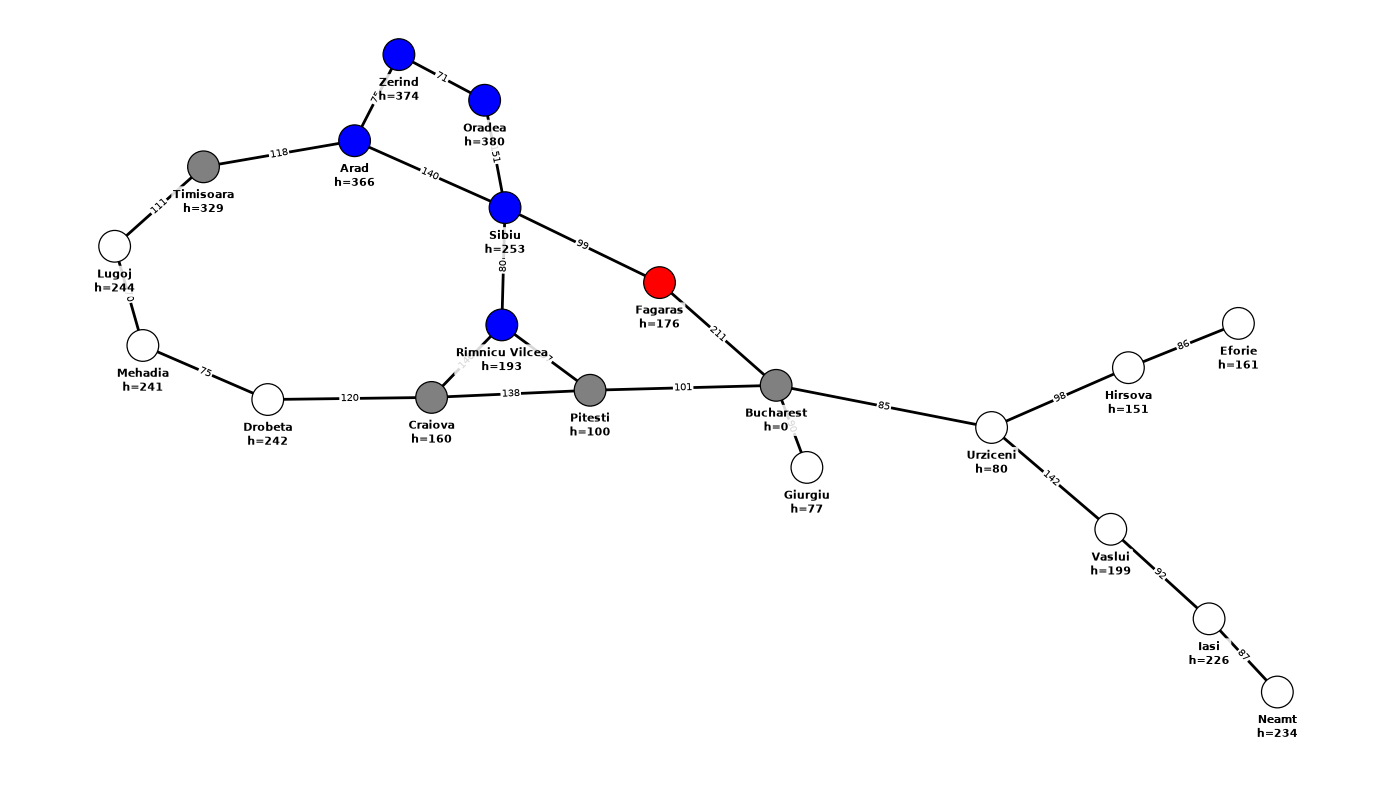

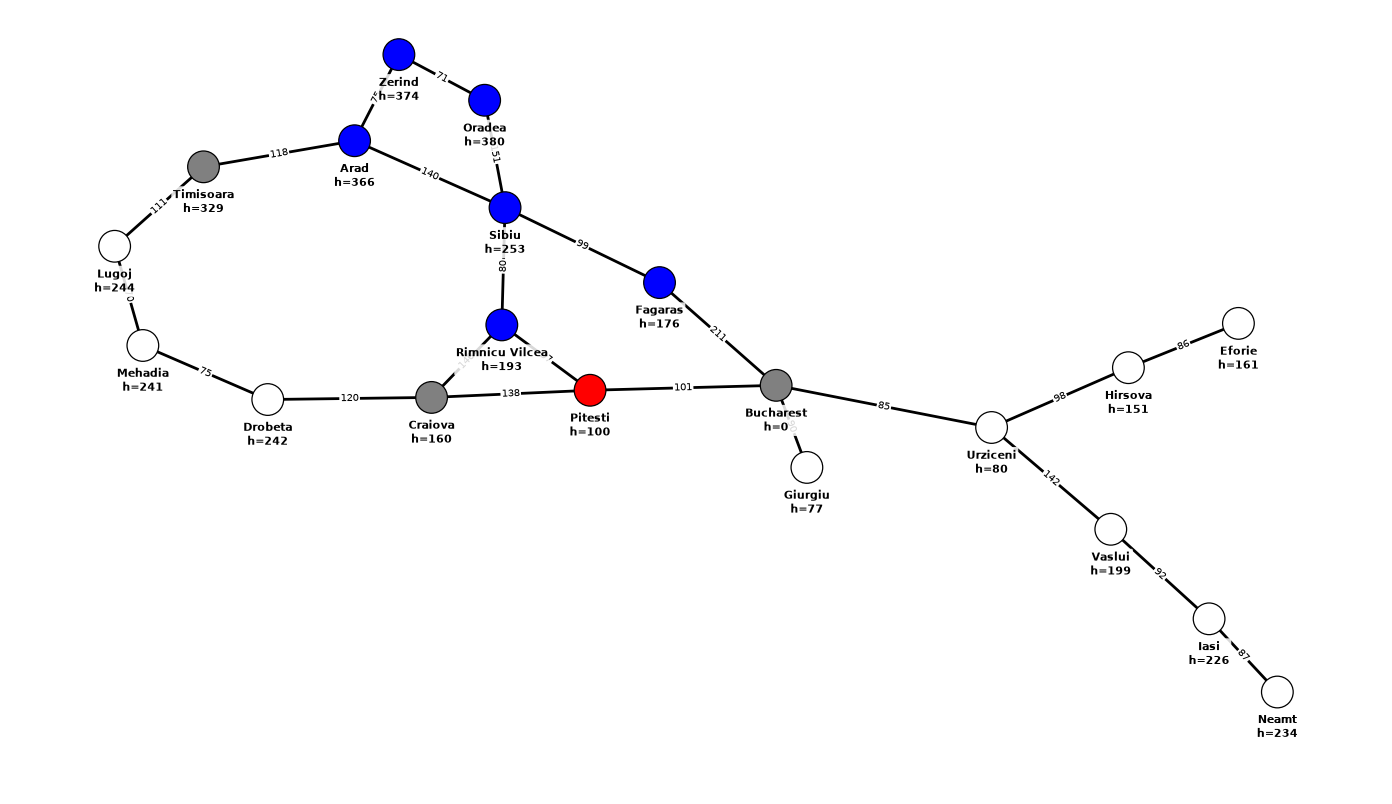

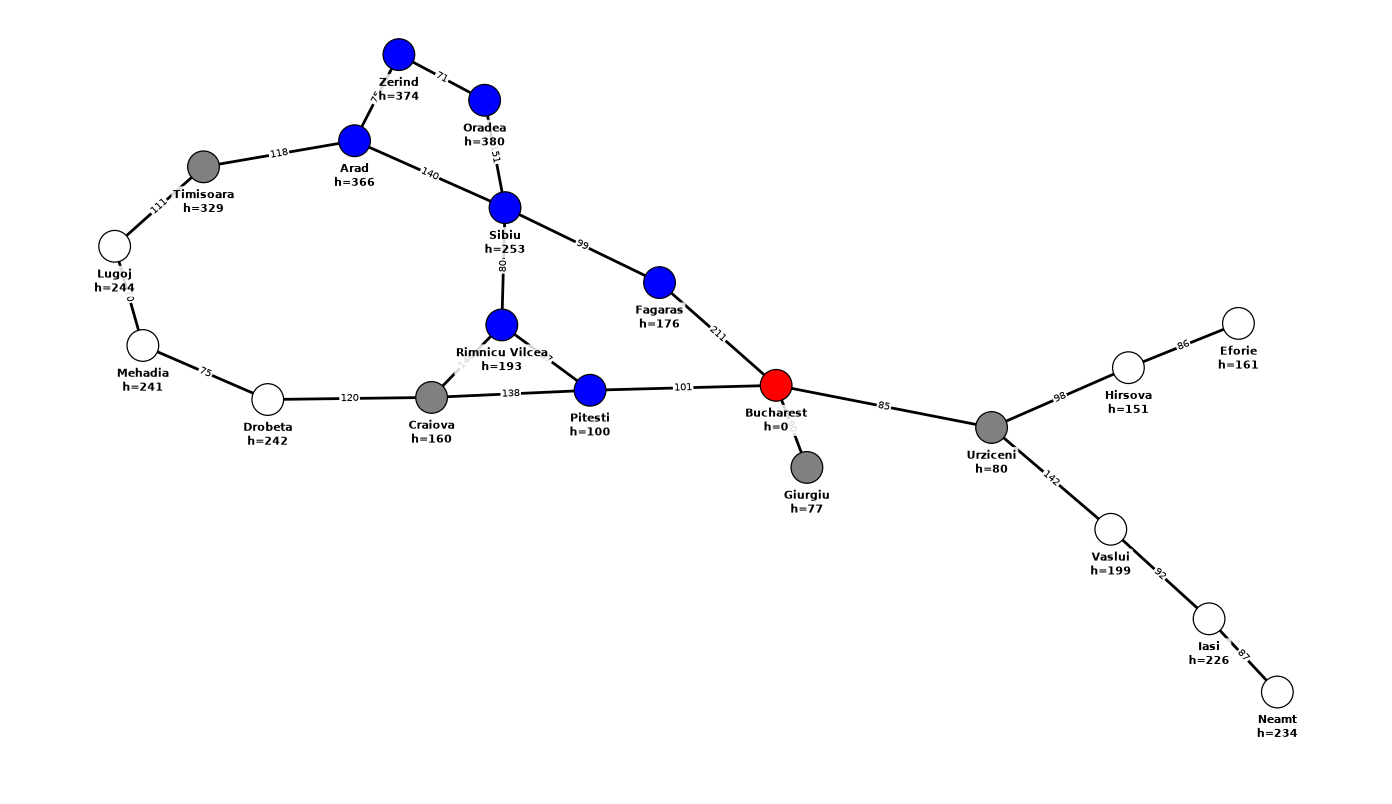

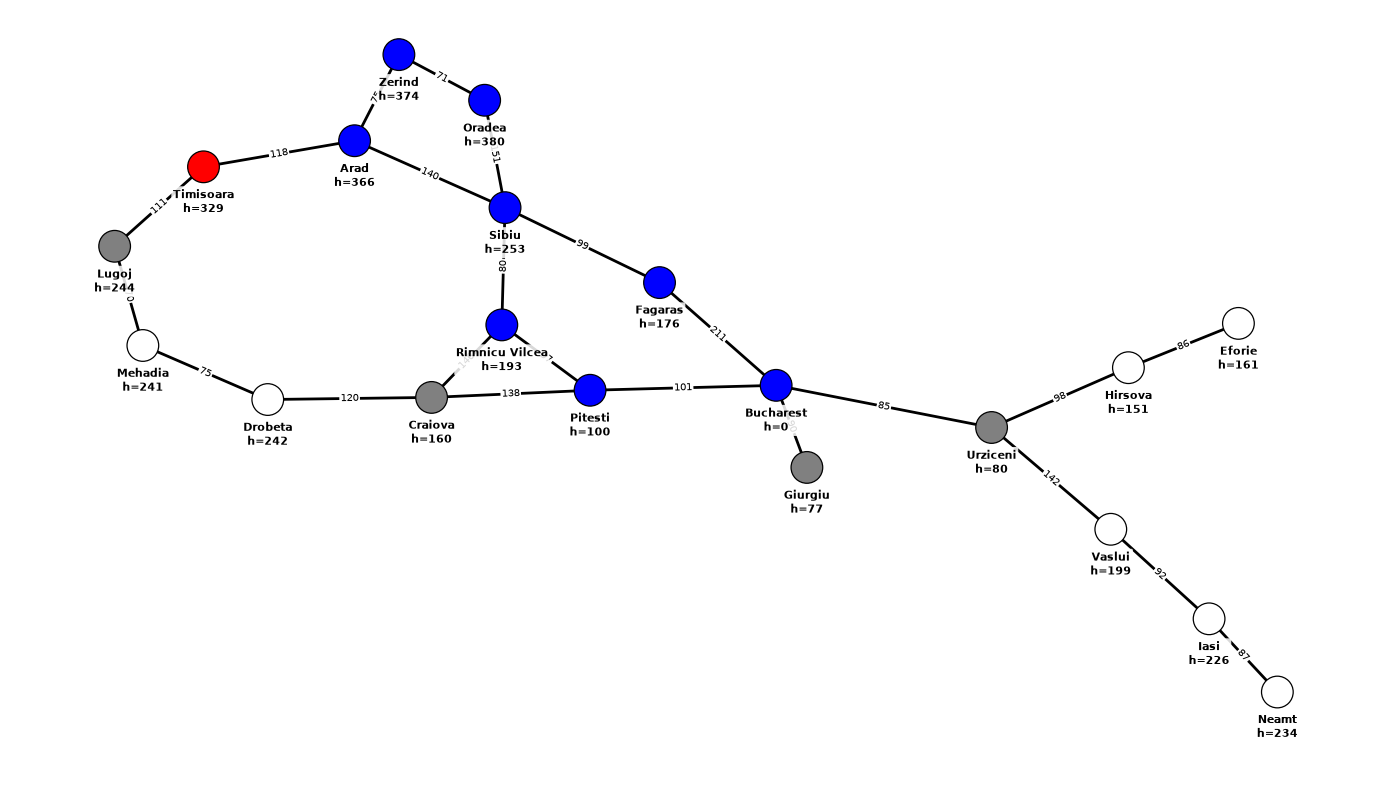

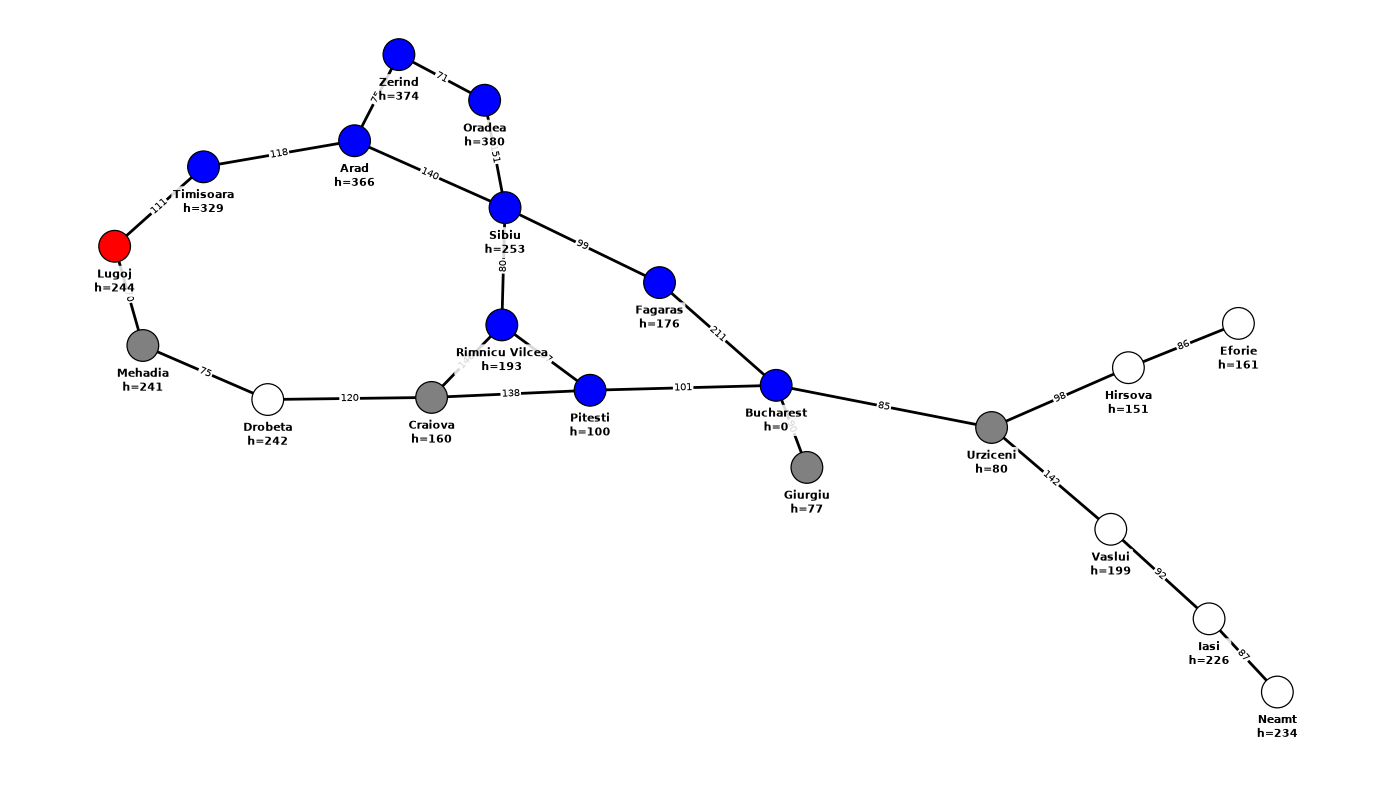

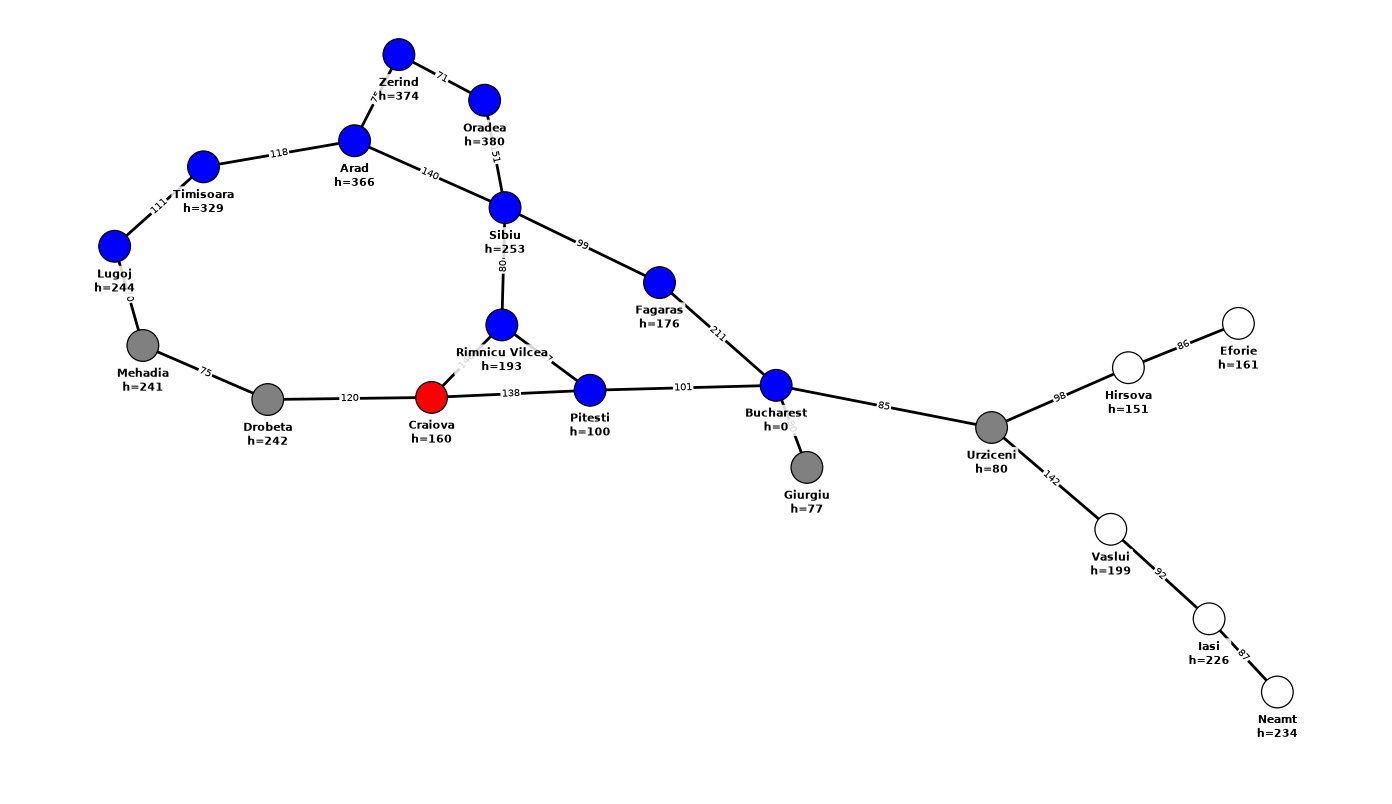

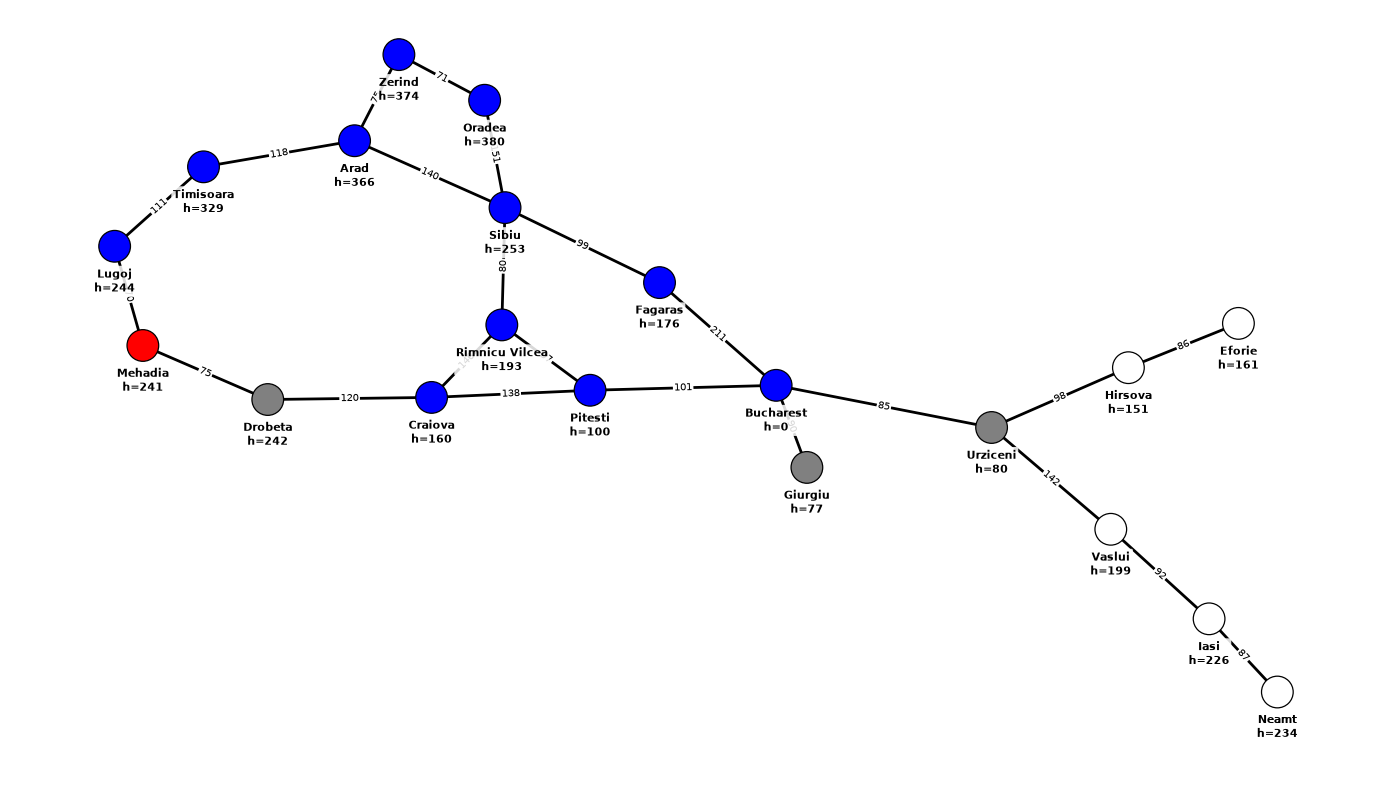

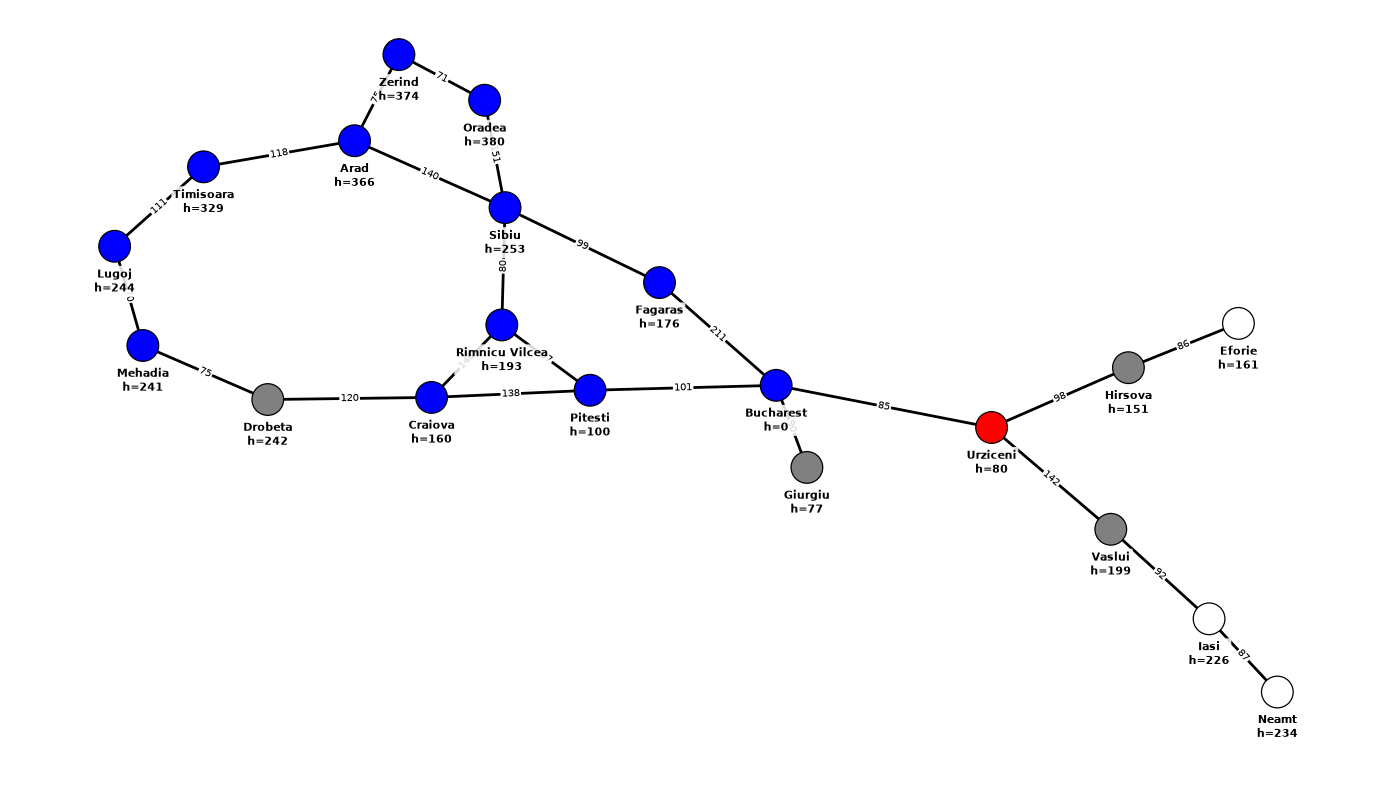

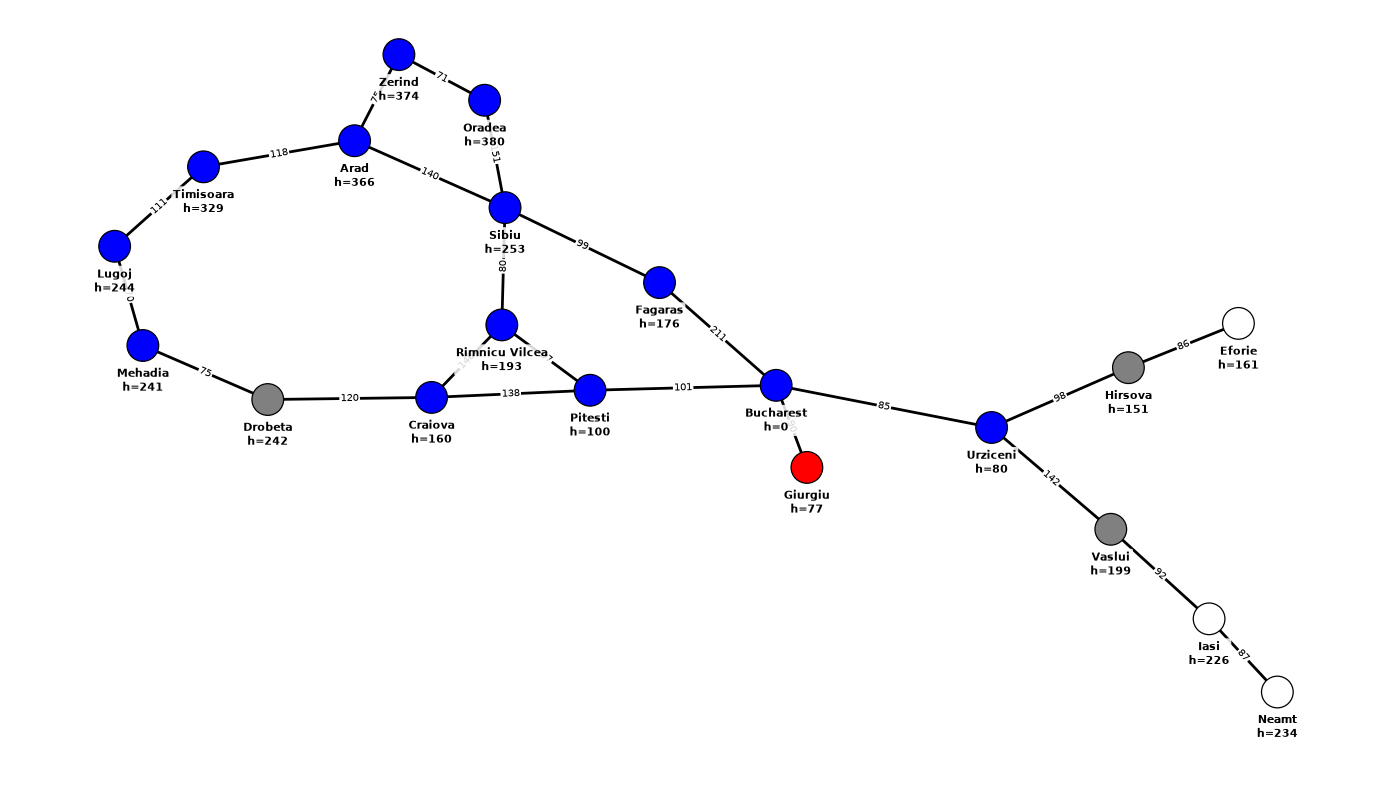

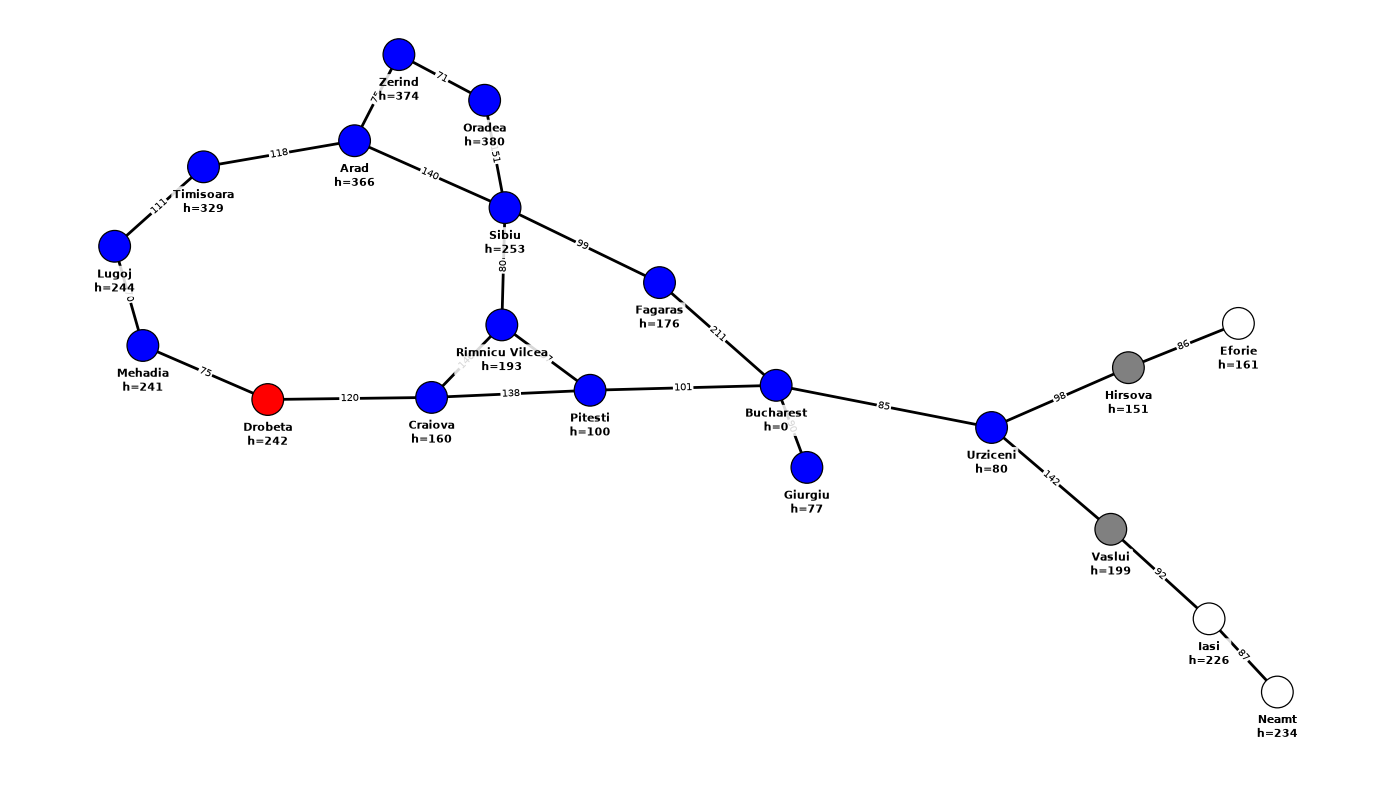

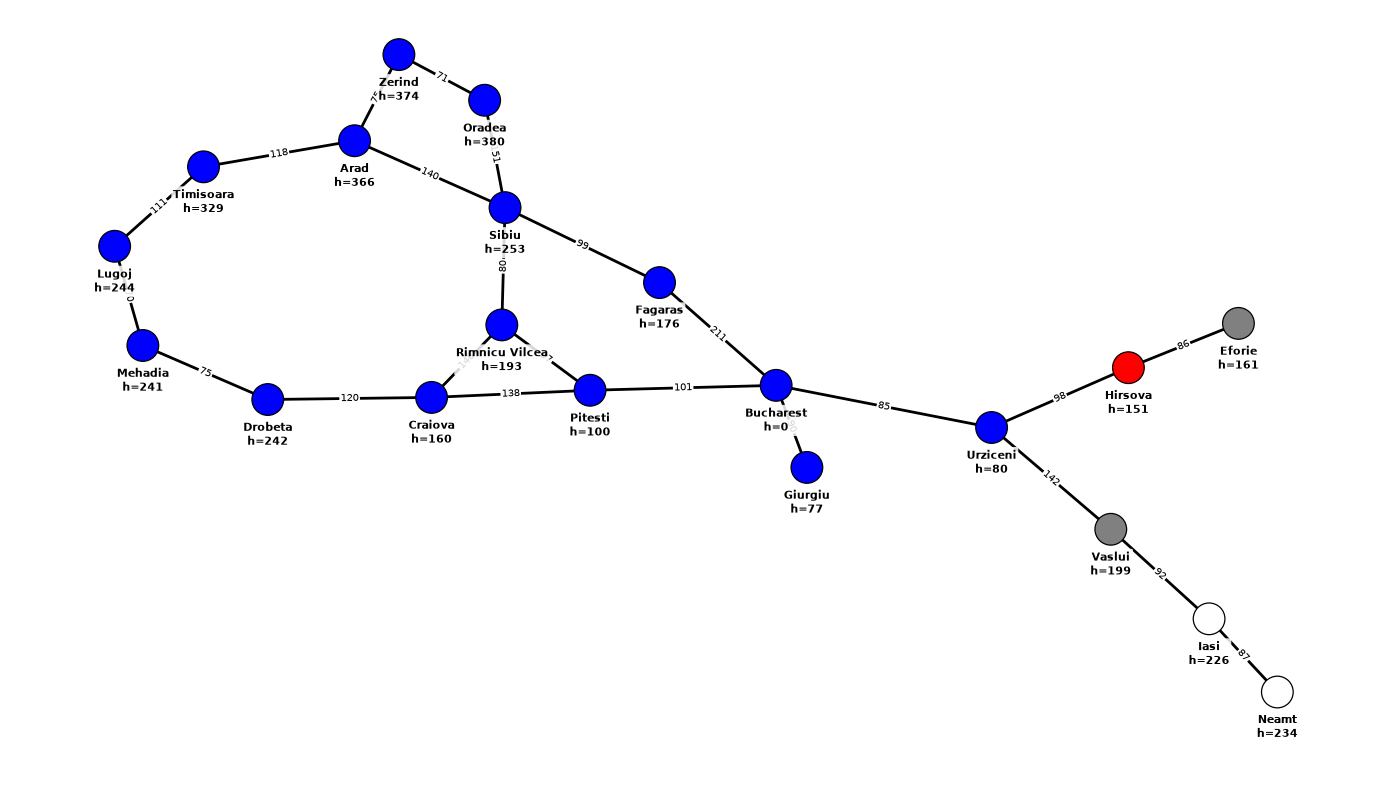

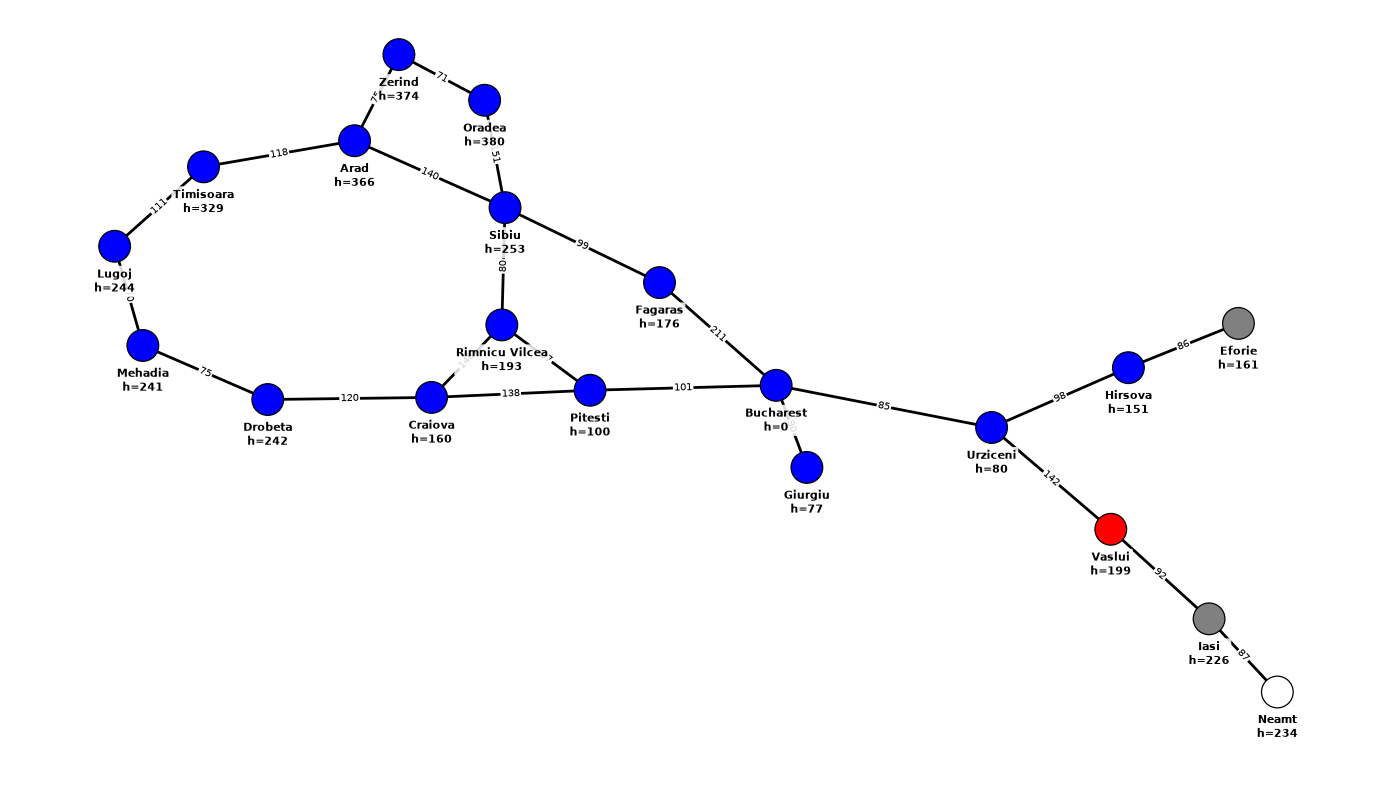

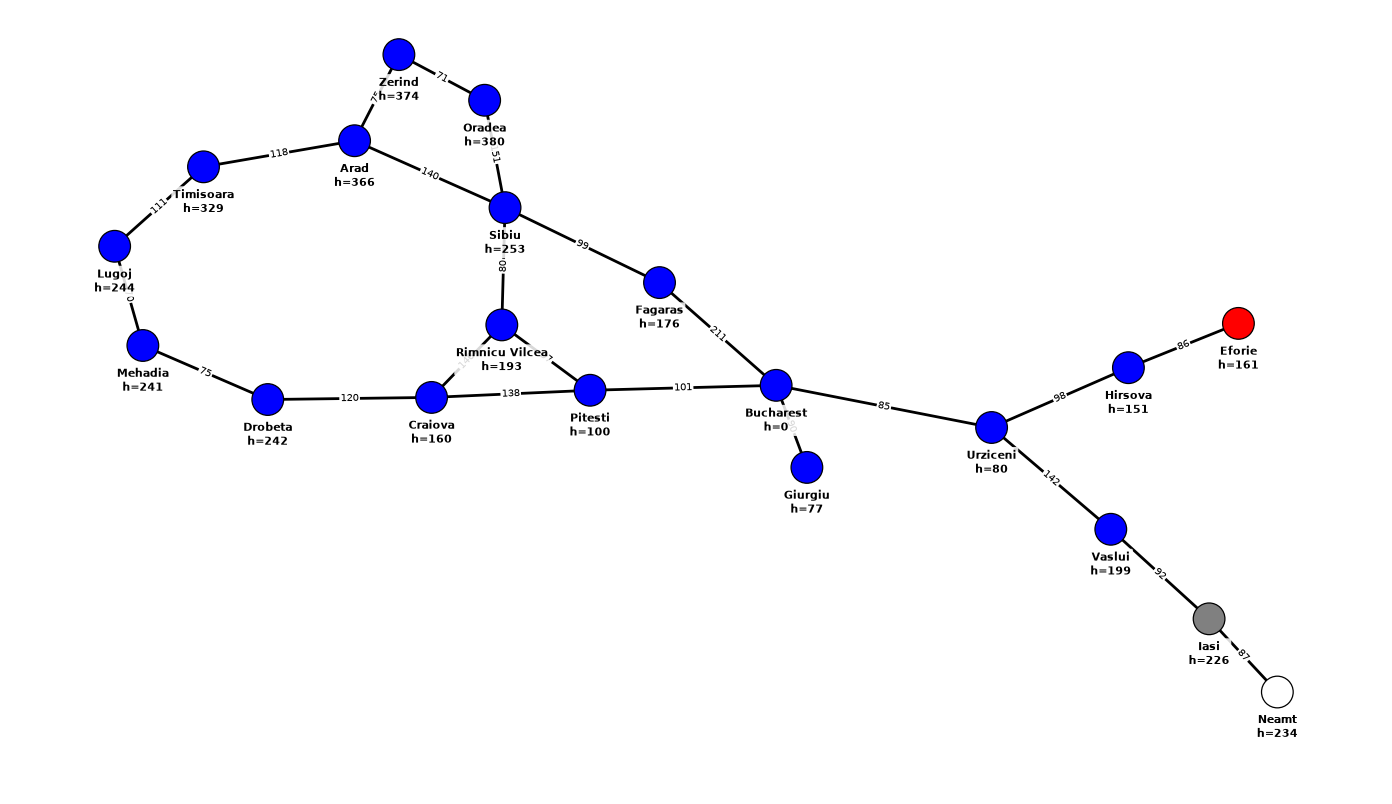

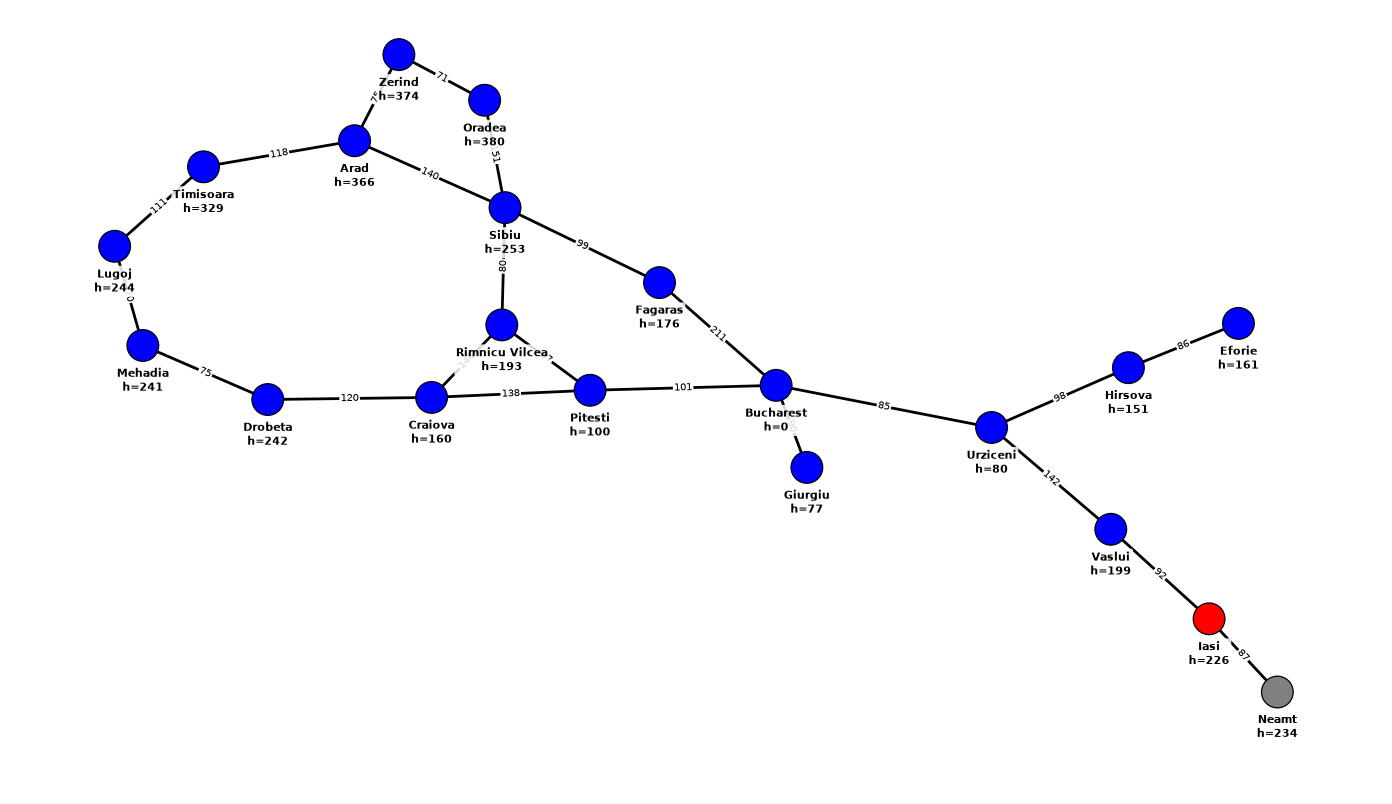

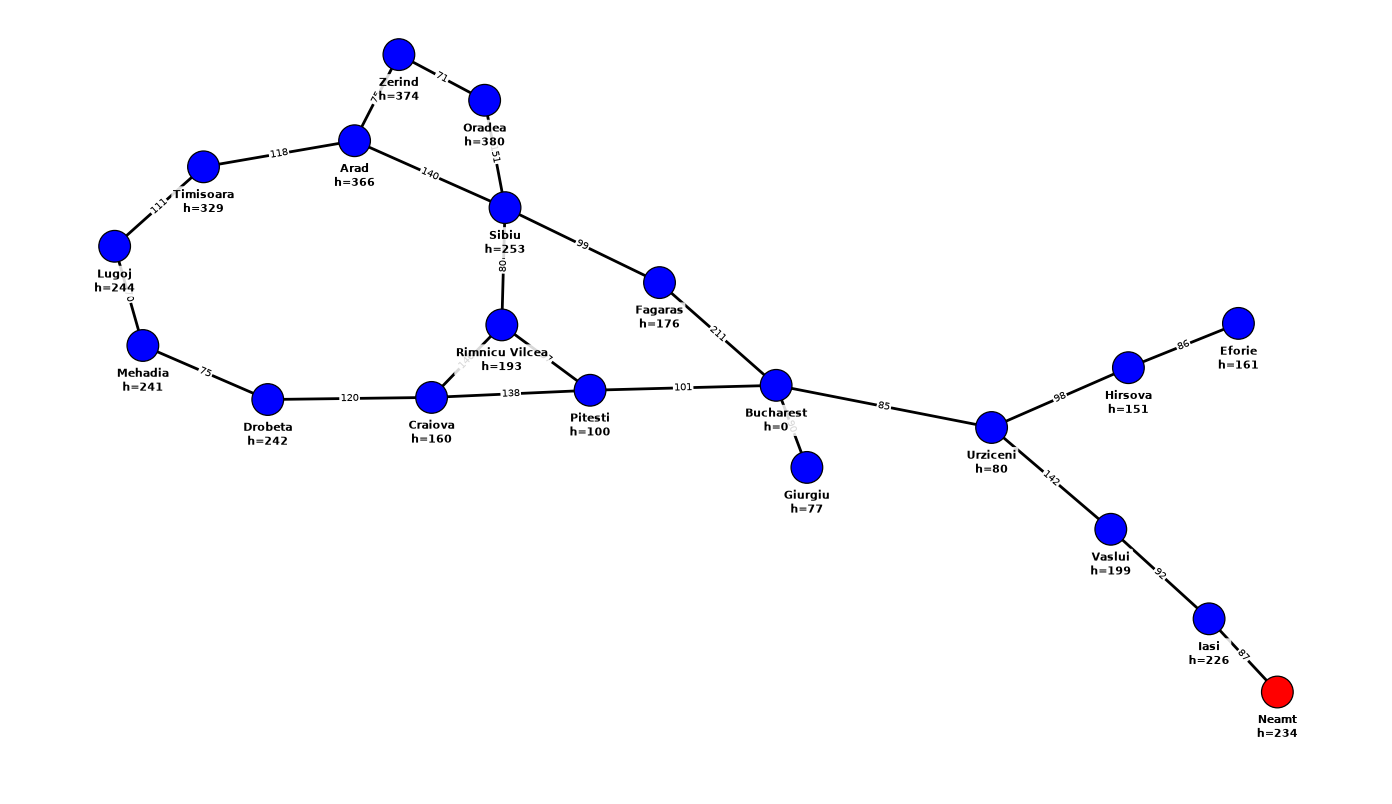

Zerind -> Neamt
    A*   899   IDA* 899   same path: True
    IDA* needed 5848 expansions over 106 f-limits


In [105]:
# The same answers as A*, at a price that depends entirely on how many distinct
# f values the map has. Zerind -> Neamt is the worst pair here.
for s, t in [("Arad", "Bucharest"), ("Zerind", "Neamt")]:
    reset_colors(romania)
    a_path, a_cost = a_star(romania, s, t)
    reset_colors(romania)
    i_path, i_cost = ida_star(romania, s, t)
    print(f"{s} -> {t}")
    print(f"    A*   {a_cost}   IDA* {i_cost}   same path: {a_path == i_path}")
    print(f"    IDA* needed {ida_star.expansions} expansions over "
          f"{ida_star.rounds} f-limits")

It should return the same 418-mile route as A\*. If it returns something cheaper, the limit is
being raised wrongly; if it returns something dearer, you are stopping at the first goal found
rather than the first goal found *within the limit*.

## Memory-Bounded A\*

A\* with the frontier capped at `limit` nodes: when it overflows, drop the worst one.

This is the simple version, and it is really beam search ordered by `f = g + h`. The real SMA\*
backs the dropped node's `f` value up into its parent so nothing is forgotten permanently — worth
understanding, not required here.

The question to answer with it: what is the smallest `limit` that still returns the optimal 418?

In [31]:
def memory_bounded_a_star(g, start, end, limit=3, draw=True):
    """A* that never holds more than `limit` nodes in the frontier.

    Same as A*, except that after pushing successors you discard the worst
    entries until at most `limit` remain.

    Returns (path, cost), or (None, None) if the goal was dropped or is
    unreachable.
    """
    priority_q = [(g.nodes[start].heuristic, start, 0, start)]

    pred = dict()

    while (len(priority_q) != 0):
        _, curr, dist, parent = heapq.heappop(priority_q)

        if g.nodes[curr].color == "blue":
            continue

        pred[curr] = parent

        if curr == end:
            path = []
            temp = end
            while temp != start:
                path.append(temp)
                temp = pred[temp]
            path.append(start)
            g.nodes[curr].color = "green"
            if draw:
                display_graph(g, curr)
            return (path[::-1], dist)

        for node, w in g.edges[curr]:
            if g.nodes[node].color != "blue":
                g.nodes[node].color = "gray"
                heapq.heappush(
                    priority_q,
                    (dist + w + g.nodes[node].heuristic, node, dist + w, curr),
                )

        # The only difference from A*: the frontier is not allowed to grow. The
        # `limit` most promising entries survive, the rest are gone for good.
        priority_q = heapq.nsmallest(limit, priority_q)
        heapq.heapify(priority_q)

        if draw:
            display_graph(g, curr)
        g.nodes[curr].color = "blue"

    return (None, None)

In [32]:
for limit in (1, 2, 3, 5, 10):
    reset_colors(romania)
    path, cost = memory_bounded_a_star(romania, "Arad", "Bucharest", limit=limit, draw=False)
    print(f"limit {limit:2}  {cost}  {' -> '.join(path) if path else 'no path'}")

limit  1  418  Arad -> Sibiu -> Rimnicu Vilcea -> Pitesti -> Bucharest
limit  2  418  Arad -> Sibiu -> Rimnicu Vilcea -> Pitesti -> Bucharest
limit  3  418  Arad -> Sibiu -> Rimnicu Vilcea -> Pitesti -> Bucharest
limit  5  418  Arad -> Sibiu -> Rimnicu Vilcea -> Pitesti -> Bucharest
limit 10  418  Arad -> Sibiu -> Rimnicu Vilcea -> Pitesti -> Bucharest


## Recursive Best-First Search

Best-first search on linear memory, and a different bargain from IDA\*.

RBFS follows the route A\* would follow, but it only ever holds the current path and each node's
siblings. When the path it is on starts to look worse than something it passed higher up, it
unwinds — and as it unwinds it **backs up** the best `f` it found below into the node it came
from. That number is the memory: if the search ever comes back this way, it already knows how bad
things got down there and does not have to find out again.

That is the whole difference from IDA\*, which forgets everything between rounds. RBFS forgets the
nodes too, but keeps one number per node it retreats through — and it usually expands far fewer
nodes for it.

In [33]:
def rbfs(g, start, end, draw=False):
    """Recursive best-first search.

    Best-first search on linear memory. It follows the most promising route
    like A* would, but keeps only the current path plus each node's siblings.
    When the route it is on starts looking worse than an alternative it left
    behind somewhere above, it unwinds -- and as it unwinds it *remembers*, by
    backing the best f found below up into the node it came from. That backed-up
    value is what stops it re-exploring a bad subtree over and over.

    Returns (path, cost), or (None, None) if there is no path.
    """
    INF = float("inf")
    rbfs.expansions = 0

    def search(city, cost_so_far, f_value, f_limit, path, on_path):
        """Returns (solution path or None, the backed-up f value for `city`)."""
        if city == end:
            return list(path), f_value

        rbfs.expansions += 1
        if draw:
            display_graph(g, city)

        # Each successor starts with f = max(g + h, f of the parent). Inheriting
        # the parent's f is what carries the memory of earlier searches down.
        successors = []
        for nxt, w in g.edges[city]:
            if nxt in on_path:
                continue
            child_cost = cost_so_far + w
            child_f = max(child_cost + g.nodes[nxt].heuristic, f_value)
            successors.append([child_f, nxt, child_cost])

        if not successors:
            return None, INF

        while True:
            successors.sort(key=lambda s: s[0])
            best = successors[0]

            # Everything here is worse than something we could be doing higher
            # up the tree. Give up and hand back how bad it got.
            if best[0] > f_limit:
                return None, best[0]

            alternative = successors[1][0] if len(successors) > 1 else INF

            path.append(best[1])
            on_path.add(best[1])
            g.nodes[best[1]].color = "gray"

            result, best[0] = search(best[1], best[2], best[0],
                                     min(f_limit, alternative), path, on_path)

            path.pop()
            on_path.discard(best[1])
            g.nodes[best[1]].color = "white"

            if result is not None:
                return result, best[0]

    result, _ = search(start, 0, g.nodes[start].heuristic, INF, [start], {start})

    if result is None:
        return (None, None)

    cost = 0
    for a, b in zip(result, result[1:]):
        cost += min(w for n, w in g.edges[a] if n == b)
    return (result, cost)

In [36]:
reset_colors(romania)
path, cost = rbfs(romania, "Arad", "Bucharest")
print(cost, " ", " -> ".join(path))
print(f"{rbfs.expansions} expansions")

418   Arad -> Sibiu -> Rimnicu Vilcea -> Pitesti -> Bucharest
6 expansions


## Weighted A\*

`f(n) = g(n) + W * h(n)`, with `W >= 1`.

At `W = 1` this is A\*. As `W` grows the estimate counts for more and the cost already paid for
less, so the search leans harder towards the goal, expands fewer nodes, and behaves more and more
like greedy best-first.

What you get back for giving up optimality is a **bound on how much you gave up**: the solution is
never worse than `W` times the best one. Being able to say "at most 20% off, and it ran in a third
of the time" is often worth far more than being exactly right.

Watch the middle of the sweep below. There is usually a weight that expands fewer nodes than A\*
and still returns the optimal answer.

In [37]:
def weighted_a_star(g, start, end, weight=1.0, draw=True):
    """A* with the heuristic scaled up: f(n) = g(n) + weight * h(n).

    weight = 1 is ordinary A*. Larger weights lean harder on the heuristic and
    behave more like greedy search: fewer nodes expanded, and a solution that
    can be worse -- but never more than `weight` times worse than the best one.

    Returns (path, cost), or (None, None) if there is no path.
    """
    priority_q = [(weight * g.nodes[start].heuristic, start, 0, start)]

    pred = dict()
    weighted_a_star.expansions = 0

    while (len(priority_q) != 0):
        _, curr, dist, parent = heapq.heappop(priority_q)

        if g.nodes[curr].color == "blue":
            continue

        pred[curr] = parent

        if curr == end:
            path = []
            temp = end
            while temp != start:
                path.append(temp)
                temp = pred[temp]
            path.append(start)
            g.nodes[curr].color = "green"
            if draw:
                display_graph(g, curr)
            return (path[::-1], dist)

        for node, w in g.edges[curr]:
            if g.nodes[node].color != "blue":
                g.nodes[node].color = "gray"
                heapq.heappush(
                    priority_q,
                    (dist + w + weight * g.nodes[node].heuristic, node, dist + w, curr),
                )

        weighted_a_star.expansions += 1
        if draw:
            display_graph(g, curr)
        g.nodes[curr].color = "blue"

    return (None, None)

In [38]:
print(f"{'W':<6} {'cost':<6} {'expanded':<10} route")
for w in (1.0, 1.1, 1.2, 1.5, 2.0, 5.0):
    reset_colors(romania)
    path, cost = weighted_a_star(romania, "Arad", "Bucharest", weight=w, draw=False)
    print(f"{w:<6} {cost:<6} {weighted_a_star.expansions:<10} {' -> '.join(path)}")

W      cost   expanded   route
1.0    418    5          Arad -> Sibiu -> Rimnicu Vilcea -> Pitesti -> Bucharest
1.1    418    4          Arad -> Sibiu -> Rimnicu Vilcea -> Pitesti -> Bucharest
1.2    450    3          Arad -> Sibiu -> Fagaras -> Bucharest
1.5    450    3          Arad -> Sibiu -> Fagaras -> Bucharest
2.0    450    3          Arad -> Sibiu -> Fagaras -> Bucharest
5.0    450    3          Arad -> Sibiu -> Fagaras -> Bucharest


## Comparing them

Once all three run, this is the cell that makes the point. The interesting column is not the cost
but how many cities each algorithm had to expand to produce it — that is the number the heuristic
is supposed to bring down.

To fill it in, have each algorithm count its expansions and return the count alongside the path.

In [ ]:
def show(name, result):
    path, cost = result
    if path is None:
        print(f"{name:20} no path")
        return
    print(f"{name:20} {cost:5}  {' -> '.join(path)}")


for name, fn in [
    ("greedy best-first", lambda: greedy_best_first(romania, "Arad", "Bucharest")),
    ("A*", lambda: a_star(romania, "Arad", "Bucharest")),
    ("beam (k=2)", lambda: beam_search(romania, "Arad", "Bucharest", k=2)),
    ("hill climbing", lambda: hill_climbing(romania, "Arad", "Bucharest")),
    ("IDA*", lambda: ida_star(romania, "Arad", "Bucharest")),
    ("memory-bounded A*", lambda: memory_bounded_a_star(romania, "Arad", "Bucharest", limit=5, draw=False)),
    ("RBFS", lambda: rbfs(romania, "Arad", "Bucharest")),
    ("weighted A* (1.2)", lambda: weighted_a_star(romania, "Arad", "Bucharest", weight=1.2, draw=False)),
]:
    reset_colors(romania)
    try:
        show(name, fn())
    except NotImplementedError:
        print(f"{name:20} not implemented yet")